# Live-Demo: Vom Herzen ins Gehirn – wann wird eine Engstelle kritisch?
**Florian Winter** · *Wahlfach Computational Physiology · Seminar*

**So geht's:** In Google Colab *Laufzeit → Alle ausführen* (etwa 3–4 Minuten, davon 2–3 Minuten für die interaktive
Seite in Abschnitt 7). Danach kann man jede Demo-Zelle mit anderen Zahlen neu starten (Umschalt + Enter).
Die Ergebnisse von Abschnitt 1 bis 5 sind schon einmal vorab gerechnet.

| Abschnitt | Inhalt |
|---|---|
| 0 | Programmdateien schreiben (einmal ausführen) |
| 1–5 | Gesund, Karotis, Basilaris, Subclavian-Steal, Niere |
| 6 | Selbst ausprobieren, mit Schiebereglern |
| 7 | Die interaktive Seite mit Netzplan direkt im Notebook |

## 0 Vorbereitung (einmal ausführen, dann zuklappen)
Diese Zellen schreiben die Programmdateien des Projekts in die Laufzeit. Inhaltlich gibt es hier nichts zu zeigen.

In [1]:
%%writefile visualisierung.py
# -*- coding: utf-8 -*-
"""
visualisierung.py – Abbildungen für das Aortenbogen-Netzwerkmodell.

Einheitlicher Stil (ruhige Achsen, dünne Linien, feste Farbreihenfolge),
Netzwerkschema mit Druck (Farbe) und Fluss (Linienbreite).

Autor: Florian Winter · Wahlfach Computational Physiology · 2026
"""
# %% stil
from __future__ import annotations

import math

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import FancyBboxPatch

# feste kategoriale Reihenfolge (nie zyklisch neu vergeben)
FARBEN = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLAU, ORANGE, AQUA, GELB, MAGENTA, GRUEN, VIOLETT, ROT = FARBEN
TEXT = "#0b0b0b"
TEXT2 = "#52514e"
GITTER = "#e4e3df"
KRITISCH = "#d03b3b"       # Statusfarbe (nur für Warnzustände, z. B. Flussumkehr)
WARNUNG = "#fab219"
GRAU = "#8a8984"

# sequentielle Blau-Rampe für Drücke (hell = niedrig, dunkel = hoch)
DRUCK_CMAP = LinearSegmentedColormap.from_list(
    "druck", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])


def zahl(x, n=1):
    """Zahl mit deutschem Dezimalkomma, z. B. zahl(92.81, 1) -> '92,8'."""
    return f"{x:.{n}f}".replace(".", ",").replace("-", "−")


def _dezimalkomma():
    """Achsenbeschriftungen mit Dezimalkomma (deutsche Schreibweise)."""
    from matplotlib import ticker
    if getattr(ticker.ScalarFormatter, "_komma", False):
        return
    alt = ticker.ScalarFormatter.__call__

    def neu(self, x, pos=None):
        return alt(self, x, pos).replace(".", ",")
    ticker.ScalarFormatter.__call__ = neu
    ticker.ScalarFormatter._komma = True


def stil():
    """Globale matplotlib-Einstellungen."""
    _dezimalkomma()
    mpl.rcParams.update({
        "figure.dpi": 110, "savefig.dpi": 220, "savefig.bbox": "tight",
        "font.family": "DejaVu Sans", "font.size": 9.5,
        "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
        "axes.labelsize": 9.5, "axes.labelcolor": TEXT2, "axes.edgecolor": GITTER,
        "axes.linewidth": 1.0, "axes.grid": True, "grid.color": GITTER, "grid.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False,
        "xtick.color": TEXT2, "ytick.color": TEXT2, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
        "lines.linewidth": 2.0, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
        "lines.markersize": 6, "legend.frameon": False, "legend.fontsize": 8.5,
        "axes.prop_cycle": mpl.cycler(color=FARBEN), "text.color": TEXT,
        "figure.facecolor": "white", "axes.facecolor": "white",
    })


def schwelle(ax, x, text, farbe=GRAU, y=0.97, ha="left", vertikal=True):
    """Markiert einen klinischen Schwellenwert als dünne Linie mit Beschriftung."""
    if vertikal:
        ax.axvline(x, color=farbe, lw=1.0, ls=(0, (4, 3)), zorder=1)
        ax.text(x + (1.0 if ha == "left" else -1.0), y, text, transform=ax.get_xaxis_transform(),
                ha=ha, va="top", fontsize=7.8, color=TEXT2)
    else:
        ax.axhline(x, color=farbe, lw=1.0, ls=(0, (4, 3)), zorder=1)
        ax.text(0.01, x, " " + text, transform=ax.get_yaxis_transform(), ha="left", va="bottom",
                fontsize=7.8, color=TEXT2)


# %% netzschema
def _pfad(netz, k):
    if k.pfad:
        return np.array(k.pfad, dtype=float)
    p1 = netz.knoten[k.von]["pos"]
    p2 = netz.knoten[k.nach]["pos"]
    return np.array([p1, p2], dtype=float)


def _punkt_auf_pfad(pts, s):
    """Punkt und Richtung bei Bogenlängenanteil s ∈ [0,1]."""
    seg = np.diff(pts, axis=0)
    l = np.hypot(seg[:, 0], seg[:, 1])
    cum = np.concatenate([[0], np.cumsum(l)])
    ziel = s * cum[-1]
    i = min(np.searchsorted(cum, ziel) - 1, len(l) - 1)
    i = max(i, 0)
    t = (ziel - cum[i]) / l[i] if l[i] > 0 else 0
    p = pts[i] + t * seg[i]
    d = seg[i] / (l[i] if l[i] > 0 else 1)
    return p, d


def zeichne_netz(ax, erg, p_bereich=(75, 93), q_max=None, breite_max=11.0,
                 beschrifte_betten=True, bett_labels=None, bett_versatz=None,
                 kanten_labels=None, hebe_hervor=None, titel=None, colorbar=True,
                 pfeile=True, zeige_werte=True, fontsize=7.2):
    """Zeichnet das Netzwerk: Farbe = mittlerer Segmentdruck, Breite ∝ √Fluss.

    hebe_hervor: dict {kantenname: text} – markiert z. B. Stenosen.
    Kanten mit Rückfluss (Q < 0) erhalten einen Statuspfeil (rot) + 'Flussumkehr'.
    """
    netz = erg.netz
    norm = Normalize(*p_bereich)
    qs = {k.name: abs(erg.q(k.name)) for k in netz.gefaesse()}
    q_max = q_max or max(qs.values())
    bett_labels = bett_labels or {}
    bett_versatz = bett_versatz or {}
    kanten_labels = kanten_labels or {}
    hebe_hervor = hebe_hervor or {}

    # Segmente
    for k in netz.gefaesse():
        pts = _pfad(netz, k)
        p_mittel = 0.5 * (erg.p(k.von) + erg.p(k.nach))
        q = erg.q(k.name)
        lw = 0.9 + breite_max * math.sqrt(abs(q) / q_max)
        farbe = DRUCK_CMAP(norm(p_mittel))
        ax.plot(pts[:, 0], pts[:, 1], color="white", lw=lw + 2.2, solid_capstyle="round", zorder=2)
        ax.plot(pts[:, 0], pts[:, 1], color=farbe, lw=lw, solid_capstyle="round", zorder=3)
        if pfeile and abs(q) > 1e-6 * q_max:
            p, d = _punkt_auf_pfad(pts, 0.55)
            if q < 0:
                d = -d
            umkehr = q < -0.5 and k.name not in ("ACoA",) and not k.name.startswith("PCoA")
            fc = KRITISCH if umkehr else "white"
            ec = KRITISCH if umkehr else TEXT2
            ax.annotate("", xy=p + 0.12 * d, xytext=p - 0.12 * d,
                        arrowprops=dict(arrowstyle="-|>,head_width=0.28,head_length=0.5",
                                        fc=fc, ec=ec, lw=0.8), zorder=6)
            if umkehr:
                ax.text(p[0] + 0.18, p[1], "Flussumkehr", color=KRITISCH, fontsize=fontsize,
                        fontweight="bold", va="center", zorder=7)
        if k.name in kanten_labels:
            p, d = _punkt_auf_pfad(pts, 0.5)
            dx, dy, txt = kanten_labels[k.name]
            ax.text(p[0] + dx, p[1] + dy, txt, fontsize=fontsize, color=TEXT2, ha="center",
                    va="center", zorder=7)
        if k.name in hebe_hervor:
            p, _ = _punkt_auf_pfad(pts, 0.12)
            ax.plot(*p, marker="X", ms=11, mfc=KRITISCH, mec="white", mew=1.5, zorder=8)
            ax.text(p[0] + 0.22, p[1] - 0.05, hebe_hervor[k.name], color=KRITISCH,
                    fontsize=fontsize + 0.4, fontweight="bold", va="center", zorder=8)

    # Gefäßbetten als kleine Kästchen am Ende
    if beschrifte_betten:
        for k in netz.peripherien():
            x, y = netz.knoten[k.von]["pos"]
            dx, dy = bett_versatz.get(k.name, (0.0, 0.0))
            label = bett_labels.get(k.name, k.label)
            wert = f"{erg.q(k.name):.0f} mL/min" if zeige_werte else ""
            txt = f"{label}\n{wert}" if wert else label
            ax.text(x + dx, y + dy, txt, ha="center", va="center", fontsize=fontsize,
                    color=TEXT, zorder=9,
                    bbox=dict(boxstyle="round,pad=0.28,rounding_size=0.25", fc="white",
                              ec=GITTER, lw=0.9))
    # Einlass
    x0, y0 = netz.knoten[netz.einlass]["pos"]
    ax.annotate(f"Einstrom\n{erg.q_ein():.0f} mL/min\n{zahl(erg.p(netz.einlass), 1)} mmHg",
                xy=(x0, y0), xytext=(x0 - 1.25, y0 - 0.35), fontsize=fontsize, color=TEXT,
                ha="center", va="center",
                arrowprops=dict(arrowstyle="-|>", color=TEXT2, lw=0.9), zorder=9)
    ax.set_aspect("equal")
    ax.axis("off")
    if titel:
        ax.set_title(titel, loc="left")
    if colorbar:
        sm = mpl.cm.ScalarMappable(norm=norm, cmap=DRUCK_CMAP)
        cb = plt.colorbar(sm, ax=ax, orientation="horizontal", fraction=0.03, pad=0.01,
                          shrink=0.55, aspect=30)
        cb.set_label("mittlerer Druck im Segment [mmHg]", color=TEXT2, fontsize=8)
        cb.outline.set_visible(False)
        cb.ax.tick_params(labelsize=7.5, colors=TEXT2)
    return ax


def breiten_legende(ax, q_werte, q_max, breite_max=11.0, ort=(0.02, 0.02)):
    """Kleine Legende für die Linienbreite (Fluss)."""
    from matplotlib.lines import Line2D
    handles = [Line2D([0], [0], color=GRAU, lw=0.9 + breite_max * math.sqrt(q / q_max))
               for q in q_werte]
    labels = [f"{q:,.0f} mL/min".replace(",", ".") for q in q_werte]
    ax.legend(handles, labels, title="Fluss (Linienbreite)", loc="lower left",
              bbox_to_anchor=ort, fontsize=7.5, title_fontsize=7.5, handlelength=2.5)

Writing visualisierung.py


In [2]:
%%writefile aortenmodell.py
# -*- coding: utf-8 -*-
"""
aortenmodell.py
===============

0D-Widerstandsnetzwerk des Aortenbogens und der supraaortalen Äste
(Wahlfach Computational Physiology).

Idee
----
Jedes Gefäßsegment wird als hydraulischer Widerstand nach Hagen-Poiseuille
behandelt (laminare, stationäre, voll ausgebildete Strömung eines newtonschen
Fluids im starren Rohr). Die Segmente werden zu einem Netzwerk verschaltet;
an jedem inneren Knoten gilt Massenerhaltung (1. Kirchhoff-Regel), entlang
jeder Kante der Druckabfall ΔP = f(Q) (Analogie zum ohmschen Gesetz).
Die nachgeschalteten Gefäßbetten (Arteriolen, Kapillaren) werden als
konzentrierte periphere Widerstände ("Windkessel ohne Compliance")
abgebildet und so kalibriert, dass im gesunden Zustand physiologische
Flussanteile entstehen.

Erweiterungen gegenüber dem reinen Poiseuille-Modell
-----------------------------------------------------
* konische Segmente (exakte Integration von Poiseuille über die Länge)
* Stenoseelement nach Young & Tsai (1973) / Seeley & Young (1976):
  ΔP = K_v·μ/D0·U0 + K_t·ρ/2·(A0/As − 1)²·U0·|U0|
  (viskoser + Ablöse-/Turbulenzverlust, nichtlinear in Q)
* ideale zerebrale Autoregulation (peripherer Widerstand passt sich in
  den Grenzen R_min…R_max an, um den Sollfluss zu halten)
* Newton-Löser für das nichtlineare Gleichungssystem

Einheiten: intern SI (Pa, m, m³/s, Pa·s). Hilfsfunktionen rechnen in
mmHg und mL/min um.

Autor: erstellt für das Projekt "Hämodynamik des Aortenbogens als
Widerstandsnetzwerk" (2026). Lizenz: frei für Lehre und Forschung.

Autor: Florian Winter · Wahlfach Computational Physiology · 2026
"""

# %% imports
from __future__ import annotations

import copy
import json
import math
from dataclasses import dataclass, field
from typing import Dict, List, Optional, Tuple

import numpy as np

# Umrechnungsfaktoren
MMHG = 133.322             # 1 mmHg in Pa
ML_MIN = 1e-6 / 60.0       # 1 mL/min in m³/s
L_MIN = 1e-3 / 60.0        # 1 L/min in m³/s
MM = 1e-3                  # 1 mm in m
CGS_RESISTANCE = 1e-5      # 1 Pa·s/m³ = 1e-5 dyn·s/cm⁵


def mmhg(p_pa: float) -> float:
    """Pa → mmHg"""
    return p_pa / MMHG


def mlmin(q_si: float) -> float:
    """m³/s → mL/min"""
    return q_si / ML_MIN


# %% parameter
@dataclass
class Blut:
    """Rheologische Eigenschaften (newtonsche Näherung, hohe Scherraten)."""
    mu: float = 4.0e-3     # dynamische Viskosität [Pa·s]  (Reymond et al. 2009)
    rho: float = 1050.0    # Dichte [kg/m³]                 (Reymond et al. 2009)


@dataclass
class Physiologie:
    """Globale Randbedingungen des Ruhezustands."""
    MAP: float = 93.0 * MMHG          # mittlerer arterieller Druck an der Aortenwurzel
    P_ven: float = 5.0 * MMHG         # venöser Gegendruck (Ausflussdruck aller Betten)
    HZV: float = 5.0 * L_MIN          # Herzzeitvolumen
    koronar_anteil: float = 0.05      # Anteil des HZV, der vor dem Modell in die Koronarien geht
    herzfrequenz: float = 70.0        # 1/min (nur für Womersley-Zahl)

    @property
    def Q_ein(self) -> float:
        """Fluss in die Aorta ascendens distal der Koronarabgänge."""
        return self.HZV * (1.0 - self.koronar_anteil)


# %% stenose
@dataclass
class Stenose:
    """Lokale, konzentrische Stenose am proximalen Ende eines Segments.

    grad   : Durchmesserreduktion (0 … <1), z. B. 0.7 = 70 % (NASCET-artig)
    laenge : Länge der Engstelle [m]
    modell : "young-tsai" (Standard) oder "poiseuille" (nur viskos, zum Vergleich)
    """
    grad: float
    laenge: float = 10 * MM
    modell: str = "young-tsai"
    K_t: float = 1.52          # Turbulenz-/Ablösekoeffizient (Young & Tsai 1973)

    def koeffizienten(self, D0: float, blut: Blut) -> Tuple[float, float]:
        """Liefert (a, b) mit ΔP = a·Q + b·Q·|Q| für die Engstelle."""
        if not 0.0 <= self.grad < 1.0:
            raise ValueError("Stenosegrad muss in [0, 1) liegen")
        Ds = D0 * (1.0 - self.grad)
        A0 = math.pi * D0 ** 2 / 4.0
        As = math.pi * Ds ** 2 / 4.0
        if self.modell == "poiseuille":
            rs = Ds / 2.0
            a = 8.0 * blut.mu * self.laenge / (math.pi * rs ** 4)
            return a, 0.0
        if self.modell == "young-tsai":
            La = 0.83 * self.laenge + 1.64 * Ds              # Seeley & Young (1976)
            Kv = 32.0 * (La / D0) * (A0 / As) ** 2
            a = Kv * blut.mu / (D0 * A0)                    # viskoser Anteil (∝ Q)
            b = self.K_t * blut.rho / (2.0 * A0 ** 2) * (A0 / As - 1.0) ** 2  # ∝ Q|Q|
            return a, b
        raise ValueError(f"unbekanntes Stenosemodell: {self.modell}")


# %% netzwerk
@dataclass
class Kante:
    """Kante des Netzwerks: Gefäßsegment oder peripheres Gefäßbett.

    typ = "gefaess"    : Poiseuille-Segment (ggf. konisch, ggf. mit Stenose)
    typ = "peripherie" : konzentrierter Widerstand zum venösen Knoten
    """
    name: str
    von: str
    nach: str
    label: str = ""
    typ: str = "gefaess"
    L: float = 0.0                 # Länge [m]
    D_prox: float = 0.0            # Durchmesser proximal [m]
    D_dist: Optional[float] = None # Durchmesser distal [m] (None = zylindrisch)
    R: float = 0.0                 # nur Peripherie: Widerstand [Pa·s/m³]
    stenose: Optional[Stenose] = None
    # Autoregulation (nur Peripherie): Sollfluss und Widerstandsgrenzen
    autoreg: bool = False
    Q_soll: float = 0.0
    R_min: float = 0.0
    R_max: float = 0.0
    pfad: Optional[List[Tuple[float, float]]] = None  # Zeichenpfad (nur Optik)

    @property
    def Dd(self) -> float:
        return self.D_prox if self.D_dist is None else self.D_dist

    @property
    def D_mittel(self) -> float:
        return 0.5 * (self.D_prox + self.Dd)


def poiseuille_widerstand(L: float, D1: float, D2: float, mu: float) -> float:
    """Exakter Poiseuille-Widerstand eines linear konischen Rohres.

    R = 8μ/π ∫ dz / r(z)⁴  mit r linear von r1 nach r2
      = 8μL (r1² + r1·r2 + r2²) / (3π r1³ r2³)
    Für r1 = r2 = r ergibt sich das bekannte R = 8μL/(π r⁴).
    """
    if L <= 0:
        return 0.0
    r1, r2 = D1 / 2.0, D2 / 2.0
    return 8.0 * mu * L * (r1 ** 2 + r1 * r2 + r2 ** 2) / (3.0 * math.pi * r1 ** 3 * r2 ** 3)


class Netzwerk:
    """Gerichteter Graph aus Knoten (Druck) und Kanten (Fluss)."""

    VENE = "Vene"

    def __init__(self, name: str, blut: Optional[Blut] = None,
                 physio: Optional[Physiologie] = None, einlass: str = "Wurzel"):
        self.name = name
        self.blut = blut or Blut()
        self.physio = physio or Physiologie()
        self.einlass = einlass
        self.knoten: Dict[str, dict] = {}
        self.kanten: List[Kante] = []
        self.add_knoten(self.VENE, (np.nan, np.nan), "venöser Ausfluss")

    # ---------------------------------------------------------------- Aufbau
    def add_knoten(self, name: str, pos: Tuple[float, float], label: str = "") -> None:
        self.knoten[name] = {"pos": pos, "label": label or name}

    def add_gefaess(self, name, von, nach, L_mm, D_prox_mm, D_dist_mm=None,
                    label="", pfad=None) -> Kante:
        k = Kante(name=name, von=von, nach=nach, label=label or name, typ="gefaess",
                  L=L_mm * MM, D_prox=D_prox_mm * MM,
                  D_dist=None if D_dist_mm is None else D_dist_mm * MM, pfad=pfad)
        self.kanten.append(k)
        return k

    def add_peripherie(self, name, von, label="", R=1e9) -> Kante:
        k = Kante(name=name, von=von, nach=self.VENE, label=label or name,
                  typ="peripherie", R=R)
        self.kanten.append(k)
        return k

    def kante(self, name: str) -> Kante:
        for k in self.kanten:
            if k.name == name:
                return k
        raise KeyError(name)

    def peripherien(self) -> List[Kante]:
        return [k for k in self.kanten if k.typ == "peripherie"]

    def gefaesse(self) -> List[Kante]:
        return [k for k in self.kanten if k.typ == "gefaess"]

    def kopie(self) -> "Netzwerk":
        return copy.deepcopy(self)

    def entferne_kante(self, name: str) -> None:
        """Entfernt ein Segment (z. B. fehlende A. communicans = Variante des Circulus)."""
        self.kanten = [k for k in self.kanten if k.name != name]

    def setze_stenose(self, name: str, grad: float, laenge_mm: float = 10.0,
                      modell: str = "young-tsai") -> None:
        k = self.kante(name)
        if grad is None:
            k.stenose = None
        else:
            k.stenose = Stenose(grad=grad, laenge=laenge_mm * MM, modell=modell)

    # ---------------------------------------------------- Kennlinien der Kanten
    def koeffizienten(self, k: Kante) -> Tuple[float, float]:
        """(a, b) mit ΔP = a·Q + b·Q|Q| für eine Kante."""
        if k.typ == "peripherie":
            return k.R, 0.0
        mu = self.blut.mu
        if k.stenose is None:
            return poiseuille_widerstand(k.L, k.D_prox, k.Dd, mu), 0.0
        Ls = min(k.stenose.laenge, 0.95 * k.L)
        # Restsegment (Konus über die verbleibende Länge, vereinfachend)
        a_rest = poiseuille_widerstand(k.L - Ls, k.D_prox, k.Dd, mu)
        st = Stenose(k.stenose.grad, Ls, k.stenose.modell, k.stenose.K_t)
        a_st, b_st = st.koeffizienten(k.D_prox, self.blut)
        return a_rest + a_st, b_st

    def widerstand_poiseuille(self, k: Kante) -> float:
        """Linearer Widerstand der gesunden Kante (ohne Stenose)."""
        if k.typ == "peripherie":
            return k.R
        return poiseuille_widerstand(k.L, k.D_prox, k.Dd, self.blut.mu)

    @staticmethod
    def _fluss(a: float, b: float, dP: float) -> Tuple[float, float]:
        """Q(ΔP) und dQ/dΔP für ΔP = aQ + bQ|Q| (monoton, invertierbar)."""
        if b <= 0.0:
            return dP / a, 1.0 / a
        s = math.sqrt(a * a + 4.0 * b * abs(dP))
        Q = math.copysign((s - a) / (2.0 * b), dP)
        return Q, 1.0 / s

    @staticmethod
    def _fluss_autoreg(k: Kante, dP: float) -> Tuple[float, float]:
        """Ideale Autoregulation: Q = Q_soll, solange R_min ≤ ΔP/Q_soll ≤ R_max."""
        if dP <= k.Q_soll * k.R_min:
            return dP / k.R_min, 1.0 / k.R_min
        if dP >= k.Q_soll * k.R_max:
            return dP / k.R_max, 1.0 / k.R_max
        return k.Q_soll, 0.0

    # ---------------------------------------------------------------- Löser
    def loese(self, modus: str = "druck", P_ein: Optional[float] = None,
              Q_ein: Optional[float] = None, autoreg: bool = True,
              tol: float = 1e-10, max_iter: int = 200) -> "Ergebnis":
        """Stationäre Lösung des (nicht)linearen Netzwerks.

        modus = "druck": Druck an der Aortenwurzel vorgegeben (Standard: MAP)
                         → Barorezeptor-Annahme: Kreislauf hält den MAP konstant.
        modus = "fluss": Einstrom vorgegeben (Standard: HZV·(1−Koronaranteil))
                         → Herz hält das Schlagvolumen, der Druck stellt sich ein.
        """
        if modus == "druck":
            P_ein = self.physio.MAP if P_ein is None else P_ein
        elif modus == "fluss":
            Q_ein = self.physio.Q_ein if Q_ein is None else Q_ein
        else:
            raise ValueError("modus muss 'druck' oder 'fluss' sein")

        namen = list(self.knoten.keys())
        fest = {self.VENE: self.physio.P_ven}
        if modus == "druck":
            fest[self.einlass] = P_ein
        unbekannt = [n for n in namen if n not in fest]
        idx = {n: i for i, n in enumerate(unbekannt)}
        n_u = len(unbekannt)

        koeff = [self.koeffizienten(k) for k in self.kanten]
        ar = [autoreg and k.autoreg for k in self.kanten]

        def druecke(x):
            P = dict(fest)
            for n, i in idx.items():
                P[n] = x[i]
            return P

        def residuum(x):
            P = druecke(x)
            F = np.zeros(n_u)
            J = np.zeros((n_u, n_u))
            Q = np.zeros(len(self.kanten))
            for j, k in enumerate(self.kanten):
                dP = P[k.von] - P[k.nach]
                if ar[j]:
                    q, g = self._fluss_autoreg(k, dP)
                else:
                    q, g = self._fluss(*koeff[j], dP)
                g = max(g, 1e-30)  # Regularisierung (Plateau der Autoregulation)
                Q[j] = q
                iu, iv = idx.get(k.von), idx.get(k.nach)
                if iu is not None:
                    F[iu] += q
                    J[iu, iu] += g
                    if iv is not None:
                        J[iu, iv] -= g
                if iv is not None:
                    F[iv] -= q
                    J[iv, iv] += g
                    if iu is not None:
                        J[iv, iu] -= g
            if modus == "fluss":
                F[idx[self.einlass]] -= Q_ein
            return F, J, Q

        # Startwert: lineare Lösung (b = 0, Autoregulation mit Nennwiderstand)
        x = self._linearer_start(fest, idx, modus, Q_ein, koeff, ar)

        konvergiert = False
        F, J, Q = residuum(x)
        skala = max(np.max(np.abs(Q)), 1e-12)
        for it in range(max_iter):
            normF = np.linalg.norm(F, np.inf)
            if normF < tol * skala:
                konvergiert = True
                break
            try:
                dx = np.linalg.solve(J, -F)
            except np.linalg.LinAlgError:
                dx = np.linalg.lstsq(J, -F, rcond=None)[0]
            # gedämpftes Newton-Verfahren (Liniensuche)
            t = 1.0
            while t > 1e-6:
                x_neu = x + t * dx
                F_neu, J_neu, Q_neu = residuum(x_neu)
                if np.linalg.norm(F_neu, np.inf) < (1 - 1e-4 * t) * normF or t < 1e-3:
                    break
                t *= 0.5
            x, F, J, Q = x_neu, F_neu, J_neu, Q_neu
        else:
            konvergiert = np.linalg.norm(F, np.inf) < 1e-6 * skala

        P = druecke(x)
        return Ergebnis(self, P, {k.name: Q[j] for j, k in enumerate(self.kanten)},
                        modus=modus, konvergiert=konvergiert, iterationen=it)

    def _linearer_start(self, fest, idx, modus, Q_ein, koeff, ar):
        n_u = len(idx)
        A = np.zeros((n_u, n_u))
        rhs = np.zeros(n_u)
        for j, k in enumerate(self.kanten):
            if ar[j]:
                g = 1.0 / max(k.R, 1.0)
            else:
                g = 1.0 / koeff[j][0]
            iu, iv = idx.get(k.von), idx.get(k.nach)
            for i_a, i_b, n_b in ((iu, iv, k.nach), (iv, iu, k.von)):
                if i_a is None:
                    continue
                A[i_a, i_a] += g
                if i_b is not None:
                    A[i_a, i_b] -= g
                else:
                    rhs[i_a] += g * fest[n_b]
        if modus == "fluss":
            rhs[idx[self.einlass]] += Q_ein
        return np.linalg.solve(A, rhs)


# %% ergebnis
class Ergebnis:
    """Lösung eines Netzwerks: Knotendrücke und Kantenflüsse."""

    def __init__(self, netz: Netzwerk, P: Dict[str, float], Q: Dict[str, float],
                 modus: str, konvergiert: bool, iterationen: int):
        self.netz = netz
        self.P = P
        self.Q = Q
        self.modus = modus
        self.konvergiert = konvergiert
        self.iterationen = iterationen

    # bequeme Abfragen in klinischen Einheiten
    def p(self, knoten: str) -> float:
        """Knotendruck in mmHg"""
        return mmhg(self.P[knoten])

    def q(self, kante: str) -> float:
        """Kantenfluss in mL/min"""
        return mlmin(self.Q[kante])

    def dp(self, kante: str) -> float:
        """Druckabfall über eine Kante in mmHg"""
        k = self.netz.kante(kante)
        return mmhg(self.P[k.von] - self.P[k.nach])

    def q_ein(self) -> float:
        """Gesamteinstrom in mL/min"""
        return sum(self.q(k.name) for k in self.netz.kanten if k.von == self.netz.einlass)

    def tabelle_kanten(self):
        """Tabelle aller Kanten (pandas.DataFrame)."""
        import pandas as pd
        zeilen = []
        mu, rho = self.netz.blut.mu, self.netz.blut.rho
        for k in self.netz.kanten:
            Q = self.Q[k.name]
            z = {"Kante": k.name, "Bezeichnung": k.label, "Typ": k.typ,
                 "Q [mL/min]": mlmin(Q), "ΔP [mmHg]": self.dp(k.name),
                 "P_prox [mmHg]": self.p(k.von)}
            if k.typ == "gefaess":
                D = k.D_mittel
                A = math.pi * D ** 2 / 4
                U = Q / A
                z.update({"L [mm]": k.L / MM, "D [mm]": D / MM,
                          "U [cm/s]": 100 * U, "Re": rho * abs(U) * D / mu})
            else:
                z.update({"R [mmHg·s/mL]": k.R / (MMHG * 1e6)})
            zeilen.append(z)
        return pd.DataFrame(zeilen)


# %% kalibrierung
def kalibriere(netz: Netzwerk, Q_soll: Dict[str, float], P_ein: Optional[float] = None,
               tol: float = 1e-12, max_iter: int = 500) -> Netzwerk:
    """Bestimmt die peripheren Widerstände so, dass bei P_Wurzel = MAP die
    Sollflüsse (m³/s) in allen Gefäßbetten fließen (Fixpunktiteration).

    R_i ← R_i · Q_i,modell / Q_i,soll
    """
    P_ein = netz.physio.MAP if P_ein is None else P_ein
    for name, Q in Q_soll.items():
        k = netz.kante(name)
        k.R = (P_ein - netz.physio.P_ven) / Q
    for _ in range(max_iter):
        erg = netz.loese("druck", P_ein=P_ein, autoreg=False)
        fehler = 0.0
        for name, Q in Q_soll.items():
            k = netz.kante(name)
            verh = erg.Q[name] / Q
            k.R *= verh
            fehler = max(fehler, abs(verh - 1.0))
        if fehler < tol:
            break
    return netz


def aktiviere_autoregulation(netz: Netzwerk, betten: List[str],
                             P_untere_grenze: float = 60 * MMHG,
                             P_obere_grenze: float = 150 * MMHG) -> Netzwerk:
    """Schaltet ideale Autoregulation für die genannten Betten ein.

    Im kalibrierten Ruhezustand herrscht am Bett der Druck P0 bei Fluss Q0.
    Die Arteriolen können den Widerstand so weit senken, bis der Fluss
    erst unterhalb des lokalen Perfusionsdrucks P_untere_grenze abfällt
    (Lassen-Kurve, Plateau ca. 60–150 mmHg):
        R_min = (P_ug − P_v)/Q0,  R_max = (P_og − P_v)/Q0
    """
    erg = netz.loese("druck", autoreg=False)
    for name in betten:
        k = netz.kante(name)
        Q0 = erg.Q[name]
        k.autoreg = True
        k.Q_soll = Q0
        k.R_min = (P_untere_grenze - netz.physio.P_ven) / Q0
        k.R_max = (P_obere_grenze - netz.physio.P_ven) / Q0
    return netz


# %% kennzahlen
def kennzahlen(erg: Ergebnis) -> "object":
    """Reynolds-, Womersley-Zahl und hydrodynamische Einlauflänge je Segment.

    Re  = ρ·U·D/μ           (mit mittlerer Geschwindigkeit)
    Wo  = (D/2)·√(ω·ρ/μ)    (ω = 2π·Herzfrequenz)
    L_E ≈ 0.06·Re·D         (laminare Einlauflänge)
    """
    import pandas as pd
    netz = erg.netz
    mu, rho = netz.blut.mu, netz.blut.rho
    omega = 2 * math.pi * netz.physio.herzfrequenz / 60.0
    zeilen = []
    for k in netz.gefaesse():
        D = k.D_mittel
        U = erg.Q[k.name] / (math.pi * D ** 2 / 4)
        Re = rho * abs(U) * D / mu
        Wo = D / 2 * math.sqrt(omega * rho / mu)
        LE = 0.06 * Re * D
        zeilen.append({"Segment": k.label, "D [mm]": D / MM, "L [mm]": k.L / MM,
                       "Q [mL/min]": mlmin(erg.Q[k.name]), "U [cm/s]": U * 100,
                       "Re (mittel)": Re, "Wo": Wo, "Einlauflänge [mm]": LE / MM,
                       "L_E / L": LE / k.L if k.L > 0 else np.nan})
    return pd.DataFrame(zeilen)


# %% modell_a
# ---------------------------------------------------------------------------
# Geometrie (Mittelwerte Erwachsener). D in mm, L in mm.
# Quellen: Reymond et al. 2009 (Am J Physiol, Tab. 2) für Durchmesser/Längen
# der großen Arterien, Alastruey et al. 2007 (J Biomech) für Aorta ascendens
# und Circulus Willisii, Casteleyn et al. 2010 (J Anat) für die Abstände der
# Bogenabgänge. Werte sind Lumendurchmesser.
# ---------------------------------------------------------------------------
GEOMETRIE_A = {
    #  name           (L,   D_prox, D_dist, Bezeichnung)
    "Asc":       (40.0, 29.4, 29.3, "Aorta ascendens"),
    "Arcus_I":   (12.2, 25.1, 24.0, "Arcus aortae I (TB → ACCS)"),
    "Arcus_II":  (21.2, 24.0, 21.4, "Arcus aortae II (ACCS → ASS)"),
    "Isthmus":   (20.0, 21.4, 20.0, "Isthmus aortae"),
    "Desc":      (156.0, 20.0, 12.9, "Aorta descendens thoracica"),
    "TB":        (34.0, 20.2, 18.0, "Truncus brachiocephalicus"),
    "ACCS":      (139.0, 12.0, 6.0, "A. carotis communis sinistra"),
    "ASS":       (34.0, 11.0, 8.5, "A. subclavia sinistra"),
}

# Flusssoll im Ruhezustand (mL/min); Herleitung siehe Paper/Notebook:
# zerebral 717 mL/min (Zarrinkoob et al. 2015; 72 % Karotis / 28 % Vertebralis),
# A. carotis externa je 127 mL/min (Gesamtschädel 949 − zerebral 695 mL/min, AJNR 2007),
# Arm/Schultergürtel je 150 mL/min (Annahme, Spannweite 60–270 mL/min),
# Rest → Aorta descendens.
FLUSS_SOLL = {
    "ICA": 0.72 * 717 / 2,          # 258 mL/min je Seite
    "VA": 0.28 * 717 / 2,           # 100 mL/min je Seite
    "ECA": 127.0,
    "ARM": 150.0,
    "ACA": 0.12 * 717,              # 86 mL/min
    "MCA": 0.72 * 717 / 2 - 0.12 * 717,  # 172 mL/min (MCA inkl. Ophthalmica u. a.)
    "PCA": 0.08 * 717,              # 57 mL/min je Seite (Zarrinkoob et al. 2015: PCA 8 %)
}
# Hintere Schädelgrube (Kleinhirn + Hirnstamm) = Vertebralis 28 % − beide PCA 16 % = 12 % = 86 mL/min
# (Zarrinkoob et al. 2015; Annahme: A. communicans posterior in Ruhe ohne Nettofluss).
# Aufteilung auf die Äste nach Murray (1926): Fluss ∝ D³, Durchmesser PICA 1,66, AICA 1,26, SCA 1,56 mm
# (Akgun et al. 2013); Aa. pontis als 13 Perforatoren à 0,4 mm (Reyes-Soto et al. 2024).
_MURRAY = {"PICA": 1.66 ** 3, "AICA": 1.26 ** 3, "SCA": 1.56 ** 3}
_PONS_D3 = 13 * 0.4 ** 3
_Q_HG = (0.28 - 2 * 0.08) * 717
_SUMME = 2 * sum(_MURRAY.values()) + _PONS_D3
FLUSS_SOLL.update({k: _Q_HG * v / _SUMME for k, v in _MURRAY.items()})
FLUSS_SOLL["PONS"] = _Q_HG * _PONS_D3 / _SUMME


def ziel_fluesse_A(physio: Physiologie) -> Dict[str, float]:
    """Sollflüsse der vier Abgänge von Modell A in m³/s."""
    f = FLUSS_SOLL
    q_ccs = f["ICA"] + f["ECA"]
    q_tb = q_ccs + f["VA"] + f["ARM"]
    q_ass = f["VA"] + f["ARM"]
    q_desc = mlmin(physio.Q_ein) - (q_tb + q_ccs + q_ass)
    return {"P_TB": q_tb * ML_MIN, "P_ACCS": q_ccs * ML_MIN,
            "P_ASS": q_ass * ML_MIN, "P_Desc": q_desc * ML_MIN}


def baue_modell_A(blut: Optional[Blut] = None, physio: Optional[Physiologie] = None,
                  geometrie: Optional[dict] = None, kalibrieren: bool = True) -> Netzwerk:
    """Kernmodell: Aortenbogen mit Truncus brachiocephalicus, A. carotis communis
    sinistra, A. subclavia sinistra und Aorta descendens (4 Ausflüsse)."""
    g = dict(GEOMETRIE_A)
    if geometrie:
        g.update(geometrie)
    n = Netzwerk("Modell A – Aortenbogen mit 4 Abgängen", blut, physio)
    # Knoten (Positionen nur für das Schema; Blick von ventral, Patient rechts = Bild links)
    n.add_knoten("Wurzel", (0.0, 0.0), "Aortenwurzel")
    n.add_knoten("N_TB", (0.15, 3.0), "Abgang TB")
    n.add_knoten("N_ACCS", (1.05, 3.75), "Abgang ACCS")
    n.add_knoten("N_ASS", (2.05, 3.6), "Abgang ASS")
    n.add_knoten("N_Isth", (2.65, 2.7), "Ende Isthmus")
    n.add_knoten("E_Desc", (2.75, -2.6), "Aorta descendens (Zwerchfell)")
    n.add_knoten("E_TB", (-0.85, 5.2), "Bifurkation TB")
    n.add_knoten("E_ACCS", (1.2, 7.4), "Bifurkation ACCS")
    n.add_knoten("E_ASS", (3.4, 5.0), "distale ASS")

    def seg(name, von, nach, pfad=None):
        L, D1, D2, lab = g[name]
        n.add_gefaess(name, von, nach, L, D1, D2, lab, pfad=pfad)

    seg("Asc", "Wurzel", "N_TB", pfad=[(0.0, 0.0), (-0.1, 1.5), (0.15, 3.0)])
    seg("Arcus_I", "N_TB", "N_ACCS", pfad=[(0.15, 3.0), (0.55, 3.55), (1.05, 3.75)])
    seg("Arcus_II", "N_ACCS", "N_ASS", pfad=[(1.05, 3.75), (1.6, 3.8), (2.05, 3.6)])
    seg("Isthmus", "N_ASS", "N_Isth", pfad=[(2.05, 3.6), (2.45, 3.25), (2.65, 2.7)])
    seg("Desc", "N_Isth", "E_Desc")
    seg("TB", "N_TB", "E_TB")
    seg("ACCS", "N_ACCS", "E_ACCS")
    seg("ASS", "N_ASS", "E_ASS")
    n.add_peripherie("P_TB", "E_TB", "Stromgebiet TB (rechter Kopf/Hals + rechter Arm)")
    n.add_peripherie("P_ACCS", "E_ACCS", "Stromgebiet ACCS (linker Kopf/Hals)")
    n.add_peripherie("P_ASS", "E_ASS", "Stromgebiet ASS (linker Arm + A. vertebralis)")
    n.add_peripherie("P_Desc", "E_Desc", "untere Körperhälfte")
    if kalibrieren:
        kalibriere(n, ziel_fluesse_A(n.physio))
    return n


# %% modell_b
GEOMETRIE_B = {
    # name: (L, D_prox, D_dist, Bezeichnung)  – Reymond 2009 (große Arterien),
    # Alastruey 2007 (Circulus Willisii, A. basilaris, Aorta ascendens)
    "Asc":       (40.0, 29.4, 29.3, "Aorta ascendens"),
    "Arcus_I":   (12.2, 25.1, 24.0, "Arcus aortae I"),
    "Arcus_II":  (21.2, 24.0, 21.4, "Arcus aortae II"),
    "Isthmus":   (20.0, 21.4, 20.0, "Isthmus aortae"),
    "Desc":      (156.0, 20.0, 12.9, "Aorta descendens thoracica"),
    "TB":        (34.0, 20.2, 18.0, "Truncus brachiocephalicus"),
    "ASD":       (34.0, 11.5, 9.0, "A. subclavia dextra"),
    "ASS":       (34.0, 11.0, 8.5, "A. subclavia sinistra"),
    "ARM_D":     (422.0, 8.1, 4.7, "A. axillaris/brachialis dextra"),
    "ARM_S":     (422.0, 8.1, 4.7, "A. axillaris/brachialis sinistra"),
    "ACCD":      (94.0, 13.5, 7.0, "A. carotis communis dextra"),
    "ACCS":      (139.0, 12.0, 6.0, "A. carotis communis sinistra"),
    "ACI_D":     (178.0, 5.7, 4.3, "A. carotis interna dextra"),
    "ACI_S":     (178.0, 5.3, 4.1, "A. carotis interna sinistra"),
    "ACE_D":     (41.0, 5.0, 4.5, "A. carotis externa dextra"),
    "ACE_S":     (41.0, 4.7, 4.3, "A. carotis externa sinistra"),
    "AV_D":      (134.0, 3.7, 2.85, "A. vertebralis dextra (bis Abgang PICA)"),
    "AV_S":      (133.0, 3.7, 2.85, "A. vertebralis sinistra (bis Abgang PICA)"),
    "V4_D":      (15.0, 2.85, 2.8, "A. vertebralis dextra, V4 nach Abgang PICA"),
    "V4_S":      (15.0, 2.85, 2.8, "A. vertebralis sinistra, V4 nach Abgang PICA"),
    # A. basilaris (29 mm, Alastruey 2007) in Dritteln: AICA am Übergang unteres/mittleres Drittel
    # (Akgun et al. 2013), Aa. pontis in der Mitte, SCA kurz vor der Aufteilung (Akgun et al. 2013)
    "BA":        (9.7, 3.24, 3.24, "A. basilaris, unteres Drittel"),
    "BA_mitte":  (9.7, 3.24, 3.24, "A. basilaris, mittleres Drittel"),
    "BA_oben":   (9.6, 3.24, 3.24, "A. basilaris, oberes Drittel"),
    # Kleinhirnarterien: Durchmesser Akgun et al. 2013 (CTA/MRA, n = 135); Länge bis zur ersten
    # Aufzweigung: SCA 19 mm (Reyes-Soto et al. 2024), PICA und AICA 20 mm (Annahme)
    "PICA_D":    (20.0, 1.66, 1.66, "A. inferior posterior cerebelli dextra (PICA)"),
    "PICA_S":    (20.0, 1.66, 1.66, "A. inferior posterior cerebelli sinistra (PICA)"),
    "AICA_D":    (20.0, 1.26, 1.26, "A. inferior anterior cerebelli dextra (AICA)"),
    "AICA_S":    (20.0, 1.26, 1.26, "A. inferior anterior cerebelli sinistra (AICA)"),
    "SCA_D":     (19.0, 1.56, 1.56, "A. superior cerebelli dextra (SCA)"),
    "SCA_S":     (19.0, 1.56, 1.56, "A. superior cerebelli sinistra (SCA)"),
    "ACM_D":     (119.0, 2.86, 2.86, "A. cerebri media dextra"),
    "ACM_S":     (119.0, 2.86, 2.86, "A. cerebri media sinistra"),
    "A1_D":      (12.0, 2.34, 2.34, "A. cerebri anterior A1 dextra"),
    "A1_S":      (12.0, 2.34, 2.34, "A. cerebri anterior A1 sinistra"),
    "A2_D":      (103.0, 2.40, 2.40, "A. cerebri anterior A2 dextra"),
    "A2_S":      (103.0, 2.40, 2.40, "A. cerebri anterior A2 sinistra"),
    "ACoA":      (3.0, 1.48, 1.48, "A. communicans anterior"),
    "PCoA_D":    (15.0, 1.46, 1.46, "A. communicans posterior dextra"),
    "PCoA_S":    (15.0, 1.46, 1.46, "A. communicans posterior sinistra"),
    "P1_D":      (5.0, 2.14, 2.14, "A. cerebri posterior P1 dextra"),
    "P1_S":      (5.0, 2.14, 2.14, "A. cerebri posterior P1 sinistra"),
    "P2_D":      (86.0, 2.10, 2.10, "A. cerebri posterior P2 dextra"),
    "P2_S":      (86.0, 2.10, 2.10, "A. cerebri posterior P2 sinistra"),
}

ZEREBRALE_BETTEN = ["P_ACM_D", "P_ACM_S", "P_ACA_D", "P_ACA_S", "P_PCA_D", "P_PCA_S",
                    "P_PICA_D", "P_PICA_S", "P_AICA_D", "P_AICA_S", "P_SCA_D", "P_SCA_S", "P_PONS"]
# Versorgungsgebiete des hinteren Kreislaufs (für Auswertung und Darstellung)
HINTERE_BETTEN = ["P_PICA_D", "P_PICA_S", "P_AICA_D", "P_AICA_S", "P_SCA_D", "P_SCA_S", "P_PONS",
                  "P_PCA_D", "P_PCA_S"]


def ziel_fluesse_B(physio: Physiologie) -> Dict[str, float]:
    f = FLUSS_SOLL
    ziel = {
        "P_ACM_D": f["MCA"], "P_ACM_S": f["MCA"],
        "P_ACA_D": f["ACA"], "P_ACA_S": f["ACA"],
        "P_PCA_D": f["PCA"], "P_PCA_S": f["PCA"],
        "P_PICA_D": f["PICA"], "P_PICA_S": f["PICA"], "P_AICA_D": f["AICA"], "P_AICA_S": f["AICA"],
        "P_SCA_D": f["SCA"], "P_SCA_S": f["SCA"], "P_PONS": f["PONS"],
        "P_ACE_D": f["ECA"], "P_ACE_S": f["ECA"],
        "P_ARM_D": f["ARM"], "P_ARM_S": f["ARM"],
    }
    ziel["P_Desc"] = mlmin(physio.Q_ein) - sum(ziel.values())
    return {k: v * ML_MIN for k, v in ziel.items()}


def baue_modell_B(blut: Optional[Blut] = None, physio: Optional[Physiologie] = None,
                  geometrie: Optional[dict] = None, kalibrieren: bool = True,
                  autoregulation: bool = True) -> Netzwerk:
    """Erweitertes Modell: supraaortale Äste bis in die Hirnbasisarterien inkl.
    A. vertebralis, A. basilaris und Circulus arteriosus Willisii (ACoA, PCoA).
    Ermöglicht Kollateralfluss, Subclavian-Steal und Autoregulation."""
    g = dict(GEOMETRIE_B)
    if geometrie:
        g.update(geometrie)
    n = Netzwerk("Modell B – supraaortales Netzwerk mit Circulus Willisii", blut, physio)
    K = n.add_knoten
    # Aortenbogen
    K("Wurzel", (0.6, -0.6), "Aortenwurzel")
    K("N_TB", (0.55, 2.3), "Abgang TB")
    K("N_ACCS", (1.45, 3.0), "Abgang ACCS")
    K("N_ASS", (2.35, 2.85), "Abgang ASS")
    K("N_Isth", (2.9, 2.05), "Ende Isthmus")
    K("E_Desc", (3.0, -2.4), "Zwerchfell")
    # rechte Seite (Bild links)
    K("TB_bif", (-0.35, 4.1), "Bifurkation TB")
    K("ASD_v", (-1.8, 4.7), "Abgang A. vertebralis dextra")
    K("ARM_D_e", (-4.0, 3.9), "A. brachialis dextra (Messort RR)")
    K("ACCD_bif", (-1.0, 8.4), "Karotisbifurkation rechts")
    K("ACE_D_e", (-2.1, 9.7), "A. carotis externa dextra")
    K("ICA_T_D", (-0.8, 13.0), "Karotis-T rechts")
    # linke Seite (Bild rechts)
    K("ASS_v", (3.6, 4.7), "Abgang A. vertebralis sinistra")
    K("ARM_S_e", (5.9, 3.9), "A. brachialis sinistra (Messort RR)")
    K("ACCS_bif", (2.9, 8.4), "Karotisbifurkation links")
    K("ACE_S_e", (4.0, 9.7), "A. carotis externa sinistra")
    K("ICA_T_S", (2.7, 13.0), "Karotis-T links")
    # hinterer Kreislauf + Circulus Willisii
    K("BA_u", (0.95, 10.2), "Vertebralis-Zusammenfluss")
    K("PICA_D_abg", (0.45, 9.8), "Abgang PICA rechts")
    K("PICA_S_abg", (1.45, 9.8), "Abgang PICA links")
    K("PICA_D_e", (-0.4, 9.4), "Ende PICA rechts")
    K("PICA_S_e", (2.3, 9.4), "Ende PICA links")
    K("N_AICA", (0.95, 10.63), "Abgang AICA")
    K("AICA_D_e", (0.0, 10.5), "Ende AICA rechts")
    K("AICA_S_e", (1.9, 10.5), "Ende AICA links")
    K("N_PONS", (0.95, 11.07), "Mitte A. basilaris (Aa. pontis)")
    K("BA_o", (0.95, 11.5), "Basilariskopf")
    K("SCA_D_e", (0.1, 11.3), "Ende SCA rechts")
    K("SCA_S_e", (1.8, 11.3), "Ende SCA links")
    K("PJ_D", (0.35, 12.0), "P1/P2-Übergang rechts")
    K("PJ_S", (1.55, 12.0), "P1/P2-Übergang links")
    K("AJ_D", (0.6, 14.0), "A1/A2-Übergang rechts")
    K("AJ_S", (1.3, 14.0), "A1/A2-Übergang links")
    K("ACM_D_e", (-2.4, 13.6), "Ende ACM rechts")
    K("ACM_S_e", (4.3, 13.6), "Ende ACM links")
    K("A2_D_e", (0.6, 15.4), "Ende A2 rechts")
    K("A2_S_e", (1.3, 15.4), "Ende A2 links")
    K("P2_D_e", (0.0, 11.05), "Ende P2 rechts")
    K("P2_S_e", (1.9, 11.05), "Ende P2 links")

    def seg(name, von, nach, pfad=None):
        L, D1, D2, lab = g[name]
        n.add_gefaess(name, von, nach, L, D1, D2, lab, pfad=pfad)

    seg("Asc", "Wurzel", "N_TB", pfad=[(0.6, -0.6), (0.42, 1.0), (0.55, 2.3)])
    seg("Arcus_I", "N_TB", "N_ACCS", pfad=[(0.55, 2.3), (0.95, 2.85), (1.45, 3.0)])
    seg("Arcus_II", "N_ACCS", "N_ASS", pfad=[(1.45, 3.0), (1.95, 3.05), (2.35, 2.85)])
    seg("Isthmus", "N_ASS", "N_Isth", pfad=[(2.35, 2.85), (2.75, 2.5), (2.9, 2.05)])
    seg("Desc", "N_Isth", "E_Desc")
    seg("TB", "N_TB", "TB_bif")
    seg("ASD", "TB_bif", "ASD_v")
    seg("ARM_D", "ASD_v", "ARM_D_e")
    seg("ACCD", "TB_bif", "ACCD_bif")
    seg("ACE_D", "ACCD_bif", "ACE_D_e")
    seg("ACI_D", "ACCD_bif", "ICA_T_D")
    seg("ASS", "N_ASS", "ASS_v")
    seg("ARM_S", "ASS_v", "ARM_S_e")
    seg("ACCS", "N_ACCS", "ACCS_bif")
    seg("ACE_S", "ACCS_bif", "ACE_S_e")
    seg("ACI_S", "ACCS_bif", "ICA_T_S")
    seg("AV_D", "ASD_v", "PICA_D_abg", pfad=[(-1.8, 4.7), (-1.55, 6.6), (0.15, 9.3), (0.45, 9.8)])
    seg("AV_S", "ASS_v", "PICA_S_abg", pfad=[(3.6, 4.7), (3.4, 6.6), (1.75, 9.3), (1.45, 9.8)])
    seg("V4_D", "PICA_D_abg", "BA_u")
    seg("V4_S", "PICA_S_abg", "BA_u")
    seg("PICA_D", "PICA_D_abg", "PICA_D_e")
    seg("PICA_S", "PICA_S_abg", "PICA_S_e")
    seg("BA", "BA_u", "N_AICA")
    seg("AICA_D", "N_AICA", "AICA_D_e")
    seg("AICA_S", "N_AICA", "AICA_S_e")
    seg("BA_mitte", "N_AICA", "N_PONS")
    seg("BA_oben", "N_PONS", "BA_o")
    seg("SCA_D", "BA_o", "SCA_D_e")
    seg("SCA_S", "BA_o", "SCA_S_e")
    seg("P1_D", "BA_o", "PJ_D")
    seg("P1_S", "BA_o", "PJ_S")
    seg("P2_D", "PJ_D", "P2_D_e")
    seg("P2_S", "PJ_S", "P2_S_e")
    seg("PCoA_D", "ICA_T_D", "PJ_D")
    seg("PCoA_S", "ICA_T_S", "PJ_S")
    seg("A1_D", "ICA_T_D", "AJ_D")
    seg("A1_S", "ICA_T_S", "AJ_S")
    seg("ACoA", "AJ_D", "AJ_S")
    seg("A2_D", "AJ_D", "A2_D_e")
    seg("A2_S", "AJ_S", "A2_S_e")
    seg("ACM_D", "ICA_T_D", "ACM_D_e")
    seg("ACM_S", "ICA_T_S", "ACM_S_e")

    P = n.add_peripherie
    P("P_Desc", "E_Desc", "untere Körperhälfte")
    P("P_ARM_D", "ARM_D_e", "rechter Arm/Schulter")
    P("P_ARM_S", "ARM_S_e", "linker Arm/Schulter")
    P("P_ACE_D", "ACE_D_e", "Gesicht/Kopfhaut rechts")
    P("P_ACE_S", "ACE_S_e", "Gesicht/Kopfhaut links")
    P("P_ACM_D", "ACM_D_e", "Mediastromgebiet rechts")
    P("P_ACM_S", "ACM_S_e", "Mediastromgebiet links")
    P("P_ACA_D", "A2_D_e", "Anteriorstromgebiet rechts")
    P("P_ACA_S", "A2_S_e", "Anteriorstromgebiet links")
    P("P_PCA_D", "P2_D_e", "Posteriorstromgebiet rechts")
    P("P_PCA_S", "P2_S_e", "Posteriorstromgebiet links")
    P("P_PICA_D", "PICA_D_e", "Kleinhirn unten hinten + dorsolaterale Medulla rechts (PICA)")
    P("P_PICA_S", "PICA_S_e", "Kleinhirn unten hinten + dorsolaterale Medulla links (PICA)")
    P("P_AICA_D", "AICA_D_e", "Kleinhirn unten vorn, Flocculus, Innenohr rechts (AICA)")
    P("P_AICA_S", "AICA_S_e", "Kleinhirn unten vorn, Flocculus, Innenohr links (AICA)")
    P("P_SCA_D", "SCA_D_e", "Kleinhirn oben, Nucl. dentatus rechts (SCA)")
    P("P_SCA_S", "SCA_S_e", "Kleinhirn oben, Nucl. dentatus links (SCA)")
    P("P_PONS", "N_PONS", "Pons (Aa. pontis)")
    if kalibrieren:
        kalibriere(n, ziel_fluesse_B(n.physio))
        if autoregulation:
            aktiviere_autoregulation(n, ZEREBRALE_BETTEN)
    return n


# %% export
def exportiere_randbedingungen(netz: Netzwerk, erg: Ergebnis, datei: str,
                               rcr_anteil_proximal: float = 0.09) -> dict:
    """Exportiert die kalibrierten Ausflusswiderstände als Randbedingungen für
    3D-CFD (SimVascular/svSolver, svFSIplus, OpenFOAM).

    * SI (Pa·s/m³) und CGS (dyn·s/cm⁵ – Einheitensystem von SimVascular)
    * zusätzlich ein Vorschlag zur Aufteilung in ein RCR-Element
      (R_p = Anteil·R_ges, R_d = Rest), die Compliance C muss aus
      Pulswellen-/Druckdaten bestimmt werden (hier nicht stationär bestimmbar).
    * Für die 3D-Geometrie gilt: alles proximal des Schnittes wird durch
      die CFD aufgelöst. Die Ersatzwiderstände der *nicht* modellierten
      Gefäßanteile (distal des Schnittes) sind in R_ges enthalten.
    """
    daten = {"modell": netz.name,
             "einheiten": {"R_SI": "Pa*s/m^3", "R_CGS": "dyn*s/cm^5",
                           "Q": "mL/min", "P": "mmHg"},
             "blut": {"mu_Pa_s": netz.blut.mu, "rho_kg_m3": netz.blut.rho},
             "P_ven_mmHg": mmhg(netz.physio.P_ven),
             "MAP_mmHg": mmhg(netz.physio.MAP),
             "Q_ein_mL_min": erg.q_ein(),
             "ausfluesse": []}
    for k in netz.peripherien():
        R = k.R
        daten["ausfluesse"].append({
            "name": k.name, "beschreibung": k.label,
            "Q_mL_min": erg.q(k.name), "P_mmHg": erg.p(k.von),
            "R_SI": R, "R_CGS": R * CGS_RESISTANCE,
            "RCR_vorschlag_CGS": {"Rp": rcr_anteil_proximal * R * CGS_RESISTANCE,
                                  "Rd": (1 - rcr_anteil_proximal) * R * CGS_RESISTANCE,
                                  "C": None},
        })
    with open(datei, "w", encoding="utf-8") as fh:
        json.dump(daten, fh, ensure_ascii=False, indent=2)
    return daten

Writing aortenmodell.py


In [3]:
%%writefile nierenmodell.py
# -*- coding: utf-8 -*-
"""
nierenmodell.py
===============

Widerstandsnetzwerk der Nierenstrombahn – von der A. renalis über die
glomerulären und peritubulären Kapillaren bis in die V. renalis.
(Erweiterung zum Projekt "Hämodynamik des Aortenbogens", Wahlfach
Computational Physiology)

Physik / Physiologie
--------------------
* Gefäße: Hagen-Poiseuille, N identische parallele Gefäße je Ebene
      R = 8 μ_app L / (π r⁴ N)
* scheinbare Viskosität μ_app = μ_Plasma · μ_rel(D, H) nach Pries et al.
  (1992, in-vitro-Gesetz) – Fåhræus-Lindqvist-Effekt
* Hämatokrit steigt hinter dem Glomerulus, weil Plasma abfiltriert wird
* Glomeruläre Filtration nach Deen, Robertson & Brenner (1972):
      dQp/dx = −Kf · (ΔP − π(C)),  C = C_A · Qp_A / Qp
  mit Onkotik nach Landis-Pappenheimer π = 2.1C + 0.16C² + 0.009C³
* Glomerulotubuläre Balance: (1 − u)·GFR wird in die peritubulären
  Kapillaren zurückresorbiert (u ≈ 1 % wird Urin)
* Autoregulation (Myogen + TGF) über den Tonus des Vas afferens,
  optional Angiotensin-II-Konstriktion des Vas efferens (RAAS)
* Stenose der A. renalis nach Young & Tsai (nichtlinear)

Numerik
-------
Allgemeiner Gefäßgraph mit dünnbesetztem Gleichungssystem (scipy.sparse).
Nichtlineare Stenosen: Newton-Linearisierung je Kante ("Companion-Modell").
Filtration, Hämatokrit, Autoregulation: gedämpfte Fixpunktiteration.

Einheiten intern SI. Ausgabe in mmHg, mL/min, µm.

Autor: Florian Winter · Wahlfach Computational Physiology · 2026
"""

# %% imports
from __future__ import annotations

import copy
import math
from dataclasses import dataclass, field
from typing import Dict, List, Optional

import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla

MMHG = 133.322
ML_MIN = 1e-6 / 60.0
NL_MIN = 1e-12 / 60.0
MM = 1e-3
UM = 1e-6


def mmhg(p):
    return np.asarray(p) / MMHG


def mlmin(q):
    return np.asarray(q) / ML_MIN


# %% blut
@dataclass
class Blutparameter:
    mu_plasma: float = 1.25e-3   # Plasmaviskosität [Pa·s] → μ(groß, H=0.45) = 4.0 mPa·s
    rho: float = 1050.0          # Dichte [kg/m³]
    H: float = 0.45              # systemischer (Entladungs-)Hämatokrit
    C_A: float = 7.3             # Plasmaproteinkonzentration [g/dL] → π_A ≈ 27 mmHg
    fahraeus_lindqvist: bool = True


def mu_rel_pries(D_um, H):
    """Relative scheinbare Viskosität von Blut im Rohr (Pries et al. 1992, in vitro).

    D_um : Lumendurchmesser [µm] (Skalar oder Array), H : Entladungshämatokrit
    """
    D = np.asarray(D_um, dtype=float)
    H = np.asarray(H, dtype=float)
    mu45 = 220.0 * np.exp(-1.3 * D) + 3.2 - 2.44 * np.exp(-0.06 * D ** 0.645)
    t = 1.0 / (1.0 + 1e-11 * D ** 12)
    C = (0.8 + np.exp(-0.075 * D)) * (-1.0 + t) + t
    return 1.0 + (mu45 - 1.0) * ((1.0 - H) ** C - 1.0) / ((1.0 - 0.45) ** C - 1.0)


def onkotischer_druck(C_gdl):
    """Kolloidosmotischer Druck [mmHg] nach Landis-Pappenheimer (C in g/dL)."""
    C = np.asarray(C_gdl, dtype=float)
    return 2.1 * C + 0.16 * C ** 2 + 0.009 * C ** 3


# %% filtration
def glomerulaere_filtration(P_G, Qp_A, Kf, P_BS, C_A, n_schritte=40, profil=False):
    """Filtration entlang der Glomerulumkapillare (Deen-Robertson-Brenner-Modell).

    P_G  : hydrostatischer Kapillardruck [Pa] (entlang der Kapillare konstant angenommen)
    Qp_A : afferenter Plasmafluss je Nephron [m³/s]
    Kf   : Ultrafiltrationskoeffizient je Nephron [m³/(s·Pa)]
    P_BS : Druck im Bowman-Raum [Pa],  C_A : afferente Proteinkonzentration [g/dL]
    Rückgabe: SNGFR [m³/s] (vektorisiert über Nephrone); mit profil=True zusätzlich x, Qp(x)
    """
    P_G, Qp_A, Kf = np.broadcast_arrays(np.asarray(P_G, float), np.asarray(Qp_A, float),
                                        np.asarray(Kf, float))
    Qp_A = np.maximum(Qp_A, 1e-30)
    dP = P_G - P_BS

    def f(Qp):
        C = C_A * Qp_A / np.maximum(Qp, 1e-30)
        puf = dP - onkotischer_druck(C) * MMHG
        return -Kf * np.maximum(puf, 0.0)

    h = 1.0 / n_schritte
    Qp = Qp_A.copy()
    verlauf = [Qp.copy()]
    for _ in range(n_schritte):
        k1 = f(Qp)
        k2 = f(Qp + 0.5 * h * k1)
        k3 = f(Qp + 0.5 * h * k2)
        k4 = f(Qp + h * k3)
        Qp = np.maximum(Qp + h / 6.0 * (k1 + 2 * k2 + 2 * k3 + k4), 1e-3 * Qp_A)
        verlauf.append(Qp.copy())
    J = Qp_A - Qp
    if profil:
        return J, np.linspace(0, 1, n_schritte + 1), np.array(verlauf)
    return J


# %% graph
@dataclass
class Kante:
    name: str
    u: str
    v: str
    art: str = "rohr"            # "rohr" | "R" | "koeff" | "autoreg"
    ebene: str = ""              # Gefäßebene (für Auswertung)
    L: float = 0.0               # [m]
    D: float = 0.0               # Ruhedurchmesser [m]
    N: float = 1.0               # Anzahl identischer paralleler Gefäße
    rolle: str = ""              # "aff", "eff", "gk1", "gk2", "ptc1", "ptc2", "vr", ""
    nephron: int = -1            # Index der Nephrongruppe (für Rolle ≠ "")
    ton: float = 1.0             # fester Radiusfaktor (Kalibrierung, Pharmaka)
    R: float = 0.0               # art "R": fester Widerstand [Pa·s/m³]
    a: float = 0.0               # art "koeff": ΔP = aQ + bQ|Q|
    b: float = 0.0
    stenose: Optional[tuple] = None   # (Grad, Länge [m], K_t)
    Q_soll: float = 0.0          # art "autoreg"
    R_min: float = 0.0
    R_max: float = 0.0
    label: str = ""


@dataclass
class Nephrongruppe:
    G: str                       # Knoten "Glomerulum" (Kapillarmitte)
    ptc: str                     # Knoten, an dem rückresorbiert wird
    aff: str                     # Name der afferenten Kante
    w: float                     # Anzahl realer Nephrone in dieser Gruppe
    Kf: float = 0.0              # je Nephron [m³/(s·Pa)]
    typ: str = "kortikal"        # "kortikal" | "juxtamedullär"
    tiefe: float = np.nan        # relative kortikale Tiefe (0 = Mark, 1 = Kapsel)
    niere: str = ""


class Gefaessgraph:
    """Allgemeiner Gefäßgraph mit Filtration, Rückresorption und Regelung."""

    def __init__(self, name="Niere", blut: Optional[Blutparameter] = None):
        self.name = name
        self.blut = blut or Blutparameter()
        self.knoten: List[str] = []
        self.pos: Dict[str, tuple] = {}
        self.fest: Dict[str, float] = {}
        self.kanten: List[Kante] = []
        self.nephrone: List[Nephrongruppe] = []
        self.P_BS = 18.0 * MMHG      # Bowman-Raum
        self.u_urin = 0.01           # Anteil des Filtrats, der Urin wird
        # Regelung
        self.ar_aktiv = False        # Autoregulation (Tonus Vas afferens)
        self.ar_tau = None           # Radiusfaktoren je Nephron (dynamisch)
        self.ar_tau_min = 0.5
        self.ar_tau_max = 2.0
        self.ar_ziel = None          # SNGFR-Sollwerte
        self.raas_aktiv = False      # AT-II-Konstriktion Vas efferens
        self.raas_sigma = None
        self.raas_sigma_min = 0.80
        self._idx = None

    # ------------------------------------------------------------ Aufbau
    def knoten_hinzu(self, name, pos=(np.nan, np.nan), P_fest=None):
        if name not in self.pos:
            self.knoten.append(name)
        self.pos[name] = pos
        if P_fest is not None:
            self.fest[name] = P_fest
        self._idx = None

    def kante_hinzu(self, **kw) -> Kante:
        k = Kante(**kw)
        for n in (k.u, k.v):
            if n not in self.pos:
                self.knoten_hinzu(n)
        self.kanten.append(k)
        self._idx = None
        return k

    def kante(self, name) -> Kante:
        for k in self.kanten:
            if k.name == name:
                return k
        raise KeyError(name)

    def kopie(self):
        return copy.deepcopy(self)

    def _vorbereiten(self):
        # isolierte Knoten (ohne Kante) entfernen – sonst ist das System singulär
        benutzt = {k.u for k in self.kanten} | {k.v for k in self.kanten}
        self.knoten = [n for n in self.knoten if n in benutzt]
        self._idx = {n: i for i, n in enumerate(self.knoten)}
        K = self.kanten
        self._u = np.array([self._idx[k.u] for k in K])
        self._v = np.array([self._idx[k.v] for k in K])
        self._art = np.array([k.art for k in K])
        self._kn = {k.name: j for j, k in enumerate(K)}
        self._aff_j = np.array([self._kn[n.aff] for n in self.nephrone], dtype=int)
        self._G_i = np.array([self._idx[n.G] for n in self.nephrone], dtype=int)
        self._ptc_i = np.array([self._idx[n.ptc] for n in self.nephrone], dtype=int)
        self._w = np.array([n.w for n in self.nephrone], dtype=float)
        self._Kf = np.array([n.Kf for n in self.nephrone], dtype=float)
        self._rolle = np.array([k.rolle for k in K])
        self._neph = np.array([k.nephron for k in K], dtype=int)
        n_n = len(self.nephrone)
        if self.ar_tau is None or len(self.ar_tau) != n_n:
            self.ar_tau = np.ones(n_n)
        if self.raas_sigma is None or len(self.raas_sigma) != n_n:
            self.raas_sigma = np.ones(n_n)

    def setze_nephron_parameter(self, Kf=None):
        if Kf is not None:
            for n in self.nephrone:
                n.Kf = Kf
        self._idx = None

    # ------------------------------------------------- Kantenwiderstände
    def _haematokrit(self, Qa, J):
        """Hämatokrit je Kante (systemisch bzw. postglomerulär erhöht)."""
        H0 = self.blut.H
        H = np.full(len(self.kanten), H0)
        if len(self.nephrone) == 0:
            return H
        Qa = np.maximum(Qa, 1e-30)
        H_post = H0 * Qa / np.maximum(Qa - J, 1e-3 * Qa)
        H_rueck = H0 * Qa / np.maximum(Qa - self.u_urin * J, 1e-3 * Qa)
        for rolle, f in (("gk1", 0.25), ("gk2", 0.75)):
            m = self._rolle == rolle
            H[m] = H0 + f * (H_post[self._neph[m]] - H0)
        for rolle in ("eff",):
            m = self._rolle == rolle
            H[m] = H_post[self._neph[m]]
        for rolle in ("ptc1", "vr"):
            m = self._rolle == rolle
            H[m] = 0.75 * H_post[self._neph[m]] + 0.25 * H_rueck[self._neph[m]]
        m = self._rolle == "ptc2"
        H[m] = 0.25 * H_post[self._neph[m]] + 0.75 * H_rueck[self._neph[m]]
        return np.clip(H, 0.0, 0.8)

    def _rohr_daten(self, H):
        """Effektiver Durchmesser [m] und Viskosität [Pa·s] je Kante."""
        K = self.kanten
        D = np.array([k.D * k.ton for k in K])
        tau = np.ones(len(K))
        m = self._rolle == "aff"
        tau[m] = self.ar_tau[self._neph[m]]
        m = self._rolle == "eff"
        tau[m] = self.raas_sigma[self._neph[m]]
        D = D * tau
        if self.blut.fahraeus_lindqvist:
            mu = self.blut.mu_plasma * mu_rel_pries(np.maximum(D, 1e-9) / UM, H)
        else:
            mu = self.blut.mu_plasma * mu_rel_pries(1e4, H)
        return D, mu

    def _koeffizienten(self, H):
        """(a, b) je Kante mit ΔP = aQ + bQ|Q| (Kante = N parallele Gefäße)."""
        K = self.kanten
        D, mu = self._rohr_daten(H)
        a = np.zeros(len(K))
        b = np.zeros(len(K))
        for j, k in enumerate(K):
            if k.art == "rohr":
                r = D[j] / 2.0
                L_rest = k.L
                if k.stenose is not None and k.stenose[0] > 0:
                    grad, Ls, Kt = k.stenose
                    Ls = min(Ls, 0.95 * k.L)
                    L_rest = k.L - Ls
                    A0 = math.pi * D[j] ** 2 / 4
                    Ds = D[j] * (1 - grad)
                    As = math.pi * Ds ** 2 / 4
                    La = 0.83 * Ls + 1.64 * Ds
                    Kv = 32.0 * (La / D[j]) * (A0 / As) ** 2
                    # Stenose gilt für jedes der N parallelen Gefäße
                    a[j] += Kv * mu[j] / (D[j] * A0) / k.N
                    b[j] += Kt * self.blut.rho / (2 * A0 ** 2) * (A0 / As - 1) ** 2 / k.N ** 2
                a[j] += 8.0 * mu[j] * L_rest / (math.pi * r ** 4 * k.N)
            elif k.art == "R":
                a[j] = k.R
            elif k.art == "koeff":
                a[j], b[j] = k.a, k.b
            elif k.art == "autoreg":
                a[j] = k.R        # wird in der Iteration angepasst
        return a, b, D, mu

    # ---------------------------------------------------------- Lösen
    def loese(self, P_fest: Optional[Dict[str, float]] = None, Q_quelle: Optional[Dict[str, float]] = None,
              ohne_fest=(), max_iter=400, tol=1e-10, relax=0.7, ar_gain=0.15,
              verbose=False) -> "Loesung":
        """Löst das Netz. P_fest überschreibt Randdrücke [Pa]; Q_quelle speist
        Flüsse [m³/s] in Knoten ein (z. B. HZV an der Aortenwurzel), ohne_fest
        gibt feste Knoten frei (dann mit Q_quelle als Einstrom-Randbedingung)."""
        if self._idx is None:
            self._vorbereiten()
        fest = dict(self.fest)
        if P_fest:
            fest.update(P_fest)
        for nm_ in ohne_fest:
            fest.pop(nm_, None)
        n = len(self.knoten)
        frei = np.array([nm not in fest for nm in self.knoten])
        i_frei = np.where(frei)[0]
        abb = -np.ones(n, dtype=int)
        abb[i_frei] = np.arange(len(i_frei))
        P = np.zeros(n)
        for nm, p in fest.items():
            P[self._idx[nm]] = p
        P_ref = max(fest.values())
        P[frei] = 0.5 * (max(fest.values()) + min(fest.values()))
        K = self.kanten
        m_k = len(K)
        n_neph = len(self.nephrone)
        J = np.zeros(n_neph)
        Qa = np.zeros(n_neph)
        Q = np.zeros(m_k)
        ar_kanten = np.array([k.art == "autoreg" for k in K])
        R_ar = np.array([k.R for k in K])
        konv = False
        for it in range(max_iter):
            H = self._haematokrit(Qa, J)
            a, b, D, mu = self._koeffizienten(H)
            a[ar_kanten] = R_ar[ar_kanten]
            # Companion-Modell der nichtlinearen Kanten: Q ≈ g·ΔP + q0
            dP = P[self._u] - P[self._v]
            g = np.empty(m_k)
            q0 = np.zeros(m_k)
            lin = b <= 0
            g[lin] = 1.0 / a[lin]
            nl = ~lin
            if nl.any():
                s = np.sqrt(a[nl] ** 2 + 4 * b[nl] * np.abs(dP[nl]))
                Qn = np.sign(dP[nl]) * (s - a[nl]) / (2 * b[nl])
                g[nl] = 1.0 / s
                q0[nl] = Qn - g[nl] * dP[nl]
            # Quellen/Senken: Filtration (Senke am Glomerulus), Rückresorption (Quelle PTC)
            src = np.zeros(n)
            if Q_quelle:
                for nm_, qv in Q_quelle.items():
                    src[self._idx[nm_]] += qv
            np.add.at(src, self._G_i, -self._w * J)
            np.add.at(src, self._ptc_i, self._w * (1 - self.u_urin) * J)
            # Gleichungssystem: Σ_out Q − Σ_in Q = src
            uf, vf = abb[self._u], abb[self._v]
            rows, cols, vals = [], [], []
            rhs = src[i_frei].copy()
            # Kante j: Beitrag zu Knoten u: +Q, zu Knoten v: −Q, Q = g(Pu − Pv) + q0
            mu_ = uf >= 0
            mv_ = vf >= 0
            rows += [uf[mu_], vf[mv_]]
            cols += [uf[mu_], vf[mv_]]
            vals += [g[mu_], g[mv_]]
            m_uv = mu_ & mv_
            rows += [uf[m_uv], vf[m_uv]]
            cols += [vf[m_uv], uf[m_uv]]
            vals += [-g[m_uv], -g[m_uv]]
            # bekannte Drücke auf die rechte Seite
            np.add.at(rhs, uf[mu_ & ~mv_], g[mu_ & ~mv_] * P[self._v][mu_ & ~mv_])
            np.add.at(rhs, vf[mv_ & ~mu_], g[mv_ & ~mu_] * P[self._u][mv_ & ~mu_])
            np.add.at(rhs, uf[mu_], -q0[mu_])
            np.add.at(rhs, vf[mv_], q0[mv_])
            A = sp.csr_matrix((np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))),
                              shape=(len(i_frei), len(i_frei)))
            P_neu_frei = spla.spsolve(A.tocsc(), rhs)
            P_alt = P.copy()
            P[i_frei] = P_neu_frei
            dP = P[self._u] - P[self._v]
            Q = g * dP + q0
            # exakter Fluss für nichtlineare Kanten
            if nl.any():
                s = np.sqrt(a[nl] ** 2 + 4 * b[nl] * np.abs(dP[nl]))
                Q[nl] = np.sign(dP[nl]) * (s - a[nl]) / (2 * b[nl])
            # Filtration aktualisieren
            J_alt = J.copy()
            if n_neph:
                Qa = Q[self._aff_j] / self._w
                Qp_A = (1 - self.blut.H) * np.maximum(Qa, 0.0)
                J_neu = glomerulaere_filtration(P[self._G_i], Qp_A, self._Kf, self.P_BS, self.blut.C_A)
                J = J + relax * (J_neu - J)
                # Autoregulation (Tonus Vas afferens), Ziel: SNGFR
                if self.ar_aktiv and self.ar_ziel is not None:
                    fak = (self.ar_ziel / np.maximum(J, 1e-30)) ** ar_gain
                    self.ar_tau = np.clip(self.ar_tau * fak, self.ar_tau_min, self.ar_tau_max)
                if self.raas_aktiv and self.ar_ziel is not None:
                    # AT II verengt das Vas efferens erst, wenn das Vas afferens
                    # maximal dilatiert ist (Autoregulation erschöpft)
                    satt = (~np.asarray(self.ar_aktiv, bool)) | (self.ar_tau >= self.ar_tau_max * (1 - 1e-6))
                    fak = (np.maximum(J, 1e-30) / self.ar_ziel) ** (0.5 * ar_gain)
                    neu = np.where(satt, self.raas_sigma * fak, self.raas_sigma + 0.3 * (1 - self.raas_sigma))
                    self.raas_sigma = np.clip(neu, self.raas_sigma_min, 1.0)
            # Autoregulation terminaler Betten (aus dem Aortenmodell)
            if ar_kanten.any():
                dPa = np.maximum(dP[ar_kanten], 0.0)
                Qs = np.array([k.Q_soll for k, m in zip(K, ar_kanten) if m])
                Rmin = np.array([k.R_min for k, m in zip(K, ar_kanten) if m])
                Rmax = np.array([k.R_max for k, m in zip(K, ar_kanten) if m])
                R_ziel = np.clip(dPa / Qs, Rmin, Rmax)
                R_ar[ar_kanten] = R_ar[ar_kanten] + 0.7 * (R_ziel - R_ar[ar_kanten])
            dPmax = np.max(np.abs(P - P_alt)) / P_ref
            dJmax = np.max(np.abs(J - J_alt) / np.maximum(np.abs(J), 1e-30)) if n_neph else 0.0
            if verbose:
                print(it, dPmax, dJmax)
            if it > 2 and dPmax < tol and dJmax < tol:
                konv = True
                break
        H = self._haematokrit(Qa, J)
        a, b, D, mu = self._koeffizienten(H)
        return Loesung(self, P, Q, J, Qa, H, D, mu, konv, it)


# %% loesung
class Loesung:
    def __init__(self, g: Gefaessgraph, P, Q, J, Qa, H, D, mu, konv, it):
        self.g, self.P, self.Q, self.J, self.Qa = g, P, Q, J, Qa
        self.H, self.D, self.mu = H, D, mu
        self.konvergiert, self.iterationen = konv, it

    def p(self, knoten):
        return float(self.P[self.g._idx[knoten]] / MMHG)

    def q(self, kante):
        return float(self.Q[self.g._kn[kante]] / ML_MIN)

    @property
    def w(self):
        return self.g._w

    def gfr(self):
        """Gesamt-GFR [mL/min]"""
        return float(np.sum(self.w * self.J) / ML_MIN)

    def rbf(self, einlass_kanten=None):
        """Nierenblutfluss [mL/min] = Summe der Flüsse aus festen Einlassknoten."""
        if einlass_kanten is None:
            einlass_kanten = [k.name for k in self.g.kanten if k.u in self.g.fest
                              and self.g.fest[k.u] > 20 * MMHG]
        return float(sum(self.Q[self.g._kn[n]] for n in einlass_kanten) / ML_MIN)

    def rpf(self):
        return self.rbf() * (1 - self.g.blut.H)

    def ff(self):
        return self.gfr() / self.rpf()

    def sngfr(self):
        """SNGFR je Nephrongruppe [nL/min]"""
        return self.J / NL_MIN

    def p_glom(self):
        return self.P[self.g._G_i] / MMHG

    def p_ptc(self):
        return self.P[self.g._ptc_i] / MMHG

    def mittel(self, werte):
        """flussgewichtetes Mittel über alle Nephrone"""
        gew = self.w * np.maximum(self.Qa, 0)
        return float(np.sum(gew * werte) / np.sum(gew))

    def kanten_tabelle(self):
        import pandas as pd
        g = self.g
        zeilen = []
        for j, k in enumerate(g.kanten):
            N = k.N if k.art == "rohr" else 1
            Q1 = self.Q[j] / N
            D = self.D[j]
            z = {"Kante": k.name, "Ebene": k.ebene, "N": N,
                 "Q gesamt [mL/min]": self.Q[j] / ML_MIN,
                 "ΔP [mmHg]": (self.P[g._idx[k.u]] - self.P[g._idx[k.v]]) / MMHG,
                 "P_prox [mmHg]": self.P[g._idx[k.u]] / MMHG}
            if k.art == "rohr":
                A = math.pi * D ** 2 / 4
                U = Q1 / A
                z.update({"D_eff [µm]": D / UM, "L [mm]": k.L / MM, "Hkt": self.H[j],
                          "μ_app [mPa·s]": self.mu[j] * 1e3, "U [mm/s]": U * 1e3,
                          "τ_Wand [dyn/cm²]": 10 * 32 * self.mu[j] * Q1 / (math.pi * D ** 3),
                          "Re": g.blut.rho * abs(U) * D / self.mu[j],
                          "Q je Gefäß [nL/min]": Q1 / NL_MIN,
                          "Querschnitt gesamt [mm²]": N * A / MM ** 2,
                          "Transitzeit [ms]": k.L / max(abs(U), 1e-12) * 1e3})
            zeilen.append(z)
        return pd.DataFrame(zeilen)


# %% kette
# ---------------------------------------------------------------------------
# Hierarchisches Modell ("Kette"): je Ebene N identische parallele Gefäße
# Quellen: A. renalis (quantitative Angiographie, n = 1000), HiP-CT der menschlichen Niere (Radien und
# Anzahlen der Interlobar-, Arkuat- und Interlobulararterien), Vas afferens/
# efferens am menschlichen Glomerulum (21.5/15.9 µm), Glomerulumkapillaren
# (Gesamtlänge 0.95 cm je Glomerulum), Nephronzahl 900 000 je Niere.
# Längen der intrarenalen Ebenen aus Parenchym-/Kortexbreite (CT).
# Venöse Ebenen, Venolen und Peritubulärkapillaren: Annahmen (siehe Paper).
# ---------------------------------------------------------------------------
N_NEPHRON = 900_000

EBENEN = [
    # (Name, Bezeichnung, N, D [µm], L [mm], Rolle)
    ("A_ren", "A. renalis", 1, 5400.0, 40.0, ""),
    ("A_seg", "Segment-/Lobärarterien", 17, 2498.0, 15.0, ""),
    ("A_ilb", "Aa. interlobares", 160, 640.0, 10.0, ""),
    ("A_arc", "Aa. arcuatae", 2672, 180.0, 4.0, ""),
    ("A_ilu", "Aa. interlobulares", 5185, 118.0, 3.3, ""),
    ("AA", "Vas afferens", N_NEPHRON, 21.5, 0.25, "aff"),
    ("GK1", "Glomerulumkapillaren (1. Hälfte)", N_NEPHRON * 50, 9.0, 0.095, "gk1"),
    ("GK2", "Glomerulumkapillaren (2. Hälfte)", N_NEPHRON * 50, 9.0, 0.095, "gk2"),
    ("EA", "Vas efferens", N_NEPHRON, 15.9, 0.40, "eff"),
    ("PTC1", "Peritubuläre Kapillaren (1. Hälfte)", N_NEPHRON * 20, 8.0, 0.25, "ptc1"),
    ("PTC2", "Peritubuläre Kapillaren (2. Hälfte)", N_NEPHRON * 20, 8.0, 0.25, "ptc2"),
    ("V_ven", "Venolen", N_NEPHRON, 30.0, 0.5, ""),
    ("V_ilu", "Vv. interlobulares", 5185, 240.0, 3.3, ""),
    ("V_arc", "Vv. arcuatae", 2672, 360.0, 4.0, ""),
    ("V_ilb", "Vv. interlobares", 160, 1280.0, 10.0, ""),
    ("V_ren", "V. renalis", 1, 10000.0, 40.0, ""),
]

ZIELE = {"P_G": 60.0, "P_PTC": 13.0, "RBF": 550.0, "GFR": 62.5, "P_AA": 76.5}   # je Niere, Ruhe
KLEINE_ARTERIEN = ("Aa. arcuatae", "Aa. interlobulares")


def baue_kette(blut=None, P_ein=93.0, P_aus=5.0, ebenen=None, praefix="", g=None,
               einlass_knoten=None, auslass_knoten=None):
    """Baut die hierarchische Nierenkette (eine Niere). Mit g/einlass_knoten/
    auslass_knoten kann sie in einen bestehenden Graphen eingehängt werden."""
    ebenen = ebenen or EBENEN
    eigen = g is None
    if eigen:
        g = Gefaessgraph("Niere (Kette)", blut)
    knoten = [einlass_knoten or praefix + "Ostium"]
    if eigen:
        g.knoten_hinzu(knoten[0], (0, 0), P_fest=P_ein * MMHG)
    for i, (name, lab, N, D, L, rolle) in enumerate(ebenen):
        letzter = i == len(ebenen) - 1
        if letzter:
            ziel = auslass_knoten or praefix + "V_cava"
            if eigen:
                g.knoten_hinzu(ziel, (i + 1, 0), P_fest=P_aus * MMHG)
        else:
            ziel = praefix + {"GK1": "G", "PTC1": "PTC"}.get(name, f"n{i+1}")
            g.knoten_hinzu(ziel, (i + 1, 0))
        g.kante_hinzu(name=praefix + name, u=knoten[-1], v=ziel, art="rohr", ebene=lab,
                      L=L * MM, D=D * UM, N=N, rolle=rolle, nephron=0 if rolle else -1, label=lab)
        knoten.append(ziel)
    # Nephrongruppe: Index = Anzahl bestehender Gruppen
    k_idx = len(g.nephrone)
    for k in g.kanten:
        if k.name.startswith(praefix) and k.rolle:
            k.nephron = k_idx
    g.nephrone.append(Nephrongruppe(G=praefix + "G", ptc=praefix + "PTC", aff=praefix + "AA",
                                    w=N_NEPHRON, Kf=0.0, niere=praefix))
    g._idx = None
    return g


def kalibriere(g: Gefaessgraph, ziele=None, rbf_kanten=None, verbose=False):
    """Inverses Problem: bestimmt fünf unsichere Größen so, dass fünf
    physiologische Sollwerte im gesunden Ruhezustand erreicht werden.

    Unbekannte                                   Sollwert
    Radiusfaktor Vas afferens (Tonus)        →   P_G   (glomerulärer Kapillardruck)
    Radiusfaktor Vas efferens (Tonus)        →   P_PTC (peritubulärer Kapillardruck)
    Leitfähigkeit der postglomerulären Mikro-
    strombahn (PTC, Vasa recta, Venolen, kleine
    Venen; gemeinsamer Zählfaktor)           →   RBF   (Nierenblutfluss)
    Ultrafiltrationskoeffizient Kf           →   GFR
    Zählfaktor kleine Arterien (Arkuat-/
    Interlobulararterien, HiP-CT-Auflösung)  →   P_AA  (Druck am Abgang des Vas afferens)
    """
    from scipy.optimize import root
    ziele = ziele or ZIELE
    aff = [k for k in g.kanten if k.rolle == "aff"]
    eff = [k for k in g.kanten if k.rolle == "eff"]
    ptc = [k for k in g.kanten if k.rolle in ("ptc1", "ptc2", "vr")
           or k.ebene in ("Venolen", "Vv. interlobulares", "Vv. arcuatae")]
    klein = [k for k in g.kanten if k.ebene in KLEINE_ARTERIEN]
    N_ptc0 = [k.N for k in ptc]
    N_klein0 = [k.N for k in klein]
    n_neph = sum(n.w for n in g.nephrone)
    n_nieren = len(set(n.niere for n in g.nephrone))
    if g._idx is None:
        g._vorbereiten()

    def setze(x):
        t_aff, t_eff, s_ptc, kf, f_kl = np.exp(x)
        for k in aff:
            k.ton = t_aff
        for k in eff:
            k.ton = t_eff
        for k, N0 in zip(ptc, N_ptc0):
            k.N = N0 * s_ptc
        for k, N0 in zip(klein, N_klein0):
            k.N = N0 * f_kl
        g.setze_nephron_parameter(Kf=kf)

    def res(x):
        setze(x)
        l = g.loese()
        P_aa = l.P[[g._idx[k.u] for k in aff]] / MMHG
        kort = np.array([n.typ == "kortikal" for n in g.nephrone])
        gew = l.w * np.maximum(l.Qa, 0) * kort
        p_ptc = float(np.sum(gew * l.p_ptc()) / np.sum(gew))
        f = [l.mittel(l.p_glom()) / ziele["P_G"] - 1,
             p_ptc / ziele["P_PTC"] - 1,
             l.rbf(rbf_kanten) / (ziele["RBF"] * n_nieren) - 1,
             l.gfr() / (ziele["GFR"] * n_nieren) - 1,
             l.mittel(P_aa) / ziele["P_AA"] - 1]
        if verbose:
            print(np.round(np.exp(x), 6), np.round(f, 8))
        return f

    kf0 = ziele["GFR"] * ML_MIN / n_neph * n_nieren / (9.0 * MMHG)
    x0 = np.log([0.8, 0.95, 1.0, kf0, 3.0])
    sol = root(res, x0, method="hybr", options={"xtol": 1e-12})
    setze(sol.x)
    t_aff, t_eff, s_ptc, kf, f_kl = np.exp(sol.x)
    g.kalibrierung = {"ton_aff": float(t_aff), "ton_eff": float(t_eff), "faktor_postglomerulaer": float(s_ptc),
                      "Kf_nephron": float(kf), "faktor_kleine_arterien": float(f_kl),
                      "erfolg": bool(sol.success), "residuum": [float(v) for v in sol.fun]}
    return g


def aktiviere_autoregulation(g: Gefaessgraph, P_unten=80.0, P_oben=180.0, einlass="Ostium",
                             raas=False):
    """Ideale Autoregulation der SNGFR über den Tonus des Vas afferens.
    Die Grenzen des Radiusfaktors werden so gewählt, dass zwischen P_unten
    und P_oben (Nierenperfusionsdruck) die GFR voll konstant bleibt."""
    from scipy.optimize import brentq
    l0 = g.loese()
    g.ar_ziel = l0.J.copy()
    P0 = g.fest[einlass]

    def gfr_bei(P, tau):
        g.ar_tau = np.full(len(g.nephrone), tau)
        g.ar_aktiv = False
        return g.loese(P_fest={einlass: P * MMHG}).gfr() - l0.gfr()

    tau_max = brentq(lambda t: gfr_bei(P_unten, t), 1.0, 3.0, xtol=1e-10)
    tau_min = brentq(lambda t: gfr_bei(P_oben, t), 0.3, 1.0, xtol=1e-10)
    g.ar_tau = np.ones(len(g.nephrone))
    g.ar_tau_min, g.ar_tau_max = tau_min, tau_max
    g.ar_aktiv = True
    g.raas_aktiv = raas
    g.fest[einlass] = P0
    return g

Writing nierenmodell.py


In [4]:
%%writefile kopplung.py
# -*- coding: utf-8 -*-
"""
kopplung.py – Eingliederung des Nierenmodells in das Aortenbogen-Hauptprojekt.

Modell C = Modell B (Aortenbogen, supraaortale Äste, Circulus Willisii)
         + Aorta abdominalis bis zum Abgang der Nierenarterien
         + zwei kalibrierte Nierenketten (links/rechts, mit Autoregulation)
         + übrige untere Körperhälfte als konzentrierter Widerstand.

Technik: Das Aortennetz wird in den allgemeinen Gefäßgraphen des Nieren-
moduls übersetzt (Kennlinien ΔP = aQ + bQ|Q| je Segment, periphere Betten,
zerebrale Autoregulation). Beide Teilmodelle teilen danach einen Löser.

Autor: Florian Winter · Wahlfach Computational Physiology · 2026
"""
# %% kopplung
from __future__ import annotations

import numpy as np

import aortenmodell as am
import nierenmodell as nm
from nierenmodell import MM, MMHG, ML_MIN


def aorta_als_graph(B: am.Netzwerk, g: nm.Gefaessgraph, ohne=("P_Desc",)):
    """Übersetzt ein Netzwerk aus aortenmodell.py in den Gefäßgraphen."""
    for name, info in B.knoten.items():
        g.knoten_hinzu(name, info["pos"])
    g.fest[B.VENE] = B.physio.P_ven
    g.fest[B.einlass] = B.physio.MAP
    for k in B.kanten:
        if k.name in ohne:
            continue
        if k.typ == "peripherie" and k.autoreg:
            g.kante_hinzu(name=k.name, u=k.von, v=k.nach, art="autoreg", R=k.R, Q_soll=k.Q_soll,
                          R_min=k.R_min, R_max=k.R_max, ebene="Peripherie", label=k.label)
        elif k.typ == "peripherie":
            g.kante_hinzu(name=k.name, u=k.von, v=k.nach, art="R", R=k.R, ebene="Peripherie",
                          label=k.label)
        else:
            a, b = B.koeffizienten(k)
            g.kante_hinzu(name=k.name, u=k.von, v=k.nach, art="koeff", a=a, b=b,
                          ebene=k.label, label=k.label, L=k.L, D=k.D_mittel)
    return g


def haenge_niere_an(g: nm.Gefaessgraph, kette: nm.Gefaessgraph, praefix: str, einlass: str,
                    auslass: str, L_ren_mm=None):
    """Kopiert eine kalibrierte Nierenkette (inkl. Tonus, Zählfaktoren, Kf) in g."""
    ein_alt = [n for n in kette.fest if kette.fest[n] > 20 * MMHG][0]
    aus_alt = [n for n in kette.fest if kette.fest[n] <= 20 * MMHG][0]
    umben = lambda n: einlass if n == ein_alt else (auslass if n == aus_alt else praefix + n)
    k_off = len(g.nephrone)
    for k in kette.kanten:
        kw = {f: getattr(k, f) for f in k.__dataclass_fields__}
        kw.update(name=praefix + k.name, u=umben(k.u), v=umben(k.v),
                  nephron=(k.nephron + k_off) if k.nephron >= 0 else -1)
        if k.name == "A_ren" and L_ren_mm:
            kw["L"] = L_ren_mm * MM
        g.kante_hinzu(**kw)
    for n in kette.nephrone:
        g.nephrone.append(nm.Nephrongruppe(G=umben(n.G), ptc=umben(n.ptc), aff=praefix + n.aff, w=n.w,
                                           Kf=n.Kf, typ=n.typ, tiefe=n.tiefe, niere=praefix))
    g._idx = None
    return g


def baue_modell_C(kette: nm.Gefaessgraph = None, B: am.Netzwerk = None, Q_unten=None):
    """Hauptprojekt + Nieren. kette: kalibrierte Nierenkette (mit Autoregulation)."""
    B = B or am.baue_modell_B()
    erg_B = B.loese("druck")
    Q_unten = Q_unten or erg_B.Q["P_Desc"]           # Fluss der unteren Körperhälfte in Modell B
    if kette is None:
        kette = nm.baue_kette()
        nm.kalibriere(kette)
        nm.aktiviere_autoregulation(kette)
    g = nm.Gefaessgraph("Modell C – Aorta + Gehirn + Nieren", kette.blut)
    aorta_als_graph(B, g)
    # Aorta abdominalis (Zwerchfell → Nierenarterienabgang), Annahme: 60 mm, 12.9 → 12.0 mm
    g.knoten_hinzu("N_Ren", (3.0, -4.2))
    g.kante_hinzu(name="Abd", u="E_Desc", v="N_Ren", art="rohr", ebene="Aorta abdominalis",
                  L=60 * MM, D=12.45 * MM, N=1, label="Aorta abdominalis (suprarenal)")
    g.kante_hinzu(name="P_Rest", u="N_Ren", v=B.VENE, art="R", R=1e8, ebene="Peripherie",
                  label="übrige untere Körperhälfte")
    haenge_niere_an(g, kette, "NL_", "N_Ren", B.VENE, L_ren_mm=34.8)   # links kürzer (Lauder 2018)
    haenge_niere_an(g, kette, "NR_", "N_Ren", B.VENE, L_ren_mm=41.4)
    # Autoregulation der Nieren übernehmen (gleiche Grenzen, Sollwerte je Nephron)
    g.ar_tau_min, g.ar_tau_max = kette.ar_tau_min, kette.ar_tau_max
    g.ar_aktiv = kette.ar_aktiv
    g.raas_aktiv = kette.raas_aktiv
    g.ar_ziel = np.concatenate([kette.ar_ziel, kette.ar_ziel]) if kette.ar_ziel is not None else None
    g._vorbereiten()
    # restlichen Widerstand so setzen, dass die untere Körperhälfte wie in Modell B durchblutet ist
    for _ in range(30):
        l = g.loese()
        Q_n = l.q("NL_A_ren") + l.q("NR_A_ren")
        k = g.kante("P_Rest")
        k.R = (l.P[g._idx["N_Ren"]] - B.physio.P_ven) / ((Q_unten / ML_MIN - Q_n) * ML_MIN)
    g.modell_B = B
    return g


# %% makroelement
def niere_als_makroelement(kette: nm.Gefaessgraph, P_unten=80.0, P_oben=180.0, P_ven=None):
    """Reduziert eine kalibrierte Nierenkette auf EIN autoreguliertes Widerstandselement.

    Innerhalb P_unten…P_oben hält das Element den Ruhe-RBF konstant (R = ΔP/Q_soll),
    außerhalb bleibt R an der jeweiligen Grenze stehen (passiver Ast). Das ist die
    Kennlinie, die das Hauptprojekt (oder ein 3D-Auslass) von der Niere „sieht“.
    Rückgabe: dict mit R, R_min, R_max [Pa·s/m³] und Q_soll [m³/s].
    """
    l = kette.loese()
    Q = l.q("A_ren") * ML_MIN
    P_ein = l.p("Ostium")
    P_v = P_ven if P_ven is not None else min(kette.fest.values()) / MMHG
    return dict(R=(P_ein - P_v) * MMHG / Q, R_min=(P_unten - P_v) * MMHG / Q,
                R_max=(P_oben - P_v) * MMHG / Q, Q_soll=Q, P_ein=P_ein, P_ven=P_v)


def baue_modell_C_makro(kette: nm.Gefaessgraph = None, B: am.Netzwerk = None, Q_unten=None):
    """Wie Modell C, aber jede Niere nur als autoreguliertes Makroelement (2 Kanten statt ~40)."""
    B = B or am.baue_modell_B()
    erg_B = B.loese("druck")
    Q_unten = Q_unten or erg_B.Q["P_Desc"]
    if kette is None:
        kette = nm.baue_kette()
        nm.kalibriere(kette)
        nm.aktiviere_autoregulation(kette)
    me = niere_als_makroelement(kette)
    g = nm.Gefaessgraph("Modell C (Makroelement-Nieren)", kette.blut)
    aorta_als_graph(B, g)
    g.knoten_hinzu("N_Ren", (3.0, -4.2))
    g.kante_hinzu(name="Abd", u="E_Desc", v="N_Ren", art="rohr", ebene="Aorta abdominalis",
                  L=60 * MM, D=12.45 * MM, N=1, label="Aorta abdominalis (suprarenal)")
    g.kante_hinzu(name="P_Rest", u="N_Ren", v=B.VENE, art="R", R=1e8, ebene="Peripherie",
                  label="übrige untere Körperhälfte")
    for seite in ("NL_", "NR_"):
        g.kante_hinzu(name=seite + "Makro", u="N_Ren", v=B.VENE, art="autoreg", R=me["R"],
                      Q_soll=me["Q_soll"], R_min=me["R_min"], R_max=me["R_max"], ebene="Niere (Makro)",
                      label="Niere als Makroelement")
    g._vorbereiten()
    for _ in range(30):
        l = g.loese()
        Q_n = l.q("NL_Makro") + l.q("NR_Makro")
        k = g.kante("P_Rest")
        k.R = (l.P[g._idx["N_Ren"]] - B.physio.P_ven) / ((Q_unten / ML_MIN - Q_n) * ML_MIN)
    g.modell_B = B
    g.makroelement = me
    return g

Writing kopplung.py


In [5]:
%%writefile anatomie.py
# -*- coding: utf-8 -*-
"""
anatomie.py – anatomisch orientierte Darstellung der Modelle A, B und C.

Ansicht von vorne (wie im Anatomieatlas und im Röntgenbild): die rechte Körperseite
des Patienten liegt links im Bild. Koordinaten in cm, Ursprung an der Aortenklappe.
Der Circulus Willisii wird zusätzlich in der Ansicht von unten (Hirnbasis, Stirnseite
oben) vergrößert gezeigt, wie im Atlas.

Die Gefäße sind mit ihrem Durchmesser gezeichnet (Linienbreite) und nach einer Größe
eingefärbt (Druck oder Fluss). Lage und Verlauf sind anatomisch orientiert, aber nicht
maßstabsgetreu; Längen und Durchmesser im Rechenmodell stammen aus der Literatur.

Autor: Florian Winter · Wahlfach Computational Physiology · 2026
"""
# %% anatomie
from __future__ import annotations

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.patches import Ellipse, FancyBboxPatch, PathPatch, Polygon
from matplotlib.path import Path

import visualisierung as vis

FLUSS_CMAP = mpl.colors.LinearSegmentedColormap.from_list(
    "fluss", ["#e6e1fb", "#b3a8f0", "#7d6ae0", "#5640c4", "#3a2795", "#22155e"])

# ------------------------------------------------------------ Gefäßverläufe
# Hauptansicht (frontal). Kontrollpunkte werden geglättet.
PFADE = {
    # Aorta
    "Asc":      [(0.0, 0.0), (-1.2, 2.2), (-1.9, 4.6), (-1.4, 6.8)],
    "Arcus_I":  [(-1.4, 6.8), (-0.5, 7.7), (0.6, 8.0)],
    "Arcus_II": [(0.6, 8.0), (1.7, 7.9), (2.6, 7.4)],
    "Isthmus":  [(2.6, 7.4), (3.4, 6.6), (3.6, 5.6)],
    "Desc":     [(3.6, 5.6), (3.5, 0.0), (2.9, -6.0), (2.3, -10.5)],
    "Desc_C":   [(3.6, 5.6), (3.5, 0.0), (2.8, -7.0), (1.9, -14.5)],
    "Abd":      [(1.9, -14.5), (1.55, -17.0), (1.4, -19.5)],
    # Truncus brachiocephalicus und rechte Seite (Bild links)
    "TB":       [(-1.4, 6.8), (-2.3, 8.8), (-3.1, 10.6)],
    "ASD":      [(-3.1, 10.6), (-3.8, 11.2), (-4.5, 11.4)],
    "ARM_D":    [(-4.5, 11.4), (-7.5, 11.8), (-10.5, 10.4), (-12.2, 4.0), (-13.0, -5.0)],
    "ACCD":     [(-3.1, 10.6), (-3.2, 15.0), (-3.4, 19.5)],
    "ACE_D":    [(-3.4, 19.5), (-2.95, 20.7), (-2.85, 22.1)],
    "ACI_D":    [(-3.4, 19.5), (-4.0, 21.6), (-3.8, 24.0), (-3.3, 25.6)],
    "AV_D":     [(-4.5, 11.4), (-3.8, 12.6), (-2.4, 14.2), (-2.15, 22.5), (-2.25, 24.2), (-1.0, 25.5)],
    # linke Seite (Bild rechts)
    "ACCS":     [(0.6, 8.0), (1.6, 10.8), (2.9, 15.0), (3.4, 19.5)],
    "ACE_S":    [(3.4, 19.5), (2.95, 20.7), (2.85, 22.1)],
    "ACI_S":    [(3.4, 19.5), (4.0, 21.6), (3.8, 24.0), (3.3, 25.6)],
    "ASS":      [(2.6, 7.4), (3.4, 9.6), (4.5, 11.4)],
    "ARM_S":    [(4.5, 11.4), (7.5, 11.8), (10.5, 10.4), (12.2, 4.0), (13.0, -5.0)],
    "AV_S":     [(4.5, 11.4), (3.8, 12.6), (2.4, 14.2), (2.15, 22.5), (2.25, 24.2), (1.0, 25.5)],
    # Modell A: Äste enden an der Bifurkation bzw. am Arm
    "TB_A":     [(-1.4, 6.8), (-2.3, 8.8), (-3.1, 10.6)],
    "ACCS_A":   [(0.6, 8.0), (1.6, 10.8), (2.9, 15.0), (3.4, 19.5)],
    "ASS_A":    [(2.6, 7.4), (3.4, 9.6), (4.5, 11.4), (7.5, 11.8)],
}

# Circulus Willisii in der Ansicht von unten (eigenes Koordinatensystem, cm)
PFADE_WILLIS = {
    "ACI_D":  [(-1.55, -1.1), (-1.3, 0.0)],
    "ACI_S":  [(1.55, -1.1), (1.3, 0.0)],
    "AV_D":   [(-1.1, -5.0), (-0.45, -4.1), (0.0, -3.6)],
    "AV_S":   [(1.1, -5.0), (0.45, -4.1), (0.0, -3.6)],
    "BA":     [(0.0, -3.6), (0.0, -1.6)],
    "P1_D":   [(0.0, -1.6), (-0.55, -1.75), (-1.0, -1.85)],
    "P1_S":   [(0.0, -1.6), (0.55, -1.75), (1.0, -1.85)],
    "P2_D":   [(-1.0, -1.85), (-2.0, -2.4), (-2.6, -3.3)],
    "P2_S":   [(1.0, -1.85), (2.0, -2.4), (2.6, -3.3)],
    "PCoA_D": [(-1.3, 0.0), (-1.15, -0.95), (-1.0, -1.85)],
    "PCoA_S": [(1.3, 0.0), (1.15, -0.95), (1.0, -1.85)],
    "A1_D":   [(-1.3, 0.0), (-0.8, 0.75), (-0.32, 1.25)],
    "A1_S":   [(1.3, 0.0), (0.8, 0.75), (0.32, 1.25)],
    "ACoA":   [(-0.32, 1.25), (0.32, 1.25)],
    "A2_D":   [(-0.32, 1.25), (-0.4, 2.2), (-0.5, 3.0)],
    "A2_S":   [(0.32, 1.25), (0.4, 2.2), (0.5, 3.0)],
    "ACM_D":  [(-1.3, 0.0), (-2.3, 0.3), (-3.6, 0.65)],
    "ACM_S":  [(1.3, 0.0), (2.3, 0.3), (3.6, 0.65)],
}
WILLIS_NUR_INSET = {"BA", "P1_D", "P1_S", "P2_D", "P2_S", "PCoA_D", "PCoA_S", "A1_D", "A1_S",
                    "ACoA", "A2_D", "A2_S", "ACM_D", "ACM_S"}

# Gefäßbetten: Ort, Ansicht, Beschriftung, Versatz des Kästchens
BETTEN = {
    "P_Desc":  ((2.3, -10.5), "haupt", "untere Körperhälfte", (0.0, -1.5)),
    "P_ARM_D": ((-13.0, -5.0), "haupt", "rechter Arm", (0.0, -1.5)),
    "P_ARM_S": ((13.0, -5.0), "haupt", "linker Arm", (0.0, -1.5)),
    "P_ACE_D": ((-2.85, 22.1), "haupt", "Gesicht re.", (-5.4, -1.4)),
    "P_ACE_S": ((2.85, 22.1), "haupt", "Gesicht li.", (5.4, -1.4)),
    "P_TB":    ((-3.1, 10.6), "haupt", "rechter Kopf,\nHals, Arm", (-3.3, 1.4)),
    "P_ACCS":  ((3.4, 19.5), "haupt", "linker Kopf/Hals", (2.9, 1.2)),
    "P_ASS":   ((7.5, 11.8), "haupt", "linker Arm +\nA. vertebralis", (3.2, -1.8)),
    "P_Rest":  ((1.4, -19.5), "haupt", "übrige untere\nKörperhälfte", (0.0, -4.4)),
    "P_ACM_D": ((-3.6, 0.65), "willis", "ACM re.", (-0.7, 0.75)),
    "P_ACM_S": ((3.6, 0.65), "willis", "ACM li.", (0.7, 0.75)),
    "P_ACA_D": ((-0.5, 3.0), "willis", "ACA re.", (-0.8, 0.45)),
    "P_ACA_S": ((0.5, 3.0), "willis", "ACA li.", (0.8, 0.45)),
    "P_PCA_D": ((-2.6, -3.3), "willis", "PCA re.", (-0.5, -0.6)),
    "P_PCA_S": ((2.6, -3.3), "willis", "PCA li.", (0.5, -0.6)),
}

NAMEN = {
    "Asc": ("Aorta ascendens", (-7.0, 3.6)),
    "Arcus_II": ("Arcus aortae", (9.4, 4.8)),
    "Desc": ("Aorta descendens", (8.0, -2.4)),
    "Desc_C": ("Aorta descendens", (8.0, -2.4)),
    "TB": ("Truncus\nbrachiocephalicus", (-7.6, 7.6)),
    "ASD": ("A. subclavia dextra", (-8.6, 13.6)),
    "ASS": ("A. subclavia sinistra", (8.6, 13.6)),
    "ACCD": ("A. carotis\ncommunis dextra", (-8.4, 16.8)),
    "ACCS": ("A. carotis\ncommunis sinistra", (8.4, 16.8)),
    "ACI_D": ("A. carotis interna\n→ Circulus Willisii", (-9.6, 25.2)),
    "ACE_S": ("A. carotis externa", (9.6, 18.6)),
    "AV_S": ("A. vertebralis\n→ A. basilaris", (9.2, 25.2)),
    "ARM_D": ("A. axillaris /\nbrachialis", (-15.6, 7.0)),
    "Abd": ("Aorta abdominalis", (7.6, -16.6)),
}

# Beschriftung mit Werten (Modelle B und C): beide Seiten in festen Spalten, gleiche Reihenfolge
NAMEN_WERTE_BC = {
    "ACI_D": ("A. carotis interna", (-10.4, 25.6)),
    "ACE_D": ("A. carotis externa → Gesicht", (-10.4, 22.85)),
    "AV_D": ("A. vertebralis", (-10.4, 20.1)),
    "ACCD": ("A. carotis communis dextra", (-10.4, 17.35)),
    "ASD": ("A. subclavia dextra", (-10.4, 14.6)),
    "TB": ("Truncus brachiocephalicus", (-8.2, 8.3)),
    "Asc": ("Aorta ascendens", (-7.2, 3.9)),
    "ACI_S": ("A. carotis interna", (10.4, 25.6)),
    "ACE_S": ("A. carotis externa → Gesicht", (10.4, 22.85)),
    "AV_S": ("A. vertebralis", (10.4, 20.1)),
    "ACCS": ("A. carotis communis sinistra", (10.4, 17.35)),
    "ASS": ("A. subclavia sinistra", (10.4, 14.6)),
    "Arcus_II": ("Arcus aortae", (9.6, 5.0)),
    "Desc": ("Aorta descendens", (8.0, -2.2)),
    "Desc_C": ("Aorta descendens", (8.0, -2.2)),
    "Abd": ("Aorta abdominalis", (7.8, -16.4)),
}
NAMEN_GEGENSEITE = {}

# Flusszahlen im Circulus Willisii: Versatz (dx, dy) vom Mittelpunkt des Gefäßes [cm]
WILLIS_WERTE = {
    "ACI_D": (-0.42, 0.0), "ACI_S": (0.42, 0.0),
    "AV_D": (-0.42, 0.22), "AV_S": (0.42, 0.22),
    "BA": (-0.36, 0.0),
    "P1_D": (0.0, -0.3), "P1_S": (0.0, -0.3),
    "PCoA_D": (0.36, 0.0), "PCoA_S": (-0.36, 0.0),
    "A1_D": (0.34, -0.22), "A1_S": (-0.34, -0.22),
    "ACoA": (0.0, -0.27),
}

FLUSS_FARBE = FLUSS_CMAP


def _q(erg, name):
    return abs(erg.q(name))


def _qp_text(erg, k):
    """Fluss im Gefäß und Druck am Gefäßende, deutsche Schreibweise."""
    return f"{_q(erg, k.name):.0f} mL/min · {vis.zahl(erg.p(_nach(k)), 1)} mmHg"


def _glatt(pts, n=60):
    """Glatter Verlauf durch die Kontrollpunkte (Catmull-Rom-Spline)."""
    p = np.asarray(pts, float)
    if len(p) < 3:
        return np.linspace(p[0], p[-1], n)
    p = np.vstack([2 * p[0] - p[1], p, 2 * p[-1] - p[-2]])
    out = []
    for i in range(1, len(p) - 2):
        p0, p1, p2, p3 = p[i - 1], p[i], p[i + 1], p[i + 2]
        for t in np.linspace(0, 1, max(4, n // (len(p) - 3)), endpoint=False):
            t2, t3 = t * t, t * t * t
            out.append(0.5 * ((2 * p1) + (-p0 + p2) * t + (2 * p0 - 5 * p1 + 4 * p2 - p3) * t2
                              + (-p0 + 3 * p1 - 3 * p2 + p3) * t3))
    out.append(p[-2])
    return np.array(out)


def _silhouette(ax, mit_bauch=False):
    """Blasse Körperumrisse, Herz, Schlüsselbeine und Wirbelsäule zur Orientierung."""
    hell, linie = "#f4f3f0", "#dcdad3"
    unten = -25.5 if mit_bauch else -13.0
    rumpf = [(-4.6, 25.0), (-4.8, 15.4), (-9.0, 13.6), (-13.8, 12.7), (-15.6, 10.4), (-15.4, unten),
             (15.4, unten), (15.6, 10.4), (13.8, 12.7), (9.0, 13.6), (4.8, 15.4), (4.6, 25.0)]
    ax.add_patch(Polygon(rumpf, closed=True, fc=hell, ec=linie, lw=1.0, zorder=0))
    ax.add_patch(Ellipse((0, 31.0), 15.0, 14.0, fc=hell, ec=linie, lw=1.0, zorder=0))
    for s in (-1, 1):
        ax.plot([s * 1.5, s * 6.0, s * 12.8], [12.2, 12.8, 13.1], color=linie, lw=2.4, zorder=0.5,
                solid_capstyle="round")
    ax.plot([0, 0], [unten + 1.0, 25.5], color="#ebe9e3", lw=7, zorder=0.4, solid_capstyle="round")
    # Herz: Herzschatten wie im Röntgenbild, Spitze nach links unten (im Bild rechts unten)
    ax.add_patch(Ellipse((2.2, -4.4), 12.6, 8.6, angle=-28, fc="#f7e4dc", ec="#e2bfb1", lw=1.0, zorder=0.6))
    ax.text(5.6, -7.4, "Herz", fontsize=8, color="#b0806f", ha="center", zorder=0.7)
    if mit_bauch:
        ax.plot([-15.4, 15.4], [-14.5, -14.5], color=linie, lw=1.0, ls=(0, (4, 3)), zorder=0.5)
        ax.text(-14.8, -14.0, "Zwerchfell", fontsize=6.4, color="#a8a59c")


def _linienbreite(D_mm, skala=0.42):
    return 1.0 + skala * D_mm


def _von(k):
    return getattr(k, "von", None) or getattr(k, "u")


def _nach(k):
    return getattr(k, "nach", None) or getattr(k, "v")


def _durchmesser_mm(k):
    if hasattr(k, "D_mittel"):
        return k.D_mittel * 1e3
    return k.D * 1e3


def _wert(erg, k, groesse):
    if groesse == "druck":
        return 0.5 * (erg.p(_von(k)) + erg.p(_nach(k)))
    return abs(erg.q(k.name))


def _gefaesse(erg):
    netz = getattr(erg, "netz", None)
    if netz is not None:                                  # aortenmodell.Ergebnis (Modell A/B)
        return [k for k in netz.kanten if k.typ == "gefaess"], [k for k in netz.kanten if k.typ == "peripherie"]
    g = erg.g                                             # nierenmodell.Loesung (Modell C)
    gef = [k for k in g.kanten if k.art in ("koeff", "rohr") and not k.name.startswith(("NL_", "NR_"))]
    bet = [k for k in g.kanten if k.art in ("R", "autoreg")]
    return gef, bet


def _schluessel(name, modell):
    for s in (f"{name}_{modell}",):
        if s in PFADE:
            return s
    return name


def _strang(ax, pts, D_mm, farbe, z=3, skala=0.42):
    lw = _linienbreite(D_mm, skala)
    ax.plot(pts[:, 0], pts[:, 1], color="white", lw=lw + 1.8, solid_capstyle="round", zorder=z - 1)
    ax.plot(pts[:, 0], pts[:, 1], color=farbe, lw=lw, solid_capstyle="round", zorder=z)


def _markierungen(ax, erg, k, pts, hervor, pfeile, skala=1.0, text=True):
    q = erg.q(k.name)
    if pfeile and q < -0.5 and k.name not in ("ACoA",) and not k.name.startswith("PCoA"):
        i = len(pts) // 2
        d = pts[i - 1] - pts[i + 1]
        d = d / (np.hypot(*d) + 1e-12)
        p = pts[i]
        ax.annotate("", xy=p + 0.9 * skala * d, xytext=p - 0.9 * skala * d,
                    arrowprops=dict(arrowstyle="-|>,head_width=0.35,head_length=0.6", fc=vis.KRITISCH,
                                    ec=vis.KRITISCH, lw=1.0), zorder=9)
        if text:
            ax.text(p[0] - 0.7 * skala, p[1], "Fluss-\numkehr", color=vis.KRITISCH, fontsize=6.8,
                    fontweight="bold", ha="right", va="center", linespacing=1.0, zorder=9,
                    bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.85))
    if k.name in hervor:
        p = pts[max(1, len(pts) // 6)]
        ax.plot(*p, marker="X", ms=10, mfc=vis.KRITISCH, mec="white", mew=1.4, zorder=12)
        ax.text(p[0] + 0.7 * skala, p[1], hervor[k.name], color=vis.KRITISCH, fontsize=7.4,
                fontweight="bold", va="center", zorder=12)


def _kasten(ax, x, y, txt, fs=6.8):
    ax.text(x, y, txt, fontsize=fs, color=vis.TEXT, ha="center", va="center", zorder=11,
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec=vis.GITTER, lw=0.8))


def zeichne_anatomie(ax, erg, modell="B", groesse="druck", norm=None, cmap=None, titel=None,
                     hervor=None, werte_betten=True, namen=True, pfeile=True, nieren=None, werte=True):
    """Hauptansicht von vorne. erg: Ergebnis aus aortenmodell (Modell A/B) oder Loesung aus
    nierenmodell (Modell C). Gibt (norm, cmap) zurück."""
    cmap = cmap or (vis.DRUCK_CMAP if groesse == "druck" else FLUSS_CMAP)
    werte_an = bool(werte)
    gef, bet = _gefaesse(erg)
    werte = {k.name: _wert(erg, k, groesse) for k in gef}
    if norm is None:
        v = np.array(list(werte.values()))
        norm = Normalize(np.floor(v.min()), np.ceil(v.max()))
    hervor = hervor or {}
    mit_bauch = modell == "C"
    _silhouette(ax, mit_bauch=mit_bauch)
    # Koronararterien: Abgang an der Aortenwurzel (im Modell als 5 % des HZV abgezogen)
    for s, ziel in ((-1, (-3.0, -2.2)), (1, (3.4, -1.6))):
        pts = _glatt([(s * 0.5, 0.5), (s * 1.6, -0.2), ziel])
        ax.plot(pts[:, 0], pts[:, 1], color="#c9a79b", lw=1.8, zorder=1.2, solid_capstyle="round")
    ax.annotate("Koronararterien\n(5 % des HZV, nicht modelliert)", (-3.0, -2.2), xytext=(-9.8, -3.6),
                fontsize=6.8, color=vis.TEXT2, ha="center", zorder=10,
                arrowprops=dict(arrowstyle="-", color=vis.GRAU, lw=0.6))
    for k in sorted(gef, key=_durchmesser_mm):          # dünne Gefäße zuerst, Aorta oben
        if k.name in WILLIS_NUR_INSET:
            continue
        sch = _schluessel(k.name, modell)
        if sch not in PFADE:
            continue
        pts = _glatt(PFADE[sch])
        _strang(ax, pts, _durchmesser_mm(k), cmap(norm(werte[k.name])))
        _markierungen(ax, erg, k, pts, hervor, pfeile)
    if mit_bauch:
        _nieren(ax, erg, norm, cmap, nieren, groesse, hervor)
    if namen:
        kanten = {k.name: k for k in gef}
        mit_werten = werte_an
        liste = NAMEN_WERTE_BC if (mit_werten and modell != "A") else NAMEN
        for name, (txt, xy) in liste.items():
            basis = name.replace("_C", "")
            if basis not in werte:
                continue
            sch = _schluessel(basis, modell)
            if sch != name and name != basis:
                continue
            if name == "Desc" and modell == "C":
                continue
            pts = _glatt(PFADE[sch])
            if mit_werten and (modell != "A" or basis in ("Asc", "Arcus_II", "Desc")):
                # Modell A: die Äste zeigen ihre Werte in den Kästchen der Organbetten
                txt = txt.replace("\n", " ") if modell != "A" else txt
                txt = f"{txt}\n{_qp_text(erg, kanten[basis])}"
            ax.annotate(txt, pts[len(pts) // 2], xytext=xy, fontsize=7.0, color=vis.TEXT, ha="center",
                        va="center", zorder=10, linespacing=1.15,
                        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8) if mit_werten else None,
                        arrowprops=dict(arrowstyle="-", color=vis.GRAU, lw=0.6))
    if werte_betten:
        for k in bet:
            if k.name not in BETTEN or BETTEN[k.name][1] != "haupt":
                continue
            if werte_an and modell != "A" and k.name in ("P_ACE_D", "P_ACE_S"):
                continue
            (x, y), _, lab, (dx, dy) = BETTEN[k.name]
            txt = f"{lab}\n{abs(erg.q(k.name)):.0f} mL/min"
            if werte_an:
                txt += f"\n{vis.zahl(erg.p(_von(k)), 1)} mmHg"
            _kasten(ax, x + dx, y + dy, txt)
    asc = next(k for k in gef if k.name == "Asc")
    ax.annotate(f"Aortenwurzel\n{vis.zahl(erg.p(_von(asc)), 1)} mmHg\n{_q(erg, 'Asc'):.0f} mL/min",
                (0.0, 0.0), xytext=(-7.6, 0.4), fontsize=7, color=vis.TEXT, ha="center", zorder=11,
                arrowprops=dict(arrowstyle="-|>", color=vis.TEXT2, lw=0.8))
    ax.set_aspect("equal")
    ax.set_xlim(-18.5, 18.5)
    ax.set_ylim(-29.0 if mit_bauch else -14.5, 26.4 if modell != "A" else 23.5)
    ax.axis("off")
    if titel:
        ax.set_title(titel, loc="left")
    return norm, cmap


def zeichne_willis(ax, erg, norm, cmap, groesse="druck", hervor=None, werte_betten=True, pfeile=True,
                   titel="Circulus Willisii (Ansicht von unten)", werte=True):
    """Hirnbasisarterien in der Ansicht von unten (Stirn oben), wie im Atlas."""
    werte_an = bool(werte)
    gef, bet = _gefaesse(erg)
    werte = {k.name: _wert(erg, k, groesse) for k in gef}
    hervor = hervor or {}
    ax.add_patch(Ellipse((0, -0.6), 9.6, 10.6, fc="#f4f3f0", ec="#dcdad3", lw=1.0, zorder=0))
    ax.text(0, 4.35, "Stirn", fontsize=6.6, color="#a8a59c", ha="center")
    ax.text(0, -5.75, "Hinterhaupt", fontsize=6.6, color="#a8a59c", ha="center", va="top")
    for k in sorted(gef, key=_durchmesser_mm):
        if k.name not in PFADE_WILLIS:
            continue
        pts = _glatt(PFADE_WILLIS[k.name])
        _strang(ax, pts, _durchmesser_mm(k), cmap(norm(werte[k.name])), skala=1.3)
        _markierungen(ax, erg, k, pts, hervor, pfeile, skala=0.45, text=False)
        if werte_an and k.name in WILLIS_WERTE:
            m = pts[len(pts) // 2]
            dx, dy = WILLIS_WERTE[k.name]
            q = erg.q(k.name)
            ax.text(m[0] + dx, m[1] + dy, f"{abs(q):.0f}", fontsize=6.0, color=vis.TEXT, ha="center",
                    va="center", zorder=9, bbox=dict(boxstyle="round,pad=0.08", fc="white", ec="none", alpha=0.85))
            # Richtung in den Verbindungsgefäßen (ACoA, PCoA) als kleiner grauer Pfeil
            if (k.name == "ACoA" or k.name.startswith("PCoA")) and abs(q) > 3:
                i = len(pts) // 2
                d = pts[min(i + 2, len(pts) - 1)] - pts[max(i - 2, 0)]
                d = np.sign(q) * d / (np.hypot(*d) + 1e-12)
                ax.annotate("", xy=m + 0.22 * d, xytext=m - 0.22 * d, zorder=9,
                            arrowprops=dict(arrowstyle="-|>,head_width=0.25,head_length=0.4", fc=vis.TEXT2,
                                            ec=vis.TEXT2, lw=0.8))
    if werte_an:
        ax.text(0, -6.15, "Zahlen: Fluss [mL/min] · Pfeil: Flussrichtung", fontsize=6.2, color=vis.TEXT2,
                ha="center", va="top")
    if werte_an:
        namen_w = (("BA", "BA", (0.95, -3.05)), ("ACoA", "ACoA", (1.55, 1.9)),
                   ("PCoA_S", "PCoA", (2.75, -1.5)), ("AV_D", "AV", (-1.75, -4.95)),
                   ("ACI_D", "ACI", (-2.75, -1.5)))
    else:
        namen_w = (("BA", "A. basilaris", (1.9, -3.1)), ("ACoA", "ACoA", (1.55, 1.9)),
                   ("PCoA_S", "PCoA", (2.55, -1.0)), ("AV_D", "A. vertebralis", (-2.4, -4.9)),
                   ("ACI_D", "ACI", (-2.45, -1.05)))
    if not werte_an:
        namen_w += (("A1_D", "A1", (-1.45, 1.5)), ("P1_D", "P1", (-0.55, -2.55)))
    for name, txt, xy in namen_w:
        if name not in werte:
            continue
        pts = _glatt(PFADE_WILLIS[name])
        ax.annotate(txt, pts[len(pts) // 2], xytext=xy, fontsize=6.8, color=vis.TEXT2, ha="center",
                    va="center", zorder=8, arrowprops=dict(arrowstyle="-", color=vis.GRAU, lw=0.5))
    if werte_betten:
        for k in bet:
            if k.name not in BETTEN or BETTEN[k.name][1] != "willis":
                continue
            (x, y), _, lab, (dx, dy) = BETTEN[k.name]
            txt = f"{lab}\n{abs(erg.q(k.name)):.0f} mL/min"
            if werte_an:
                txt += f"\n{vis.zahl(erg.p(_von(k)), 1)} mmHg"
            ax.text(x + dx, y + dy, txt, fontsize=6.4, color=vis.TEXT, ha="center", va="center", zorder=8,
                    linespacing=1.1)
    ax.set_aspect("equal")
    ax.set_xlim(-5.2, 5.2)
    ax.set_ylim(-6.6 if werte_an else -6.2, 5.0)
    ax.axis("off")
    if titel:
        ax.set_title(titel, loc="left", fontsize=9)


def _nieren(ax, erg, norm, cmap, nieren, groesse, hervor=None):
    """Nierenarterien und Nieren (Modell C, schematisch; linke Niere etwas höher).
    hervor: z. B. {"NL_A_ren": "65 %"} markiert eine Nierenarterienstenose."""
    g = erg.g
    for seite, praefix, x_n, y_n in ((-1, "NR_", -6.9, -20.6), (1, "NL_", 6.6, -19.9)):
        k = g.kante(praefix + "A_ren")
        w = 0.5 * (erg.p(k.u) + erg.p(k.v)) if groesse == "druck" else abs(erg.q(k.name))
        start = (1.4 + (0.25 if seite > 0 else -0.25), -19.4)
        pts = _glatt([start, (start[0] + seite * 2.2, -19.6), (x_n - seite * 1.4, y_n + 0.2)])
        ax.add_patch(Ellipse((x_n + seite * 0.5, y_n), 3.4, 6.0, angle=-seite * 12, fc="#f1dcd3",
                             ec="#d2a99a", lw=1.0, zorder=2.5))
        _strang(ax, pts, k.D * 1e3, cmap(norm(w)))
        if hervor and k.name in hervor:
            m = pts[len(pts) // 3]
            ax.plot(*m, marker="X", ms=10, mfc=vis.KRITISCH, mec="white", mew=1.4, zorder=12)
            ax.text(m[0], m[1] + 1.0, hervor[k.name], color=vis.KRITISCH, fontsize=7.4, fontweight="bold",
                    ha="center", va="bottom", zorder=12)
        txt = "rechte Niere" if seite < 0 else "linke Niere"
        if nieren and praefix in nieren:
            txt += "\n" + nieren[praefix]
        _kasten(ax, x_n + seite * 5.4, y_n - 0.5, txt)
    k = g.kante("NL_A_ren")
    txt = f"A. renalis sinistra\n{abs(erg.q(k.name)):.0f} mL/min · {vis.zahl(erg.p(k.v), 1)} mmHg"
    ax.annotate(txt, (4.2, -19.6), xytext=(7.6, -24.0), fontsize=7.0, color=vis.TEXT,
                ha="center", va="center", arrowprops=dict(arrowstyle="-", color=vis.GRAU, lw=0.6), zorder=10)


def anatomie_figur(erg, modell="B", groesse="druck", norm=None, titel=None, hervor=None, nieren=None,
                   cb_label=None, figsize=None, werte=True):
    """Komplette Abbildung: Ansicht von vorne + (Modell B/C) Circulus Willisii + Farbskala."""
    if modell == "A":
        fig, ax = plt.subplots(figsize=figsize or (7.6, 7.8))
        norm, cmap = zeichne_anatomie(ax, erg, modell, groesse, norm=norm, hervor=hervor, werte=werte)
        axw = None
        cb_ax = [ax]
    else:
        fig = plt.figure(figsize=figsize or ((11.0, 12.0) if modell == "C" else (11.0, 8.3)))
        gs = fig.add_gridspec(2, 2, width_ratios=[2.25, 1.0], height_ratios=[1.0, 1.25 if modell == "C" else 0.55],
                              wspace=0.02, hspace=0.04)
        ax = fig.add_subplot(gs[:, 0])
        axw = fig.add_subplot(gs[0, 1])
        norm, cmap = zeichne_anatomie(ax, erg, modell, groesse, norm=norm, hervor=hervor, nieren=nieren,
                                      werte=werte)
        zeichne_willis(axw, erg, norm, cmap, groesse, hervor=hervor, werte=werte)
        cb_ax = [ax]
    sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
    cb = fig.colorbar(sm, ax=cb_ax, orientation="horizontal", fraction=0.025, pad=0.01, shrink=0.55, aspect=32)
    cb.set_label(cb_label or ("mittlerer Druck im Gefäß [mmHg]" if groesse == "druck" else "Fluss [mL/min]"),
                 color=vis.TEXT2, fontsize=8)
    cb.outline.set_visible(False)
    cb.ax.tick_params(labelsize=7.5, colors=vis.TEXT2)
    if titel:
        fig.suptitle(titel, x=0.02, ha="left", fontsize=11, fontweight="bold")
    return fig, ax, axw

Writing anatomie.py


In [6]:
%%writefile seminar_demo.py
# -*- coding: utf-8 -*-
"""
seminar_demo.py – Kurze Experimente für die Vorstellung im Seminar.

Jede Funktion ist ein Experiment: ein Aufruf, ein paar Zeilen Ergebnis, auf Wunsch ein Bild.

    gesund()                                 Ruhezustand, Bild mit Fluss und Druck an jedem Gefäß
    karotisstenose(0.9, "vollständig")       Stenose der A. carotis interna links; Circulus-Varianten:
                                             "vollständig", "ohne ACoA", "ohne PCoA", "ohne Verbindungen"
    subclavian_steal(0.9, armarbeit=True)    Stenose der A. subclavia links, in Ruhe oder bei Armarbeit
    basilarisstenose(0.8, "ohne PCoA")       Stenose der A. basilaris: Kleinhirn und Hirnstamm
    nierenarterienstenose(0.65)              Nierenarterienstenose mit Angiotensin II und unter ACE-Hemmer
    regler()                                 Schieberegler (nur in Jupyter/Colab)

Autor: Florian Winter · Wahlfach Computational Physiology · 2026
"""
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import Normalize

import anatomie as an
import aortenmodell as am
import nierenmodell as nm
import visualisierung as vis
from nierenmodell import MM, MMHG

vis.stil()
z = vis.zahl

CIRCULUS = {"vollständig": (), "ohne ACoA": ("ACoA",), "ohne PCoA": ("PCoA_D", "PCoA_S"),
            "ohne Verbindungen": ("ACoA", "PCoA_D", "PCoA_S")}
D_HYPOPLASIE = 2.0      # mm; Hypoplasie der A. vertebralis: Durchmesser ≤ 2 mm (Park et al. 2007)
_speicher = {}


def _modell_B(circulus="vollständig", hypoplasie=False):
    """Modell B (kalibriert, mit Hirnautoregulation); fehlende Gefäße je nach Circulus-Variante.
    hypoplasie=True: rechte A. vertebralis durchgehend 2 mm weit (anatomische Variante)."""
    schluessel = (circulus, hypoplasie)
    if schluessel not in _speicher:
        n = am.baue_modell_B(kalibrieren=False)
        for k in CIRCULUS[circulus]:
            n.entferne_kante(k)
        if hypoplasie:
            for k in ("AV_D", "V4_D"):
                n.kante(k).D_prox = n.kante(k).D_dist = D_HYPOPLASIE * MM
        am.kalibriere(n, am.ziel_fluesse_B(n.physio))          # gleicher gesunder Ausgangszustand
        am.aktiviere_autoregulation(n, am.ZEREBRALE_BETTEN)
        _speicher[schluessel] = n
    return _speicher[schluessel].kopie()


GEBIETE = {"P_PICA_D": "PICA re.", "P_PICA_S": "PICA li.", "P_AICA_D": "AICA re.", "P_AICA_S": "AICA li.",
           "P_SCA_D": "SCA re.", "P_SCA_S": "SCA li.", "P_PONS": "Pons", "P_PCA_D": "PCA re.", "P_PCA_S": "PCA li."}


def _hinten(e, e0):
    """Durchblutung von Kleinhirn, Hirnstamm und Hinterhauptslappen in % von gesund."""
    return "  ".join(f"{t} {z(100 * e.q(k) / e0.q(k), 0)} %" for k, t in GEBIETE.items())


def _niere():
    """Nierenkette (eine Niere), kalibriert, mit Autoregulation."""
    if "niere" not in _speicher:
        K = nm.baue_kette()
        nm.kalibriere(K)
        nm.aktiviere_autoregulation(K)
        _speicher["niere"] = K
    return _speicher["niere"]


def _bild(e, titel, hervor=None, p_bereich=(50, 93.5)):
    fig, ax, axw = an.anatomie_figur(e, "B", norm=Normalize(*p_bereich), titel=titel, hervor=hervor)
    plt.show()
    plt.close(fig)


def _prozent(neu, alt):
    return f"{z(100 * neu / alt, 0)} %"


# ---------------------------------------------------------------------------- Demos
def gesund(bild=True):
    """Ruhezustand von Modell B: Wo geht der Druck verloren, wohin fließt das Blut?"""
    e = _modell_B().loese("druck")
    hirn = sum(e.q(k) for k in am.ZEREBRALE_BETTEN)
    print("GESUNDER RUHEZUSTAND (Mitteldruck an der Aortenwurzel 93 mmHg)")
    print(f"  Druck am Arm rechts / links:      {z(e.p('ARM_D_e'))} / {z(e.p('ARM_S_e'))} mmHg"
          "   -> die großen Arterien kosten fast keinen Druck")
    print(f"  Druck am Ende der A. cerebri media: {z(e.p('ACM_S_e'))} mmHg")
    print(f"  Fluss ins Gehirn:                  {z(hirn, 0)} mL/min")
    print(f"  Fluss in die untere Körperhälfte:  {z(e.q('P_Desc'), 0)} mL/min")
    if bild:
        _bild(e, "Modell B, gesund in Ruhe", p_bereich=(70, 93.5))
    return e


def karotisstenose(grad=0.9, circulus="vollständig", bild=True):
    """Stenose der linken A. carotis interna. grad = Durchmesserverengung (0 bis 0.97)."""
    e0 = _modell_B(circulus).loese("druck")
    n = _modell_B(circulus)
    n.setze_stenose("ACI_S", grad, 10.0)
    e = n.loese("druck")
    print(f"KAROTISSTENOSE links {z(100 * grad, 0)} %, Circulus Willisii {circulus}")
    print(f"  Fluss in der A. carotis interna links: {z(e.q('ACI_S'), 0)} mL/min "
          f"({_prozent(e.q('ACI_S'), e0.q('ACI_S'))} von gesund)")
    print(f"  Fluss ins Mediagebiet links:           {z(e.q('P_ACM_S'), 0)} mL/min "
          f"({_prozent(e.q('P_ACM_S'), e0.q('P_ACM_S'))} von gesund)")
    print(f"  Druck am Ende der A. cerebri media:    {z(e.p('ACM_S_e'))} mmHg (gesund {z(e0.p('ACM_S_e'))})")
    if "ACoA" not in CIRCULUS[circulus]:
        print(f"  Umgehung über die A. communicans anterior: {z(abs(e.q('ACoA')), 0)} mL/min")
    if "PCoA_S" not in CIRCULUS[circulus]:
        print(f"  Umgehung über die A. communicans posterior links: {z(abs(e.q('PCoA_S')), 0)} mL/min")
    if bild:
        _bild(e, f"Karotisstenose links {z(100 * grad, 0)} %, Circulus {circulus}",
              hervor={"ACI_S": f"{100 * grad:.0f} %"})
    return e


def subclavian_steal(grad=0.9, armarbeit=True, circulus="vollständig", hypoplasie=False, bild=True):
    """Stenose der linken A. subclavia vor dem Abgang der A. vertebralis; Armarbeit = Armwiderstand / 3.
    Mit circulus="ohne PCoA" und hypoplasie=True fehlen die Umwege: dann leiden Kleinhirn und Hirnstamm."""
    e0 = _modell_B(circulus, hypoplasie).loese("druck")
    n = _modell_B(circulus, hypoplasie)
    if armarbeit:
        n.kante("P_ARM_S").R /= 3.0
    n.setze_stenose("ASS", grad, 10.0)
    e = n.loese("druck")
    q_av = e.q("AV_S")
    print(f"SUBCLAVIA-STENOSE links {z(100 * grad, 0)} %, {'Armarbeit links' if armarbeit else 'Ruhe'}, "
          f"Circulus {circulus}{', A. vertebralis rechts hypoplastisch' if hypoplasie else ''}")
    print(f"  A. vertebralis links: {z(q_av, 0)} mL/min "
          f"-> {'RÜCKWÄRTS: der Arm holt sich Blut über die A. vertebralis' if q_av < 0 else 'vorwärts, kein Steal'}"
          f" (gesund {z(e0.q('AV_S'), 0)})")
    print(f"  A. basilaris:         {z(e.q('BA'), 0)} mL/min (gesund {z(e0.q('BA'), 0)})")
    print(f"  Druckunterschied zwischen den Armen: {z(e.p('ARM_D_e') - e.p('ARM_S_e'))} mmHg")
    print(f"  Kleinhirn/Hirnstamm: {_hinten(e, e0)}")
    if bild:
        _bild(e, f"Subclavia-Stenose links {z(100 * grad, 0)} %"
                 f"{', Armarbeit' if armarbeit else ', Ruhe'}", hervor={"ASS": f"{100 * grad:.0f} %"})
    return e


def basilarisstenose(grad=0.8, circulus="vollständig", bild=True):
    """Stenose der A. basilaris im unteren Drittel (nach dem Zusammenfluss, vor AICA und Aa. pontis)."""
    e0 = _modell_B(circulus).loese("druck")
    n = _modell_B(circulus)
    n.setze_stenose("BA", grad, 5.0)
    e = n.loese("druck")
    print(f"BASILARISSTENOSE {z(100 * grad, 0)} %, Circulus Willisii {circulus}")
    print(f"  Fluss in der A. basilaris: {z(e.q('BA'), 0)} mL/min (gesund {z(e0.q('BA'), 0)})")
    if "PCoA_S" not in CIRCULUS[circulus]:
        print(f"  über die Aa. communicantes posteriores nach hinten: {z(e.q('PCoA_D') + e.q('PCoA_S'), 0)} mL/min")
    print(f"  Druck in der Mitte der A. basilaris (Aa. pontis): {z(e.p('N_PONS'))} mmHg (gesund {z(e0.p('N_PONS'))})")
    print(f"  Kleinhirn/Hirnstamm: {_hinten(e, e0)}")
    if bild:
        _bild(e, f"Basilarisstenose {z(100 * grad, 0)} %, Circulus {circulus}", hervor={"BA": f"{100 * grad:.0f} %"})
    return e


def nierenarterienstenose(grad=0.65):
    """Stenose der A. renalis einer Niere: Autoregulation, Angiotensin II und ACE-Hemmer im Vergleich."""
    K = _niere()

    def lauf(gr, at2):
        h = K.kopie()
        h.ar_tau = np.ones(1)
        h.raas_sigma = np.ones(1)
        h.raas_aktiv = at2
        h.kante("A_ren").stenose = (gr, 10 * MM, 1.52)
        h._idx = None
        return h.loese()

    print(f"NIERENARTERIENSTENOSE {z(100 * grad, 0)} % (eine Niere)")
    print(f"  {'':28s}{'Druck dahinter':>16s}{'Nierenblutfluss':>18s}{'GFR':>12s}")
    for name, gr, at2 in (("gesund", 0.0, True), ("mit Angiotensin II", grad, True),
                          ("unter ACE-Hemmer", grad, False)):
        l = lauf(gr, at2)
        print(f"  {name:28s}{z(l.p('n1'), 0):>11s} mmHg{z(l.rbf(), 0):>12s} mL/min"
              f"{z(l.gfr(), 1):>7s} mL/min")


def regler():
    """Schieberegler für alle drei Engstellen (nur in Jupyter/Colab, braucht ipywidgets)."""
    from ipywidgets import Checkbox, Dropdown, FloatSlider, Layout, interact_manual

    def zeige(engstelle, grad, circulus, armarbeit, hypoplasie):
        if engstelle == "A. carotis interna links":
            karotisstenose(grad, circulus)
        elif engstelle == "A. subclavia links":
            subclavian_steal(grad, armarbeit, circulus, hypoplasie)
        else:
            basilarisstenose(grad, circulus)

    breit, stil = Layout(width="520px"), {"description_width": "150px"}
    interact_manual(
        zeige,
        engstelle=Dropdown(options=["A. carotis interna links", "A. subclavia links", "A. basilaris"],
                           description="Engstelle", layout=breit, style=stil),
        grad=FloatSlider(min=0.0, max=0.97, step=0.01, value=0.8, readout_format=".0%",
                         description="Stenosegrad", layout=breit, style=stil),
        circulus=Dropdown(options=list(CIRCULUS), description="Circulus Willisii", layout=breit, style=stil),
        armarbeit=Checkbox(value=True, description="Armarbeit links (nur Subclavia)", style=stil),
        hypoplasie=Checkbox(value=False, description="A. vertebralis rechts hypoplastisch (nur Subclavia)", style=stil))


if __name__ == "__main__":
    gesund(bild=False)
    print()
    karotisstenose(0.9, "vollständig", bild=False)
    print()
    karotisstenose(0.9, "ohne Verbindungen", bild=False)
    print()
    subclavian_steal(0.9, armarbeit=True, bild=False)
    print()
    subclavian_steal(0.95, armarbeit=True, circulus="ohne PCoA", hypoplasie=True, bild=False)
    print()
    basilarisstenose(0.8, "ohne PCoA", bild=False)
    print()
    nierenarterienstenose(0.65)

Writing seminar_demo.py


In [7]:
import seminar_demo as demo

## 1 Gesund: Wo geht der Druck verloren?
Bis zum Arm geht fast kein Druck verloren. Der Widerstand sitzt in den kleinen Gefäßen der Organe.

GESUNDER RUHEZUSTAND (Mitteldruck an der Aortenwurzel 93 mmHg)
  Druck am Arm rechts / links:      92,0 / 92,0 mmHg   -> die großen Arterien kosten fast keinen Druck
  Druck am Ende der A. cerebri media: 84,5 mmHg
  Fluss ins Gehirn:                  717 mL/min
  Fluss in die untere Körperhälfte:  3479 mL/min


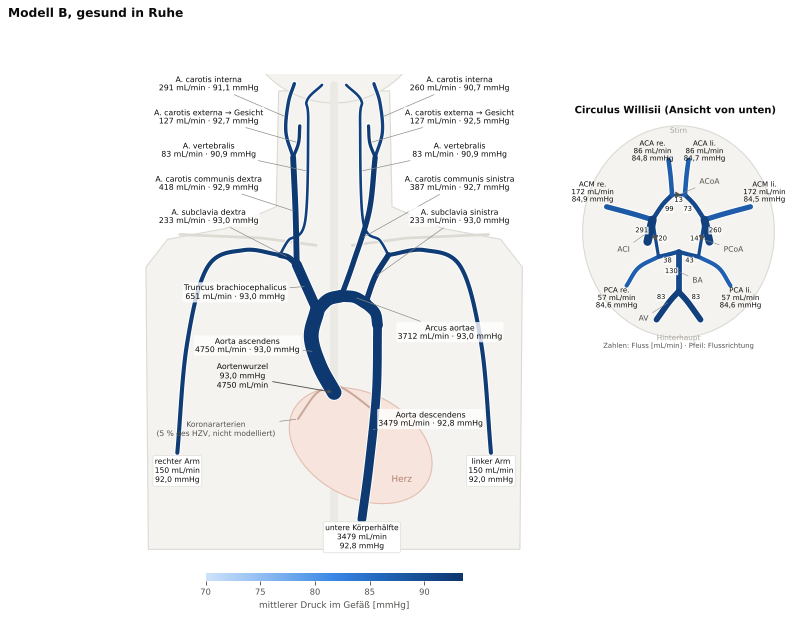

In [8]:
demo.gesund()

## 2 Karotisstenose: Der Circulus Willisii entscheidet
Gleiche Stenose, zwei Menschen: einmal mit vollständigem Circulus, einmal ohne Verbindungsgefäße.

KAROTISSTENOSE links 90 %, Circulus Willisii vollständig
  Fluss in der A. carotis interna links: 4 mL/min (1 % von gesund)
  Fluss ins Mediagebiet links:           172 mL/min (100 % von gesund)
  Druck am Ende der A. cerebri media:    77,9 mmHg (gesund 84,5)
  Umgehung über die A. communicans anterior: 197 mL/min
  Umgehung über die A. communicans posterior links: 57 mL/min


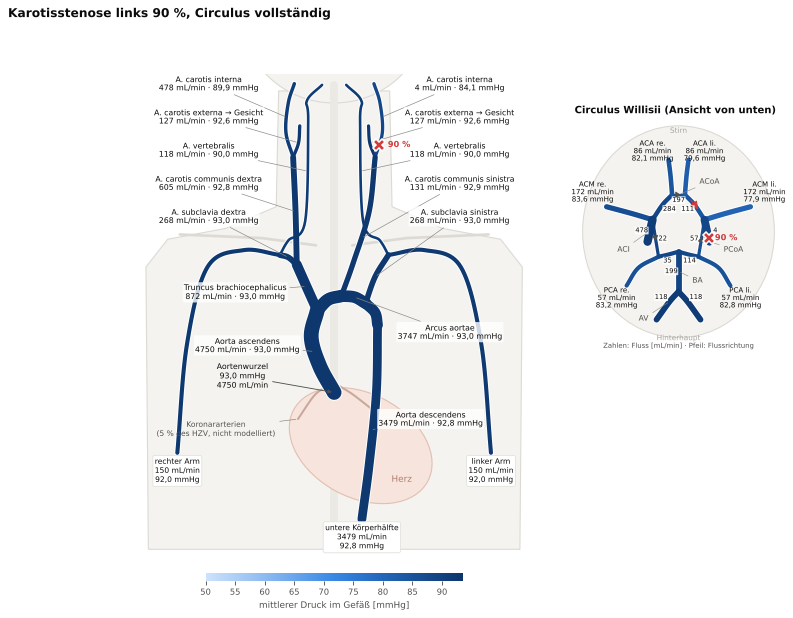

In [9]:
demo.karotisstenose(0.9, "vollständig")

KAROTISSTENOSE links 90 %, Circulus Willisii ohne Verbindungen
  Fluss in der A. carotis interna links: 25 mL/min (10 % von gesund)
  Fluss ins Mediagebiet links:           17 mL/min (10 % von gesund)
  Druck am Ende der A. cerebri media:    10,4 mmHg (gesund 84,5)


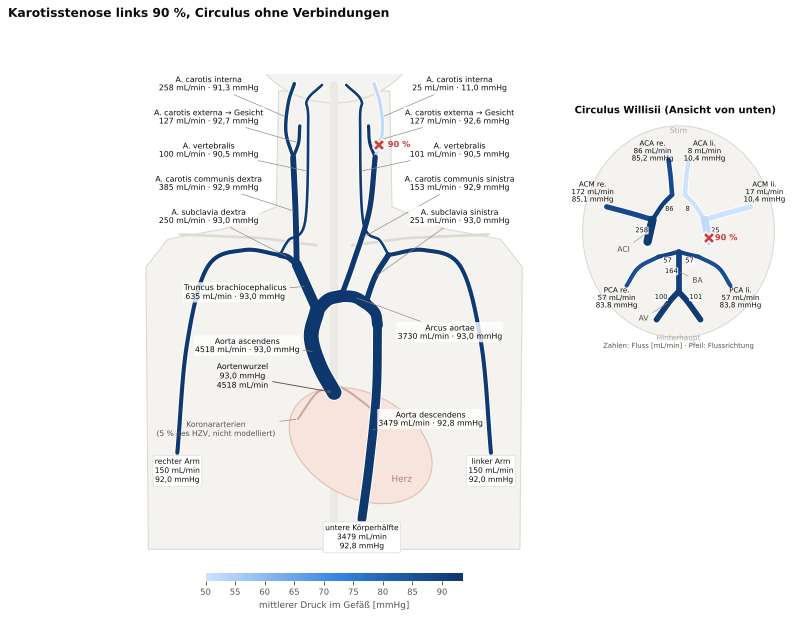

In [10]:
demo.karotisstenose(0.9, "ohne Verbindungen")

## 3 Kleinhirn und Hirnstamm: Basilarisstenose
Mit offenen Aa. communicantes posteriores bleibt alles versorgt; ohne sie fallen AICA, SCA und Pons unter die
Funktionsschwelle. Die PICA entspringt vor der Engstelle.

BASILARISSTENOSE 80 %, Circulus Willisii vollständig
  Fluss in der A. basilaris: 10 mL/min (gesund 130)
  über die Aa. communicantes posteriores nach hinten: 154 mL/min
  Druck in der Mitte der A. basilaris (Aa. pontis): 85,1 mmHg (gesund 90,1)
  Kleinhirn/Hirnstamm: PICA re. 100 %  PICA li. 100 %  AICA re. 100 %  AICA li. 100 %  SCA re. 100 %  SCA li. 100 %  Pons 100 %  PCA re. 100 %  PCA li. 100 %


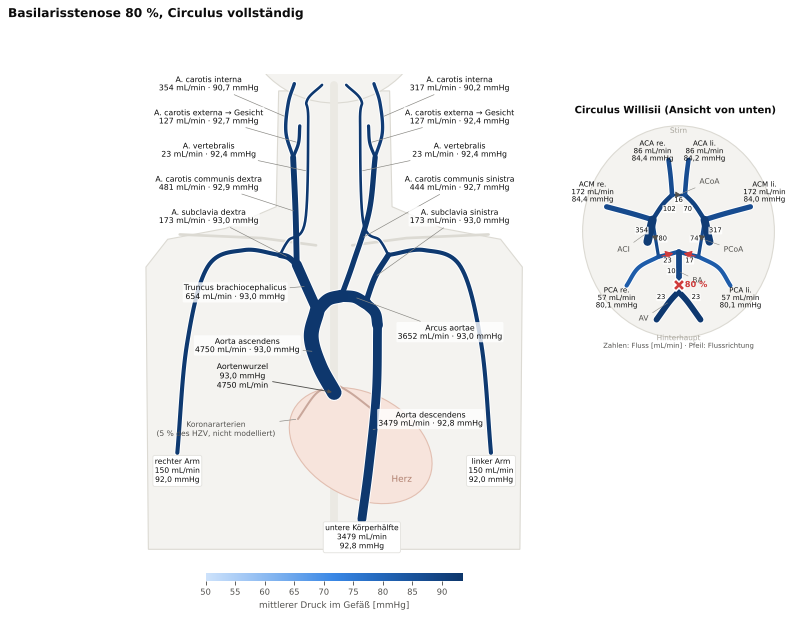

In [11]:
demo.basilarisstenose(0.8, "vollständig")

BASILARISSTENOSE 80 %, Circulus Willisii ohne PCoA
  Fluss in der A. basilaris: 51 mL/min (gesund 164)
  Druck in der Mitte der A. basilaris (Aa. pontis): 23,5 mmHg (gesund 89,5)
  Kleinhirn/Hirnstamm: PICA re. 100 %  PICA li. 100 %  AICA re. 33 %  AICA li. 33 %  SCA re. 33 %  SCA li. 33 %  Pons 34 %  PCA re. 31 %  PCA li. 31 %


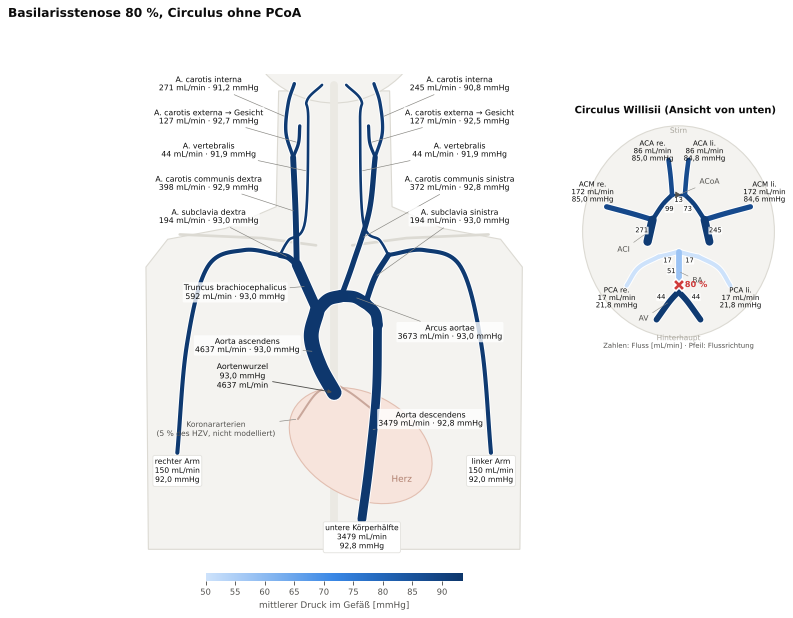

In [12]:
demo.basilarisstenose(0.8, "ohne PCoA")

## 4 Subclavian-Steal: meist stumm, außer die Umwege fehlen

SUBCLAVIA-STENOSE links 90 %, Armarbeit links, Circulus vollständig
  A. vertebralis links: −285 mL/min -> RÜCKWÄRTS: der Arm holt sich Blut über die A. vertebralis (gesund 83)
  A. basilaris:         −17 mL/min (gesund 130)
  Druckunterschied zwischen den Armen: 18,9 mmHg
  Kleinhirn/Hirnstamm: PICA re. 100 %  PICA li. 100 %  AICA re. 100 %  AICA li. 100 %  SCA re. 100 %  SCA li. 100 %  Pons 100 %  PCA re. 100 %  PCA li. 100 %


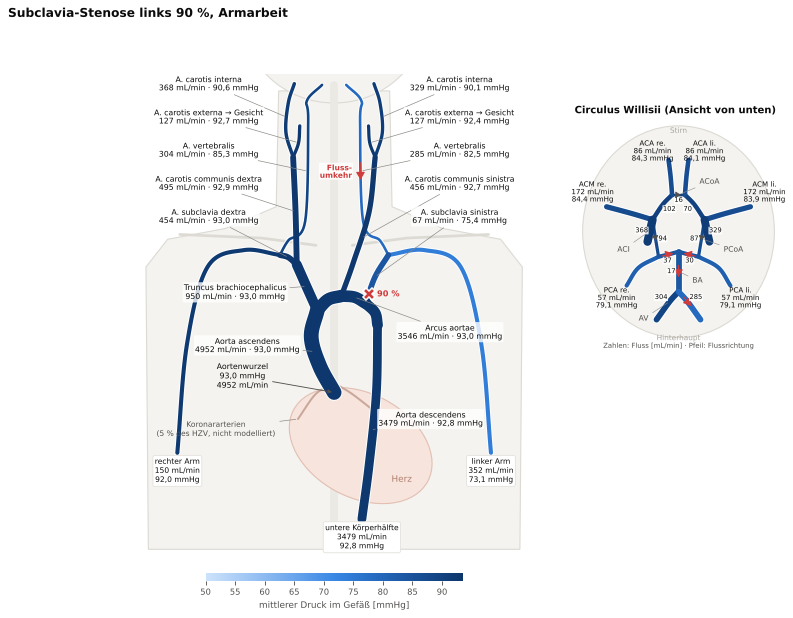

In [13]:
demo.subclavian_steal(0.9, armarbeit=True)

SUBCLAVIA-STENOSE links 95 %, Armarbeit links, Circulus ohne PCoA, A. vertebralis rechts hypoplastisch
  A. vertebralis links: −143 mL/min -> RÜCKWÄRTS: der Arm holt sich Blut über die A. vertebralis (gesund 172)
  A. basilaris:         102 mL/min (gesund 164)
  Druckunterschied zwischen den Armen: 55,4 mmHg
  Kleinhirn/Hirnstamm: PICA re. 75 %  PICA li. 65 %  AICA re. 65 %  AICA li. 65 %  SCA re. 65 %  SCA li. 65 %  Pons 67 %  PCA re. 60 %  PCA li. 60 %


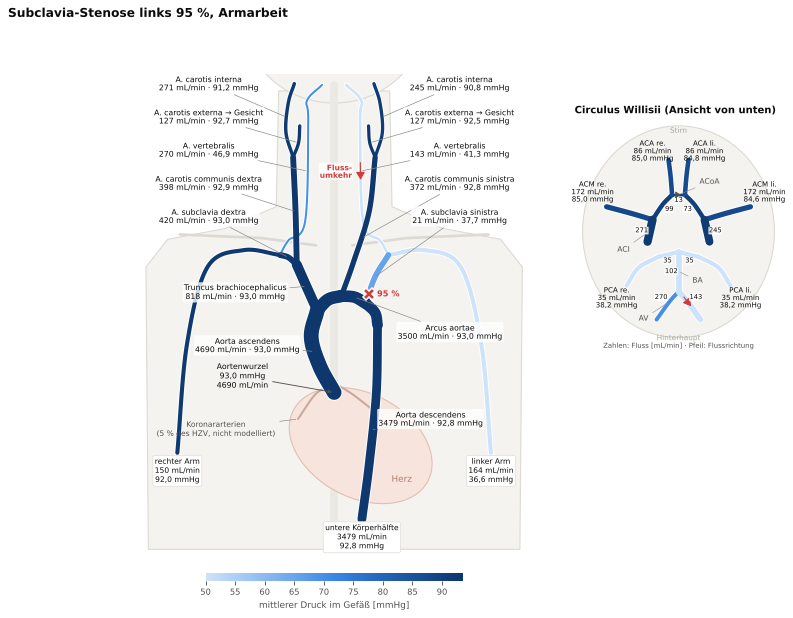

In [14]:
demo.subclavian_steal(0.95, armarbeit=True, circulus="ohne PCoA", hypoplasie=True)

## 5 Nierenarterienstenose: Angiotensin II hält die GFR – der ACE-Hemmer nimmt es weg

In [15]:
demo.nierenarterienstenose(0.65)

NIERENARTERIENSTENOSE 65 % (eine Niere)
                                Druck dahinter   Nierenblutfluss         GFR
  gesund                               92 mmHg         550 mL/min   62,5 mL/min
  mit Angiotensin II                   73 mmHg         297 mL/min   41,6 mL/min
  unter ACE-Hemmer                     60 mmHg         396 mL/min    2,6 mL/min


## 6 Selbst ausprobieren
Eigene Werte einsetzen, zum Beispiel `demo.karotisstenose(0.7, "ohne ACoA")`, `demo.basilarisstenose(0.75, "ohne PCoA")`,
`demo.subclavian_steal(0.8, armarbeit=False)` oder `demo.nierenarterienstenose(0.5)`.

**Mit Schiebereglern:** Zelle ausführen, Engstelle, Grad und Variante wählen, dann auf *Run Interact* klicken.
Python rechnet das Netzwerk dabei jedes Mal neu (wenige Sekunden).

In [ ]:
demo.regler()

## 7 Die interaktive Seite direkt in Colab
Dieselbe Seite wie `Interaktive_Demo.html`: Netzplan mit allen Gefäßnamen, Fluss und Druck, Schnellwahl für die
Vorstellung, Kleinhirn und Hirnstamm, Niere mit Körperbild (Aorta abdominalis, beide Nieren). Python rechnet dafür alle Stenosegrade von 0 bis 97 % für jede Variante
einmal vorab (**etwa 2–3 Minuten**); danach reagiert die Seite sofort auf jeden Regler.

1. Die nächsten vier Zellen ausführen (Ordner anlegen, Seitenvorlage und Rechenprogramm schreiben, Werte rechnen).
2. Die Seite erscheint unter der Zelle „Seite anzeigen“.
3. Mit der letzten Zelle lässt sich die fertige Seite herunterladen und ohne Internet im Browser öffnen.

In [16]:
import os
os.makedirs("interaktiv", exist_ok=True)

In [17]:
%%writefile interaktiv/vorlage.html
<!DOCTYPE html>
<html lang="de">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Hämodynamik im Widerstandsnetzwerk – interaktive Simulation</title>
<style>
/* Hämodynamik im Widerstandsnetzwerk – interaktive Simulation, Wahlfach Computational Physiology, Florian Winter
   Stil: ruhig und hell wie eine Apple-Produktseite. Systemschrift (SF Pro auf dem Mac), Apple-Grau als Grund,
   weiße Flächen, Apple-Blau als einziger Akzent; Gelb, Orange und Rot nur für den Durchblutungsstatus.
   Aufbau jedes Reiters: Überschrift → großes Bild → Steuerleiste aus Milchglas → Werte. */
:root{color-scheme:light dark;
--bg:light-dark(#f5f5f7,#000000);--panel:light-dark(#ffffff,#1c1c1e);--panel2:light-dark(#f5f5f7,#2c2c2e);
--fill:light-dark(#e8e8ed,#3a3a3c);--seg-an:light-dark(#ffffff,#636366);--line:light-dark(#d2d2d7,#424245);--hair:light-dark(rgba(0,0,0,.08),rgba(255,255,255,.12));
--ink:light-dark(#1d1d1f,#f5f5f7);--ink2:light-dark(#6e6e73,#a1a1a6);--muted:light-dark(#86868b,#8e8e93);
--accent:light-dark(#0071e3,#2997ff);--blue:light-dark(#0071e3,#0a84ff);--green:light-dark(#34c759,#30d158);
--yellow:light-dark(#ffcc00,#ffd60a);--orange:light-dark(#ff9500,#ff9f0a);--red:light-dark(#ff3b30,#ff453a);--grey:light-dark(#8e8e93,#98989d);
--aqua:light-dark(#30b0c7,#40c8e0);--band:light-dark(#eef4fc,#10233d);
--haut:light-dark(#f6f3f0,#202023);--haut-rand:light-dark(#dcd4cc,#3d3d42);
--knochen:light-dark(#ece7e1,#2b2b2f);--knochen-rand:light-dark(#d3cbc2,#4a4a50);
--hirn:light-dark(#f8ecea,#2d2427);--hirn2:light-dark(#f1dfdb,#382c30);--hirn-rand:light-dark(#e2c9c3,#5a4448);
--organ:light-dark(#f6e0d9,#3a2b2e);--organ-rand:light-dark(#e2bcb0,#6e4c55);
--glas:light-dark(rgba(255,255,255,.8),rgba(28,28,30,.8));--tint:.4;
--probe:light-dark(#000,#fff);
--s1:light-dark(#2a78d6,#3987e5);--s2:light-dark(#eb6834,#d95926);--s3:light-dark(#1baf7a,#199e70);--s4:light-dark(#eda100,#c98500);--s5:light-dark(#e87ba4,#d55181);
--schrift:-apple-system,BlinkMacSystemFont,"SF Pro Text","SF Pro Display","Helvetica Neue","Segoe UI",Roboto,Arial,sans-serif}
:root[data-theme=light]{color-scheme:light}
:root[data-theme=dark]{color-scheme:dark}
@media (prefers-color-scheme:dark){:root:not([data-theme=light]){--tint:.5}}
:root[data-theme=dark]{--tint:.5}
*{box-sizing:border-box;min-width:0}
[hidden]{display:none !important}
html,body{margin:0}
body{background:var(--bg);color:var(--ink);font:17px/1.47 var(--schrift);letter-spacing:-.01em;-webkit-font-smoothing:antialiased;overflow-x:clip}
button,input{font-family:inherit;letter-spacing:inherit}
:focus-visible{outline:3px solid color-mix(in srgb,var(--accent) 60%,transparent);outline-offset:2px;border-radius:8px}

/* Navigation */
.nav{position:sticky;top:0;z-index:20;background:var(--glas);-webkit-backdrop-filter:saturate(180%) blur(20px);backdrop-filter:saturate(180%) blur(20px);border-bottom:1px solid var(--hair)}
.nav-innen{max-width:1400px;margin:0 auto;padding:0 max(3vw,16px);min-height:56px;display:flex;align-items:center;justify-content:space-between;gap:16px}
.marke{font-size:19px;font-weight:600;letter-spacing:-.02em;white-space:nowrap}
.tabs{display:flex;gap:2px;background:var(--fill);border-radius:999px;padding:3px;overflow-x:auto;scrollbar-width:none}
.tabs::-webkit-scrollbar{display:none}
.tab{appearance:none;border:0;background:none;color:var(--ink);font-size:14px;font-weight:500;padding:0 16px;min-height:34px;border-radius:999px;cursor:pointer;white-space:nowrap;transition:background .2s,box-shadow .2s}
.tab:hover{color:var(--ink)}
.tab[aria-selected=true]{background:var(--seg-an);box-shadow:0 1px 2px rgba(0,0,0,.06),0 2px 8px rgba(0,0,0,.1);font-weight:600}

/* Seite */
main{max-width:1400px;margin:0 auto;padding:0 max(3vw,16px) 40px}
.ansicht{display:flex;flex-direction:column;gap:20px}
.ansicht[hidden]{display:none}
.held{text-align:center;padding:64px 0 28px;max-width:860px;margin:0 auto}
.held h1{font-size:clamp(34px,4.6vw,56px);line-height:1.07;letter-spacing:-.028em;font-weight:700;margin:0;text-wrap:balance}
.held p{font-size:clamp(18px,1.7vw,21px);line-height:1.42;color:var(--ink2);margin:14px auto 0;max-width:40em;text-wrap:balance}

.karte{background:var(--panel);border-radius:18px;padding:22px 24px}
.figkarte{background:var(--panel);border-radius:28px;padding:22px 26px 20px;display:flex;flex-direction:column;gap:12px}
.figkopf{display:flex;flex-wrap:wrap;justify-content:space-between;align-items:flex-start;gap:10px 20px}
.figkopf h2,.karte h2{font-size:21px;line-height:1.24;font-weight:600;letter-spacing:-.018em;margin:0}
.unterzeile{color:var(--ink2);font-size:14px;margin:3px 0 0}
.pille{display:inline-flex;align-items:center;gap:8px;background:var(--panel2);border-radius:999px;padding:7px 14px 7px 12px;font-size:14px;font-weight:500;white-space:nowrap}
.punkt{width:10px;height:10px;border-radius:50%;flex:none;display:inline-block}
.fig{position:relative}
.fig>svg{position:absolute;inset:0;width:100%;height:100%;overflow:visible;touch-action:none}
.fig.kopffig{height:clamp(640px,calc(100vh - 410px),980px)}
.fig.koerperfig{height:clamp(600px,calc(100vh - 320px),820px)}
.fig.baumfig{height:730px}
.fig.schaltfig{height:282px}
.scrollfig{overflow-x:auto;overflow-y:hidden;scrollbar-width:thin}
.scrollfig>.fig{min-width:860px}
.scrollfig>.fig.schaltfig{min-width:1040px}
.rechnung{display:grid;grid-template-columns:minmax(0,7fr) minmax(0,5fr);gap:32px;border-top:1px solid var(--hair);padding-top:18px}
.rechnung h3{font-size:17px;font-weight:600;margin:0 0 14px;letter-spacing:-.015em}
.schritte{list-style:none;margin:0;padding:0;display:flex;flex-direction:column;gap:16px}
.schritte li{display:grid;grid-template-columns:26px minmax(0,1fr);gap:12px;align-items:start}
.schritte .nr{width:26px;height:26px;border-radius:50%;background:var(--panel2);display:grid;place-items:center;font-size:13px;font-weight:600;color:var(--ink2)}
.schritte b{display:block;font-weight:600;font-size:14px;line-height:1.3;margin-bottom:4px}
.schritte .hinweis{margin-top:4px}
.formel{font-size:15px;line-height:2.4;font-variant-numeric:tabular-nums}
.formel>*{vertical-align:middle}
.formel sub{font-size:.72em;vertical-align:-.3em}
.formel .erg{font-weight:600;color:var(--accent)}
.bruch{display:inline-flex;flex-direction:column;align-items:center;vertical-align:middle;line-height:1.3;margin:0 3px}
.bruch>span:first-child{border-bottom:1.5px solid currentColor;padding:0 5px 3px}
.bruch>span:last-child{padding:3px 5px 0}
table.analog{width:100%;border-collapse:collapse}
.analog th,.analog td{text-align:left;font-size:13.5px;line-height:1.4;color:var(--ink);padding:8px 12px 8px 0;vertical-align:top;border-bottom:1px solid var(--hair)}
.analog th{font-size:12px;font-weight:500;color:var(--ink2)}
.analog td:first-child{font-weight:500;width:46%}
.analog tbody tr:last-child td{border-bottom:0}
table.ebenen{width:100%;border-collapse:collapse;font-variant-numeric:tabular-nums;min-width:660px}
.ebenen th{font-weight:500;font-size:12px;line-height:1.3;color:var(--ink2);text-align:right;padding:0 8px 8px;vertical-align:bottom}
.ebenen th:first-child,.ebenen td:first-child{text-align:left;padding-left:12px}
.ebenen td{padding:9px 8px;border-top:1px solid var(--hair);text-align:right;font-size:14px;white-space:nowrap}
.ebenen tbody tr[data-e]{cursor:pointer}
.ebenen tbody tr[data-e]:hover td{background:color-mix(in srgb,var(--band) 60%,transparent)}
.ebenen td:first-child{font-weight:600}
.ebenen tr.an td{background:var(--band)}
.ebenen tr.an td:first-child{box-shadow:inset 3px 0 0 var(--accent)}
.ebenen tr.summe td{font-weight:600;border-top:1.5px solid var(--line)}
.ebenen .anteil{display:grid;grid-template-columns:3.4em minmax(60px,1fr) 3em;gap:8px;align-items:center}
.ebenen .anteil b{font-weight:600;text-align:right}
.ebenen .anteil small{color:var(--ink2);font-size:12.5px;text-align:right}
.fig.nephfig{height:330px}
.kurve .fig{height:270px}
.kurve .fig.halb{height:205px}
.figfuss{display:flex;flex-direction:column;gap:10px;border-top:1px solid var(--hair);padding-top:14px}
.einsicht{margin:0;font-size:15px;line-height:1.5;color:var(--ink);max-width:110ch}
.einsicht b{font-weight:600}
.leg{display:flex;flex-wrap:wrap;gap:8px 22px;color:var(--ink2);font-size:13px;align-items:center}
.leg>span{display:inline-flex;align-items:center;gap:7px}
.leg i{display:inline-block;width:22px;height:0;border-top:3px solid;border-radius:2px}
.leg i.gestr{border-top-style:dashed}
.leg .fl{width:12px;height:12px;border-radius:4px;border:0}
.skala{display:inline-block;width:110px;height:8px;border-radius:4px}
.hinweis{color:var(--ink2);font-size:13px;line-height:1.45;margin:0}
.hinweis.tipp{font-size:14px;color:var(--ink);background:var(--panel2);border-radius:12px;padding:10px 12px}
.hinweis.tipp b{font-weight:600}

/* Steuerleiste aus Milchglas */
.dock{position:sticky;bottom:10px;z-index:10;background:var(--glas);-webkit-backdrop-filter:saturate(180%) blur(22px);backdrop-filter:saturate(180%) blur(22px);
  border:1px solid var(--hair);border-radius:22px;box-shadow:0 10px 36px rgba(0,0,0,.10),0 1px 3px rgba(0,0,0,.05);padding:12px 18px 13px;display:flex;flex-direction:column;gap:10px}
.dockzeile{display:flex;flex-wrap:wrap;gap:12px 24px;align-items:flex-end}
.dockzeile>.feld{flex:0 1 auto}
.dockzeile>.regelfeld{flex:1 1 130px;min-width:130px}
.feld{display:flex;flex-direction:column;gap:7px}
.feldname{font-size:12.5px;font-weight:500;color:var(--ink2);line-height:16px}
.zeile{display:flex;align-items:baseline;justify-content:space-between;gap:4px 12px;line-height:16px}
.zeile label{font-size:12.5px;font-weight:500;color:var(--ink2)}
.wert{font-size:17px;font-weight:600;letter-spacing:-.02em;white-space:nowrap;font-variant-numeric:tabular-nums;color:var(--ink)}
.wert.aus{color:var(--muted);font-weight:500}
.regelfeld input[type=range]{height:34px}
.gruppe{display:contents}
.figtext{flex:1 1 520px;max-width:900px}
.figtext .einsicht{margin-top:5px;color:var(--ink2);font-size:14px;line-height:1.45}
.figtext .einsicht b{color:var(--ink)}
.chips{display:flex;gap:8px;overflow-x:auto;scrollbar-width:none;padding:1px}
.chips::-webkit-scrollbar{display:none}
.chips button{flex:none;appearance:none;border:0;background:var(--fill);color:var(--ink);font-size:14px;font-weight:500;padding:0 16px;min-height:34px;border-radius:999px;cursor:pointer;transition:background .15s,color .15s}
.chips button:hover{background:color-mix(in srgb,var(--fill) 80%,var(--ink) 8%)}
.chips button[aria-pressed=true]{background:var(--accent);color:#fff}

/* Segmentierte Auswahl */
.seg{display:inline-flex;flex-wrap:wrap;gap:2px;background:var(--fill);border-radius:10px;padding:2px;align-self:flex-start;max-width:100%}
.seg button{appearance:none;border:0;background:transparent;color:var(--ink);font-size:13.5px;font-weight:500;padding:0 10px;min-height:30px;border-radius:8px;cursor:pointer;white-space:nowrap;transition:background .15s,box-shadow .15s}
.seg button[aria-pressed=true]{background:var(--seg-an);box-shadow:0 1px 1px rgba(0,0,0,.04),0 2px 6px rgba(0,0,0,.12);font-weight:600}
.seg button{min-height:30px}

/* Schalter */
.dockzeile .zeile label{white-space:nowrap}
.schalter{display:flex;align-items:center;justify-content:space-between;gap:12px;font-size:13px;line-height:1.2;color:var(--ink);cursor:pointer;white-space:nowrap}
.schalter[aria-disabled=true]{opacity:.4;cursor:default}
.switch{appearance:none;position:relative;flex:none;width:44px;height:26px;border-radius:13px;border:0;background:var(--fill);cursor:pointer;transition:background .2s}
.switch::after{content:"";position:absolute;top:2px;left:2px;width:22px;height:22px;border-radius:50%;background:#fff;box-shadow:0 2px 4px rgba(0,0,0,.2),0 0 0 .5px rgba(0,0,0,.04);transition:transform .2s}
.switch[aria-checked=true]{background:var(--green)}
.switch[aria-checked=true]::after{transform:translateX(18px)}
.switch:disabled{cursor:default}
.schalterliste{display:flex;flex-direction:column;gap:7px;flex:0 0 auto}

/* Regler */
input[type=range]{width:100%;height:28px;margin:0;background:none;-webkit-appearance:none;appearance:none;cursor:pointer}
input[type=range]::-webkit-slider-runnable-track{height:4px;border-radius:2px;background:linear-gradient(90deg,var(--accent) var(--p,50%),var(--line) var(--p,50%))}
input[type=range]::-moz-range-track{height:4px;border-radius:2px;background:var(--line)}
input[type=range]::-moz-range-progress{height:4px;border-radius:2px;background:var(--accent)}
input[type=range]::-webkit-slider-thumb{-webkit-appearance:none;width:24px;height:24px;border-radius:50%;background:#fff;border:0;margin-top:-10px;box-shadow:0 0 0 .5px rgba(0,0,0,.06),0 3px 8px rgba(0,0,0,.16),0 3px 1px rgba(0,0,0,.05)}
input[type=range]::-moz-range-thumb{width:24px;height:24px;border-radius:50%;background:#fff;border:0;box-shadow:0 0 0 .5px rgba(0,0,0,.06),0 3px 8px rgba(0,0,0,.16)}
input[type=range]:disabled{cursor:default;opacity:.35}

/* Werte und Karten darunter */
.raster{display:grid;grid-template-columns:minmax(0,7fr) minmax(0,5fr);gap:20px;align-items:start}
.spalte{display:flex;flex-direction:column;gap:20px}
.kopfzeile{display:flex;flex-wrap:wrap;justify-content:space-between;align-items:baseline;gap:6px 16px;margin-bottom:14px}
.werte{display:grid;grid-template-columns:repeat(3,minmax(0,1fr));gap:20px}
.w{background:var(--panel);border-radius:18px;padding:20px 22px}
.w b{display:block;font-weight:500;color:var(--ink2);font-size:14px;line-height:1.3}
.zahl{font-size:clamp(34px,3.4vw,48px);font-weight:600;line-height:1.1;white-space:nowrap;letter-spacing:-.03em;margin-top:6px;font-variant-numeric:tabular-nums}
.zahl small{font-size:19px;font-weight:500;color:var(--ink2);margin-left:5px;letter-spacing:-.01em}
.w span{display:block;color:var(--ink2);font-size:14px;margin-top:4px}
.w.akzent .zahl{color:var(--orange)}
.kurve{display:flex;flex-direction:column;gap:10px}
.tip{position:absolute;pointer-events:none;background:color-mix(in srgb,var(--ink) 92%,transparent);color:var(--panel);font-size:13px;line-height:1.45;border-radius:10px;padding:7px 11px;white-space:nowrap;opacity:0;transition:opacity .12s;z-index:2;box-shadow:0 6px 20px rgba(0,0,0,.18)}
.tip i{display:inline-block;width:10px;height:3px;vertical-align:middle;margin-right:6px;border-radius:2px}

/* Durchblutungstabelle */
.vt{width:100%;border-collapse:collapse;font-variant-numeric:tabular-nums;table-layout:fixed}
.vt col.c-n{width:9.4em}.vt col.c-s{width:3.2em}.vt col.c-f{width:56%}.vt col.c-d{width:44%}
.vt th{font-weight:500;font-size:12px;color:var(--ink2);padding:0 0 6px;text-align:left;vertical-align:bottom;white-space:nowrap}
.vt th b{font-weight:600;font-size:13px;color:var(--ink)}
.vt td{padding:5px 0;vertical-align:middle;font-size:14px}
.vt td.gn{padding-right:8px;color:var(--ink);line-height:1.25;font-weight:500}
.vt td.sd{font-size:12.5px;color:var(--ink2)}
.vt tr.grp td{font-weight:600;font-size:13px;color:var(--ink2);padding:16px 0 4px}
.vt tbody tr.grp:first-child td{padding-top:4px}
.vt tr.erste td{border-top:1px solid var(--hair)}
.vt td.f{padding-right:16px}
.zelle{display:grid;align-items:center;column-gap:8px}
.zelle.f{grid-template-columns:2.7em minmax(20px,1fr) 3em}
.zelle.d{grid-template-columns:2.1em minmax(20px,1fr) 2.4em}
.zelle b{font-weight:600;text-align:right;color:var(--ink)}
.zelle small{font-size:12.5px;color:var(--ink2);text-align:right;white-space:nowrap}
.mb{position:relative;height:6px;background:var(--fill);border-radius:3px}
.mb i{position:absolute;left:0;top:0;bottom:0;border-radius:3px}
.mb .s60{position:absolute;top:-4px;bottom:-4px;width:2px;margin-left:-1px;background:var(--red);border-radius:1px}
.vt .kurz{display:none}
.stat{display:flex;flex-wrap:wrap;gap:6px 18px;margin-top:14px;font-size:13px;color:var(--ink2)}
.stat span{display:inline-flex;align-items:center;gap:6px}
.stat i{display:inline-block;width:10px;height:10px;border-radius:50%}

/* Symptome */
.sym{margin:0;padding:0;list-style:none;display:flex;flex-direction:column;gap:12px}
.sym li{display:grid;grid-template-columns:12px minmax(0,1fr);gap:10px;font-size:15px;line-height:1.45}
.sym li .punkt{margin-top:6px}
.sym b{font-weight:600}

/* Vergleichstabelle Niere */
table.liste{border-collapse:collapse;width:100%;font-size:15px}
.liste th,.liste td{text-align:right;padding:10px 8px;border-bottom:1px solid var(--hair);white-space:nowrap}
.liste th:first-child,.liste td:first-child{text-align:left;white-space:normal;padding-left:12px}
.liste th{font-weight:500;color:var(--ink2);font-size:12px;white-space:normal;line-height:1.3;vertical-align:bottom}
.liste td{font-size:20px;font-weight:600;letter-spacing:-.02em;font-variant-numeric:tabular-nums;color:var(--ink2)}
.liste td:first-child{font-size:15px;font-weight:500;letter-spacing:-.01em}
.liste tr.an td{color:var(--ink)}
.liste tr.an td:first-child{box-shadow:inset 3px 0 0 var(--accent);color:var(--accent);font-weight:600}
.liste tbody tr:last-child td{border-bottom:0}

/* SVG */
svg text{font-family:var(--schrift);font-size:12.5px;fill:var(--ink2);paint-order:stroke;stroke:var(--panel);stroke-width:4px;stroke-linejoin:round;letter-spacing:-.005em;font-variant-numeric:tabular-nums}
svg text.t{fill:var(--ink);font-weight:600}
svg text.nm{font-size:13px;fill:var(--ink);font-weight:600}
svg text.wt{font-size:12px}
svg tspan.abk{fill:var(--muted);font-weight:500}
svg tspan.dr{fill:var(--muted)}
svg text.leise{fill:var(--muted);font-size:12px}
svg text.a,svg tspan.a{fill:var(--accent);font-weight:600}
svg text.gross{font-size:24px;font-weight:600;fill:var(--ink);letter-spacing:-.02em}
svg text.proz{font-size:15px;font-weight:700;fill:var(--ink);stroke-width:3.5px}
svg text.pil{fill:var(--panel);font-weight:600;font-size:13px;stroke:none}
svg text.seite{fill:var(--muted);font-size:12px;font-weight:500}
svg.kompakt text.wt{font-size:11px}
svg.kompakt text.nm{font-size:11.5px}
svg .gitter{stroke:var(--hair);stroke-width:1}
svg .achse{stroke:var(--line);stroke-width:1}
.scroll{overflow-x:auto}
footer{max-width:1400px;margin:0 auto;padding:8px max(3vw,16px) 48px;color:var(--ink2);font-size:12.5px;line-height:1.5}
footer p{margin:0 0 4px;max-width:110ch}
footer a,.vorspann a:not(.ref),.hinweis a{color:var(--accent);text-decoration:none}
footer a:hover,.vorspann a:not(.ref):hover,.hinweis a:hover{text-decoration:underline}

/* Quellen */
.quellen{width:100%;max-width:1000px;margin:0 auto;display:flex;flex-direction:column;gap:20px}
.quellen .karte{padding:26px 30px 24px}
.quellen h2 .leise{font-size:15px;font-weight:500;color:var(--ink2);margin-left:6px;letter-spacing:-.01em}
.quellen h3{font-size:14px;font-weight:600;color:var(--ink2);margin:22px 0 2px;letter-spacing:-.005em}
.vorspann{font-size:15px;line-height:1.55;color:var(--ink2);margin:8px 0 0;max-width:78ch}
.vorspann b{color:var(--ink);font-weight:600}
.quellen .scroll{margin-top:16px}
.belege{margin-top:8px}
.beleg{display:grid;grid-template-columns:minmax(0,1fr) minmax(11em,15em);gap:4px 28px;padding:11px 0;border-top:1px solid var(--hair);font-size:15px;line-height:1.45}
.belege .beleg:first-child{border-top:0}
.beleg sub{font-size:.72em}
.beleg .wer{font-size:14px;color:var(--ink2)}
a.ref{color:var(--accent);text-decoration:none;font-weight:500;white-space:nowrap}
a.ref:hover{text-decoration:underline}
.punkte{margin:6px 0 0;padding:0 0 0 1.1em;max-width:86ch;font-size:15px;line-height:1.5;display:flex;flex-direction:column;gap:6px}
.punkte li::marker{color:var(--muted)}
.literatur{list-style:none;margin:14px -8px 0;padding:0}
.nw{white-space:nowrap}
.literatur li{padding:10px 8px 10px calc(1.4em + 8px);text-indent:-1.4em;border-top:1px solid var(--hair);font-size:14px;line-height:1.5;scroll-margin:90px 0 120px;border-radius:8px;transition:background-color .8s}
.literatur li:first-child{border-top:0}
.literatur li.blink{background:var(--band);transition:none}
.literatur a{color:var(--accent);text-decoration:none;white-space:nowrap}
.literatur a:hover{text-decoration:underline}
.zitat{margin:10px 0 0;font-size:15px;line-height:1.55;background:var(--panel2);border-radius:12px;padding:12px 14px;overflow-wrap:anywhere}
table.herkunft{min-width:860px}
.herkunft td.her{white-space:normal;text-align:left;color:var(--ink2);font-size:13px;line-height:1.4;min-width:18em}
.herkunft th.her{text-align:left}
.herkunft td small{display:block;font-size:12px;color:var(--ink2);font-weight:400}
.raster.gleich{grid-template-columns:minmax(0,1fr) minmax(0,1fr);max-width:1000px;width:100%;margin:0 auto}
#probe{color:var(--probe);position:absolute;width:0;height:0;overflow:hidden}

@media (max-width:1260px),(max-height:680px){.dock{position:static}}
@media (max-width:900px){.rechnung{grid-template-columns:minmax(0,1fr)}.raster{grid-template-columns:minmax(0,1fr)}.werte{grid-template-columns:minmax(0,1fr)}.dock{position:static}
  .dockzeile{flex-direction:column;align-items:stretch}.dockzeile>.feld,.dockzeile>.regelfeld{flex:none;min-width:0}.seg{display:flex;align-self:stretch}.seg button{flex:1 1 auto}
  .fig.kopffig{height:auto;min-height:420px}.fig.koerperfig{height:640px}.held{padding:40px 0 16px}}
@media (max-width:520px){.marke{display:none}.nav-innen{justify-content:center}.pille{white-space:normal}}
@media (max-width:600px){.figkarte{padding:18px 14px 16px;border-radius:22px}.karte{padding:18px 16px}.marke{font-size:17px}.tab{padding:0 12px}
  .vt .lang{display:none}.vt .kurz{display:inline}.vt col.c-n{width:3.4em}.vt col.c-s{width:1.8em}.zelle.f{grid-template-columns:2.3em minmax(14px,1fr) 3.1em}.zelle.d{grid-template-columns:1.9em minmax(14px,1fr) 2.1em}.vt td.f{padding-right:8px}
  .liste thead{display:none}.liste tr{display:grid;padding-block:8px;border-bottom:1px solid var(--hair)}.liste td{display:flex;justify-content:space-between;gap:12px;border:0;padding:3px 0;font-size:17px}.liste td::before{content:attr(data-l);font-size:13px;font-weight:400;color:var(--ink2)}.liste td:first-child{padding-left:0}.liste td:first-child::before{content:none}.liste tr.an td:first-child{box-shadow:none}}
@media (max-width:900px){.raster.gleich{grid-template-columns:minmax(0,1fr)}}
@media (max-width:700px){.beleg{grid-template-columns:minmax(0,1fr);gap:2px}.quellen .karte{padding:20px 18px}.literatur li{padding-right:4px}.literatur a{white-space:normal;overflow-wrap:anywhere}}
@media (max-width:420px){.tab{padding:0 10px;font-size:13.5px}}
@media (max-width:700px){table.herkunft{min-width:0}.herkunft thead{display:none}
  .herkunft tr{display:grid;grid-template-columns:repeat(2,minmax(0,1fr));column-gap:20px;padding:12px 0 10px;border-top:1px solid var(--hair)}
  .herkunft tbody tr:first-child{border-top:0}
  .herkunft td,.herkunft td:first-child{border:0;padding:2px 0;text-align:left;display:flex;justify-content:space-between;align-items:baseline;gap:8px;font-size:14px}
  .herkunft td::before{content:attr(data-l);color:var(--ink2);font-size:12.5px;white-space:normal}
  .herkunft td>span{text-align:right}
  .herkunft td:first-child{grid-column:1/-1;font-size:16px;padding-bottom:4px}
  .herkunft td:first-child::before,.herkunft td.her::before{content:none}
  .herkunft td.her{grid-column:1/-1;display:block;min-width:0;margin-top:6px}}
@media (prefers-reduced-motion:reduce){*{transition:none !important}}
</style>
</head>
<body>
<span id="probe"></span>
<header class="nav">
  <div class="nav-innen">
    <div class="marke">Hämodynamik</div>
    <nav class="tabs" role="tablist" aria-label="Experimente">
      <button class="tab" role="tab" id="tab-grundidee" data-tab="grundidee">Grundidee</button>
      <button class="tab" role="tab" id="tab-gehirn" data-tab="gehirn">Kopf und Gehirn</button>
      <button class="tab" role="tab" id="tab-niere" data-tab="niere">Niere</button>
      <button class="tab" role="tab" id="tab-quellen" data-tab="quellen">Quellen</button>
    </nav>
  </div>
</header>

<main>
<!-- ======================================================= Grundidee -->
<section class="ansicht" id="v-grundidee" role="tabpanel" aria-labelledby="tab-grundidee">
  <div class="held">
    <h1>Der Widerstand sitzt in den kleinen Gefäßen.</h1>
    <p>Vom Herzen durch Arterien, Arteriolen, Kapillaren, Venolen und Venen zurück: sieben Ebenen in Reihe, jede aus vielen gleichen Gefäßen nebeneinander. Verändere ihren Radius und sieh, wo der Druck verloren geht.</p>
  </div>
  <div class="figkarte">
    <div class="figkopf">
      <div class="figtext"><h2 id="i-titel">Ruhe</h2><p class="einsicht" id="i-fuss"></p></div>
      <div class="pille" id="i-status"></div>
    </div>
    <div class="scrollfig"><div class="fig baumfig"><svg id="i-bild" role="img" aria-label="Gefäßbaum von der Aorta bis zu den Hohlvenen mit Druck, Gesamtquerschnitt und Geschwindigkeit je Ebene"></svg></div></div>
    <div class="figfuss">
      <div class="leg"><span>Druck <span class="skala" id="i-skala"></span>0 bis 100 mmHg</span><span><i class="gestr" style="border-color:var(--grey)"></i>Ruhe zum Vergleich</span><span>Auf eine Ebene klicken: Rechenweg im Schaltbild darunter</span></div>
    </div>
  </div>
  <div class="figkarte">
    <div class="figkopf"><div class="figtext"><h2>So rechnet das Modell: ein Schaltbild wie in der Elektrotechnik</h2><p class="einsicht">Der Druckunterschied treibt den Fluss wie eine Spannung den Strom. Jede Ebene ist ein Widerstand, die Ebenen liegen in Reihe, die Gefäße einer Ebene parallel.</p></div></div>
    <div class="scrollfig"><div class="fig schaltfig"><svg id="i-schalt" role="img" aria-label="Schaltbild des Kreislaufs: Herz als Pumpe, sieben Widerstände in Reihe"></svg></div></div>
    <div class="rechnung">
      <div class="rechenweg" id="i-rechnung"></div>
      <div class="analogie"><h3>Elektrotechnik und Kreislauf</h3><table class="analog" id="i-analogie">
        <thead><tr><th>Elektrotechnik</th><th>Kreislauf</th></tr></thead><tbody>
        <tr><td>Spannung U</td><td>Druckdifferenz ΔP</td></tr>
        <tr><td>Strom I</td><td>Fluss Q (Herzzeitvolumen)</td></tr>
        <tr><td>Widerstand eines Drahts</td><td>R = 8 · η · L / (π · r⁴)</td></tr>
        <tr><td>Ohmsches Gesetz U = R · I</td><td>ΔP = R · Q</td></tr>
        <tr><td>Reihe: R = R₁ + R₂ + …</td><td>Aorta, Arterien, Arteriolen … hintereinander</td></tr>
        <tr><td>Parallel: 1/R = 1/R₁ + 1/R₂ + …</td><td>N gleiche Gefäße einer Ebene: R = R₁ / N</td></tr>
        <tr><td>Spannungsteiler</td><td>Druckabfall je Ebene im Verhältnis ihrer Widerstände</td></tr>
        </tbody></table></div>
    </div>
  </div>
  <div class="dock">
    <div class="chips" id="i-preset" role="group" aria-label="Schnellwahl">
      <button data-p="100|100|100|100|100|45">Ruhe</button>
      <button data-p="50|100|100|100|100|45">Arterien halb so weit</button>
      <button data-p="100|80|100|100|100|45">Arteriolen 20 % enger</button>
      <button data-p="100|120|100|100|100|45">Arteriolen 20 % weiter</button>
      <button data-p="100|100|100|100|100|25">Anämie, Hämatokrit 25 %</button>
      <button data-p="100|100|100|100|100|60">Polyglobulie, Hämatokrit 60 %</button>
    </div>
    <div class="dockzeile">
      <div class="feld regelfeld"><div class="zeile"><label for="i-arterien">Radius Arterien</label><span class="wert" id="i-arterien-w"></span></div><input type="range" id="i-arterien" min="50" max="150" step="5" value="100"></div>
      <div class="feld regelfeld"><div class="zeile"><label for="i-arteriolen">Radius Arteriolen</label><span class="wert" id="i-arteriolen-w"></span></div><input type="range" id="i-arteriolen" min="50" max="150" step="5" value="100"></div>
      <div class="feld regelfeld"><div class="zeile"><label for="i-kapillaren">Radius Kapillaren</label><span class="wert" id="i-kapillaren-w"></span></div><input type="range" id="i-kapillaren" min="50" max="150" step="5" value="100"></div>
      <div class="feld regelfeld"><div class="zeile"><label for="i-venolen">Radius Venolen</label><span class="wert" id="i-venolen-w"></span></div><input type="range" id="i-venolen" min="50" max="150" step="5" value="100"></div>
      <div class="feld regelfeld"><div class="zeile"><label for="i-venen">Radius Venen</label><span class="wert" id="i-venen-w"></span></div><input type="range" id="i-venen" min="50" max="150" step="5" value="100"></div>
      <div class="feld regelfeld"><div class="zeile"><label for="i-hkt">Hämatokrit</label><span class="wert" id="i-hkt-w"></span></div><input type="range" id="i-hkt" min="20" max="65" step="1" value="45"></div>
    </div>
  </div>
  <div class="werte" id="i-werte"></div>
  <div class="raster">
    <div class="karte">
      <div class="kopfzeile"><h2>Jede Ebene im Überblick</h2><span class="hinweis">Zeile anklicken für den Rechenweg</span></div>
      <div class="scroll"><table class="ebenen" id="i-tab"></table></div>
      <p class="hinweis" style="margin-top:12px">Anzahl aus dem Gesamtquerschnitt je Abschnitt (Guyton und Hall); Durchmesser und Länge von Arteriolen und Kapillaren nach Kurbel et al. (2009). Ruhetonus der Arteriolen, Anteil durchbluteter Kapillaren und Zahl der Venolen sind so bestimmt, dass in Ruhe 5 L/min fließen und der Kapillardruck von 35 auf 15 mmHg fällt. Woher jede Zahl stammt, zeigt der Reiter <a href="#quellen">Quellen</a>.</p>
    </div>
    <div class="karte kurve">
      <h2>Wie stark wirkt der Radius jeder Ebene?</h2>
      <p class="hinweis">Fluss, wenn nur der Radius dieser Ebene verändert wird; die anderen Regler bleiben, wie sie sind.</p>
      <div class="fig"><svg id="i-kurve"></svg><div class="tip"></div></div>
      <div class="leg" id="i-kurve-leg"></div>
    </div>
  </div>
</section>

<!-- ======================================================= Gehirn -->
<section class="ansicht" id="v-gehirn" role="tabpanel" aria-labelledby="tab-gehirn" hidden>
  <div class="held">
    <h1>Wann wird eine Engstelle kritisch?</h1>
    <p>Stelle eine Stenose ein und sieh, wie der Circulus Willisii und die Autoregulation Großhirn, Kleinhirn und Hirnstamm weiter versorgen, oder wo die Umwege fehlen.</p>
  </div>
  <div class="figkarte">
    <div class="figkopf">
      <div class="figtext"><h2 id="g-titel">Normalzustand</h2><p class="einsicht" id="g-fuss"></p></div>
      <div class="pille" id="g-status"></div>
    </div>
    <div class="fig kopffig"><svg id="g-netz" role="img" aria-label="Anatomische Skizze von Kopf, Hals und Gehirn von vorn mit allen Arterien, Fluss und Druck"></svg></div>
    <div class="figfuss">
      <p class="hinweis tipp" id="g-tipp" hidden></p>
      <div class="leg"><span>Druck <span class="skala" id="g-skala"></span><span id="g-skala-t"></span></span><span><i style="border-color:var(--ink2)"></i>Linienbreite = Fluss</span><span><b style="color:var(--accent)">▲ ▼</b> mehr oder weniger Fluss als normal</span><span><i class="fl" style="background:var(--yellow)"></i>vermindert</span><span><i class="fl" style="background:var(--orange)"></i>Funktionsausfall</span><span><i class="fl" style="background:var(--red)"></i>Infarktgefahr</span></div>
    </div>
  </div>
  <div class="dock" id="g-dock">
    <div class="chips" id="g-preset" role="group" aria-label="Schnellwahl">
      <button data-p="keine|vollständig|0|0|">Normal, ohne Engstelle</button>
      <button data-p="karotis|vollständig|0|0|90">Karotis 90 %</button>
      <button data-p="karotis|ohne Verbindungen|0|0|90">… ohne Verbindungen</button>
      <button data-p="subclavia|vollständig|0|1|90">Steal bei Armarbeit</button>
      <button data-p="subclavia|ohne PCoA|1|1|95">Steal ohne Umwege</button>
      <button data-p="basilaris|ohne PCoA|0|0|80">Basilaris 80 %, ohne PCoA</button>
    </div>
    <div class="dockzeile">
      <div class="feld"><span class="feldname">Engstelle</span>
        <div class="seg" id="g-eng"><button data-v="keine">keine</button><button data-v="karotis">Karotis</button><button data-v="subclavia">Subclavia</button><button data-v="basilaris">Basilaris</button></div></div>
      <div class="feld regelfeld" id="g-grad-box"><div class="zeile"><label for="g-grad" id="g-grad-l">Stenosegrad</label><span class="wert" id="g-grad-w"></span></div>
        <input type="range" id="g-grad" min="0" max="97" step="1" value="90"></div>
      <div class="feld"><span class="feldname">Circulus Willisii</span>
        <div class="seg" id="g-var"><button data-v="vollständig">vollständig</button><button data-v="ohne ACoA">ohne ACoA</button><button data-v="ohne PCoA">ohne PCoA</button><button data-v="ohne Verbindungen">ohne Verbindungen</button></div></div>
      <div class="schalterliste">
        <label class="schalter" id="g-hypo-z"><span>Vertebralis rechts hypoplastisch</span><button class="switch" role="switch" id="g-hypo" aria-checked="false" aria-label="Rechte A. vertebralis hypoplastisch (2 mm)"></button></label>
        <label class="schalter" id="g-arb-z"><span>Armarbeit links</span><button class="switch" role="switch" id="g-arb" aria-checked="true" aria-label="Armarbeit links"></button></label>
      </div>
    </div>
  </div>
  <div class="raster">
    <div class="karte versorgung">
      <div class="kopfzeile"><h2>Durchblutung der Hirngebiete</h2><span class="hinweis">Fluss und Perfusionsdruck je Gebiet</span></div>
      <div id="g-gebiete"></div>
      <p class="hinweis" style="margin-top:12px">Roter Strich: 60 mmHg. Darunter ist die Autoregulation erschöpft und der Fluss fällt; ein gelber Druckbalken heißt, dass weniger als 10 mmHg Reserve bleiben. Prozent = Fluss im Vergleich zum Normalzustand, Δ = Druckänderung. Schwellen nach Astrup et al. (1981): unter etwa 40 % fallen Nervenzellen funktionell aus, unter etwa 20 % droht ein Infarkt.</p>
    </div>
    <div class="spalte">
      <div class="karte" id="g-symptome-k">
        <div class="kopfzeile"><h2 id="g-symptome-t">Was zu erwarten wäre</h2></div>
        <div id="g-symptome"></div>
      </div>
      <div class="karte kurve" id="g-kurve-k">
        <h2 id="g-kurve-t">Schlechtestes Gebiet über dem Stenosegrad</h2>
        <p class="hinweis">Oben der Fluss, unten der Perfusionsdruck. Solange der Druck über 60 mmHg bleibt, hält die Autoregulation den Fluss bei 100 %, auch bei hohem Stenosegrad.</p>
        <div class="fig halb"><svg id="g-kurve"></svg><div class="tip"></div></div>
        <div class="fig halb"><svg id="g-kurve2"></svg><div class="tip"></div></div>
        <div class="leg" id="g-kurve-leg"></div>
      </div>
    </div>
  </div>
</section>

<!-- ======================================================= Niere -->
<section class="ansicht" id="v-niere" role="tabpanel" aria-labelledby="tab-niere" hidden>
  <div class="held">
    <h1>Die Niere hält ihre Filtration.</h1>
    <p>Autoregulation und Angiotensin II halten die GFR konstant, über einen weiten Blutdruckbereich und hinter einer Stenose der A. renalis. Ein ACE-Hemmer nimmt die zweite Stufe weg.</p>
  </div>
  <div class="raster">
    <div class="figkarte">
      <div class="figkopf"><div><h2 id="n-k-titel">Aorta und Nieren im Körper</h2><p class="unterzeile">Modell C von vorn: Aorta, Aorta abdominalis und beide Nieren</p></div></div>
      <div class="fig koerperfig"><svg id="n-koerper" role="img" aria-label="Körperbild von Modell C: Aorta, Aorta abdominalis, Nierenarterien und Nieren mit Fluss und Druck"></svg></div>
      <div class="figfuss">
        <div class="leg"><span>Druck <span class="skala" id="n-skala"></span><span id="n-skala-t"></span></span><span><i style="border-color:var(--ink2)"></i>Linienbreite = Fluss</span><span><b style="color:var(--accent)">▲ ▼</b> mehr oder weniger Fluss als in Ruhe</span></div>
        <p class="hinweis" id="n-k-h">Der Regler setzt den Druck am Abgang der Nierenarterien; an der Aortenwurzel liegt er um den Druckverlust in der Aorta höher. Die Stenose sitzt in der linken A. renalis, die rechte Niere bleibt gesund.</p>
      </div>
    </div>
    <div class="spalte">
      <div class="figkarte">
        <div class="figkopf"><div><h2 id="n-titel">Ein Nephron im Modell</h2></div></div>
        <div class="fig nephfig"><svg id="n-bild" aria-label="Schema eines Nephrons mit Vas afferens, Glomerulum und Vas efferens"></svg></div>
        <p class="hinweis" id="n-bild-h"></p>
      </div>
      <div class="karte scroll"><table id="n-tab" class="liste"></table></div>
    </div>
  </div>
  <div class="dock">
    <div class="dockzeile">
      <div class="feld"><span class="feldname">Experiment</span>
        <div class="seg" id="n-modus"><button data-v="druck">Blutdruck</button><button data-v="stenose">Nierenarterienstenose</button></div></div>
      <div class="gruppe" id="n-druck-box">
        <div class="feld regelfeld"><div class="zeile"><label for="n-P">Mitteldruck an der Nierenarterie</label><span class="wert" id="n-P-w"></span></div>
          <input type="range" id="n-P" min="40" max="200" step="1" value="150"></div>
        <div class="feld"><span class="feldname">Regelung</span><div class="seg" id="n-ar"><button data-v="AR">mit Autoregulation</button><button data-v="passiv">ohne Autoregulation</button></div></div></div>
      <div class="gruppe" id="n-sten-box" hidden>
        <div class="feld regelfeld"><div class="zeile"><label for="n-grad">Stenose der A. renalis sinistra</label><span class="wert" id="n-grad-w"></span></div>
          <input type="range" id="n-grad" min="0" max="85" step="1" value="65"></div>
        <div class="feld"><span class="feldname">Regelung</span><div class="seg" id="n-var"><button data-v="ATII">mit Angiotensin II</button><button data-v="ACE">unter ACE-Hemmer</button><button data-v="passiv">ohne Regelung</button></div></div></div>
    </div>
  </div>
  <div class="karte kurve">
    <div class="kopfzeile" style="margin-bottom:0"><h2 id="n-kurve-t"></h2><div class="seg" id="n-mass"></div></div>
    <div class="fig"><svg id="n-kurve"></svg><div class="tip"></div></div>
    <div class="leg" id="n-kurve-leg"></div>
  </div>
</section>

<!-- ======================================================= Quellen -->
<section class="ansicht" id="v-quellen" role="tabpanel" aria-labelledby="tab-quellen" hidden>
  <div class="held">
    <h1>Datengrundlage und Quellen.</h1>
    <p>Herkunft aller Parameter, mit denen das Modell rechnet und kalibriert wird. Werte ohne Literaturbeleg sind als Annahme oder Kalibrierung ausgewiesen.</p>
  </div>
  <div class="quellen">

  <div class="karte">
    <h2>Gefäßzahlen der Grundidee: Herleitung und Prüfung</h2>
    <p class="vorspann">Die Anzahl je Ebene ist keine Zählung. Sie folgt aus dem Gesamtquerschnitt A eines Abschnitts und dem Durchmesser D eines einzelnen Gefäßes: <span class="nw">N = A / (π · (D/2)²)</span>. Dieselbe Herleitung verwenden <a class="ref" href="#quellen" data-ref="kurbel2009">Kurbel et al. 2009</a>.</p>
    <div class="scroll"><table class="ebenen herkunft" id="q-gefaesse"></table></div>
    <p class="vorspann" id="q-pruef"></p>
    <p class="vorspann" id="q-pruef2"></p>
  </div>

  <div class="karte">
    <h2>Körperkreislauf <span class="leise">Reiter Grundidee</span></h2>
    <div class="belege">
      <div class="beleg"><div>Gesamtquerschnitt je Abschnitt: Aorta 2,5, Arterien 20, Arteriolen 40, Kapillaren 2500, Venolen 250, Venen 80, Hohlvenen 8&nbsp;cm²</div><div class="wer"><a class="ref" href="#quellen" data-ref="guyton2011">Guyton und Hall 2011</a></div></div>
      <div class="beleg"><div>Arteriolen 30&nbsp;µm weit und 1,5&nbsp;mm lang, Kapillaren 5&nbsp;µm weit und 0,7&nbsp;mm lang</div><div class="wer"><a class="ref" href="#quellen" data-ref="kurbel2009">Kurbel et al. 2009</a></div></div>
      <div class="beleg"><div>Herzzeitvolumen in Ruhe 5&nbsp;L/min; Kapillardruck 35&nbsp;mmHg am arteriellen Ende</div><div class="wer"><a class="ref" href="#quellen" data-ref="guyton2011">Guyton und Hall 2011</a></div></div>
      <div class="beleg"><div>Kapillardruck 15&nbsp;mmHg am venösen Ende, gewählt zwischen den Lehrbuchwerten 10&nbsp;mmHg (venöses Ende) und 17&nbsp;mmHg (funktioneller Mitteldruck)</div><div class="wer"><a class="ref" href="#quellen" data-ref="guyton2011">Guyton und Hall 2011</a></div></div>
      <div class="beleg"><div>Viskosität von Vollblut 4,0&nbsp;mPa·s bei 45&nbsp;% Hämatokrit und ihr Anstieg mit dem Hämatokrit</div><div class="wer"><a class="ref" href="#quellen" data-ref="pries1992">Pries et al. 1992</a>; <a class="ref" href="#quellen" data-ref="reymond2009">Reymond et al. 2009</a></div></div>
    </div>
  </div>

  <div class="karte">
    <h2>Kopf und Gehirn</h2>
    <h3>Gefäße</h3>
    <div class="belege">
      <div class="beleg"><div>Durchmesser und Längen von Aorta, Truncus brachiocephalicus, Karotiden, Subclavia und Vertebralarterien</div><div class="wer"><a class="ref" href="#quellen" data-ref="reymond2009">Reymond et al. 2009</a></div></div>
      <div class="beleg"><div>Aorta ascendens, Circulus Willisii und A.&nbsp;basilaris</div><div class="wer"><a class="ref" href="#quellen" data-ref="alastruey2007">Alastruey et al. 2007</a></div></div>
      <div class="beleg"><div>Abstände der Abgänge am Aortenbogen</div><div class="wer"><a class="ref" href="#quellen" data-ref="casteleyn2010">Casteleyn et al. 2010</a></div></div>
      <div class="beleg"><div>Kleinhirnarterien: PICA 1,66, AICA 1,26, SCA 1,56&nbsp;mm weit; Lage ihrer Abgänge an A.&nbsp;vertebralis und A.&nbsp;basilaris</div><div class="wer"><a class="ref" href="#quellen" data-ref="akgun2013">Akgun et al. 2013</a></div></div>
      <div class="beleg"><div>SCA 19&nbsp;mm lang; Aa.&nbsp;pontis als 13 Perforatoren zu je 0,4&nbsp;mm</div><div class="wer"><a class="ref" href="#quellen" data-ref="reyessoto2024">Reyes-Soto et al. 2024</a></div></div>
      <div class="beleg"><div>Hypoplastische A.&nbsp;vertebralis: Durchmesser höchstens 2&nbsp;mm</div><div class="wer"><a class="ref" href="#quellen" data-ref="park2007">Park et al. 2007</a></div></div>
    </div>
    <h3>Flüsse in Ruhe</h3>
    <div class="belege">
      <div class="beleg"><div>Gehirn 717&nbsp;mL/min, davon 72&nbsp;% über die Karotiden und 28&nbsp;% über die Vertebralarterien; je A.&nbsp;cerebri posterior 8&nbsp;%</div><div class="wer"><a class="ref" href="#quellen" data-ref="zarrinkoob2015">Zarrinkoob et al. 2015</a></div></div>
      <div class="beleg"><div>A.&nbsp;carotis externa 127&nbsp;mL/min je Seite: Kopf gesamt 949 minus Gehirn 695&nbsp;mL/min, auf zwei Seiten verteilt</div><div class="wer"><a class="ref" href="#quellen" data-ref="zhao2007">Zhao et al. 2007</a></div></div>
      <div class="beleg"><div>Kleinhirn und Hirnstamm 86&nbsp;mL/min (28&nbsp;% minus 2 × 8&nbsp;% von 717&nbsp;mL/min), auf PICA, AICA, SCA und Aa.&nbsp;pontis verteilt mit Fluss proportional zu D³</div><div class="wer"><a class="ref" href="#quellen" data-ref="zarrinkoob2015">Zarrinkoob et al. 2015</a>; <a class="ref" href="#quellen" data-ref="murray1926">Murray 1926</a></div></div>
    </div>
    <h3>Regelung, Schwellen und Klinik</h3>
    <div class="belege">
      <div class="beleg"><div>Autoregulation des Gehirns zwischen 60 und 150&nbsp;mmHg</div><div class="wer"><a class="ref" href="#quellen" data-ref="paulson1990">Paulson et al. 1990</a></div></div>
      <div class="beleg"><div>Funktionsausfall unter etwa 40&nbsp;%, Infarktgefahr unter etwa 20&nbsp;% der normalen Durchblutung</div><div class="wer"><a class="ref" href="#quellen" data-ref="astrup1981">Astrup et al. 1981</a></div></div>
      <div class="beleg"><div>Operation symptomatischer Karotisstenosen nützt ab 70&nbsp;%</div><div class="wer"><a class="ref" href="#quellen" data-ref="nascet1991">NASCET 1991</a></div></div>
      <div class="beleg"><div>Subclavian-Steal meist ohne Beschwerden, sonst Schwindel bei Armarbeit</div><div class="wer"><a class="ref" href="#quellen" data-ref="osiro2012">Osiro et al. 2012</a></div></div>
      <div class="beleg"><div>Versorgungsgebiete und Zeichen bei Ausfall von PICA, AICA, SCA, Aa.&nbsp;pontis und A.&nbsp;cerebri posterior</div><div class="wer"><a class="ref" href="#quellen" data-ref="trepel2021">Trepel 2021</a>; <a class="ref" href="#quellen" data-ref="lee2009">Lee 2009</a></div></div>
    </div>
  </div>

  <div class="karte">
    <h2>Niere</h2>
    <h3>Gefäße</h3>
    <div class="belege">
      <div class="beleg"><div>A.&nbsp;renalis 5,4&nbsp;mm weit; links 34,8&nbsp;mm, rechts 41,4&nbsp;mm lang</div><div class="wer"><a class="ref" href="#quellen" data-ref="lauder2018">Lauder et al. 2018</a></div></div>
      <div class="beleg"><div>Radien und Anzahlen der Interlobar-, Arkuat- und Interlobulararterien</div><div class="wer"><a class="ref" href="#quellen" data-ref="rahmani2025">Rahmani et al. 2025</a></div></div>
      <div class="beleg"><div>Vas afferens 21,5&nbsp;µm, Vas efferens 15,9&nbsp;µm weit</div><div class="wer"><a class="ref" href="#quellen" data-ref="neal2018">Neal et al. 2018</a></div></div>
      <div class="beleg"><div>900 000 Nephrone je Niere</div><div class="wer"><a class="ref" href="#quellen" data-ref="bertram2011">Bertram et al. 2011</a></div></div>
    </div>
    <h3>Filtration, Regelung und Sollwerte</h3>
    <div class="belege">
      <div class="beleg"><div>Scheinbare Viskosität abhängig von Gefäßdurchmesser und Hämatokrit (Fåhræus-Lindqvist-Effekt)</div><div class="wer"><a class="ref" href="#quellen" data-ref="pries1992">Pries et al. 1992</a></div></div>
      <div class="beleg"><div>Filtration entlang der Glomerulumkapillare</div><div class="wer"><a class="ref" href="#quellen" data-ref="deen1972">Deen et al. 1972</a></div></div>
      <div class="beleg"><div>Kolloidosmotischer Druck <span class="nw">π = 2,1 C + 0,16 C² + 0,009 C³</span> (C in g/dL)</div><div class="wer"><a class="ref" href="#quellen" data-ref="landis1963">Landis und Pappenheimer 1963</a></div></div>
      <div class="beleg"><div>Sollwerte in Ruhe: Glomerulumdruck 60&nbsp;mmHg, peritubulär 13&nbsp;mmHg, Bowman-Kapsel 18&nbsp;mmHg; Nierenblutfluss 1100 und GFR 125&nbsp;mL/min für beide Nieren, im Modell je Niere 550 und 62,5&nbsp;mL/min</div><div class="wer"><a class="ref" href="#quellen" data-ref="guyton2011">Guyton und Hall 2011</a></div></div>
      <div class="beleg"><div>Autoregulation der Niere zwischen 80 und 180&nbsp;mmHg</div><div class="wer"><a class="ref" href="#quellen" data-ref="carlstroem2015">Carlström et al. 2015</a></div></div>
      <div class="beleg"><div>Nierenversagen unter ACE-Hemmer bei beidseitiger Nierenarterienstenose</div><div class="wer"><a class="ref" href="#quellen" data-ref="hricik1983">Hricik et al. 1983</a></div></div>
    </div>
  </div>

  <div class="karte">
    <h2>Stenosemodell und Software <span class="leise">alle Reiter</span></h2>
    <div class="belege">
      <div class="beleg"><div>Druckverlust an der Engstelle <span class="nw">ΔP = a · Q + b · Q²</span> mit der Turbulenzkonstante <span class="nw">K<sub>t</sub> = 1,52</span></div><div class="wer"><a class="ref" href="#quellen" data-ref="young1973">Young und Tsai 1973</a></div></div>
      <div class="beleg"><div>Wirksame Länge der Engstelle <span class="nw">L<sub>a</sub> = 0,83 L + 1,64 D<sub>s</sub></span></div><div class="wer"><a class="ref" href="#quellen" data-ref="seeley1976">Seeley und Young 1976</a></div></div>
      <div class="beleg"><div>Gerechnet in Python mit NumPy und SciPy; diese Seite zeichnet und rechnet mit JavaScript ohne weitere Bibliotheken</div><div class="wer"><a class="ref" href="#quellen" data-ref="harris2020">Harris et al. 2020</a>; <a class="ref" href="#quellen" data-ref="virtanen2020">Virtanen et al. 2020</a></div></div>
    </div>
  </div>

  <div class="karte">
    <h2>Annahmen und Kalibrierung</h2>
    <p class="vorspann">Diese Werte stehen in keiner Quelle. Sie sind gerundete Annahmen oder werden so bestimmt, dass das Modell gemessene Ruhewerte trifft.</p>
    <h3>Annahmen</h3>
    <ul class="punkte">
      <li>Mitteldruck 93&nbsp;mmHg an der Aortenwurzel und 5&nbsp;mmHg an allen Ausgängen, übliche Ruhewerte.</li>
      <li>Grundidee: Arterien 1&nbsp;mm und Venen 2&nbsp;mm weit, beide 100&nbsp;mm lang; Aorta 400&nbsp;mm und Hohlvenen 300&nbsp;mm lang; Venolen so weit und lang wie Arteriolen.</li>
      <li>Arm und Schultergürtel 150&nbsp;mL/min je Seite.</li>
      <li>PICA und AICA je 20&nbsp;mm lang.</li>
      <li>Aorta abdominalis in Modell C 60&nbsp;mm lang und 12,45&nbsp;mm weit.</li>
      <li>Niere: Glomerulumkapillaren 9&nbsp;µm weit; Maße der Venen, Venolen und peritubulären Kapillaren.</li>
      <li>Ideale Autoregulation mit festen Grenzen, stationärer Fluss mit Mitteldruck, starre Gefäße.</li>
    </ul>
    <h3>Kalibrierte Größen</h3>
    <ul class="punkte">
      <li>Der Widerstand jedes Organbetts in Kopf, Armen und unterer Körperhälfte: so, dass im gesunden Zustand der gemessene Ruhefluss fließt.</li>
      <li id="q-kal-grund"></li>
      <li>Niere: Tonus der Arteriolen und Filtrationskoeffizient, so dass Glomerulumdruck, peritubulärer Druck, Nierenblutfluss und GFR die Sollwerte treffen; dazu 76,5&nbsp;mmHg am Eingang des Vas afferens.</li>
      <li>Plasmaviskosität 1,25&nbsp;mPa·s: so gewählt, dass Vollblut in großen Gefäßen 4,0&nbsp;mPa·s hat.</li>
    </ul>
  </div>

  <div class="karte">
    <h2>Literaturverzeichnis</h2>
    <p class="vorspann">Autoren, Jahr, Zeitschrift, Band, Seiten und DOI sowie die übernommenen Zahlenwerte wurden am 23.11.2026 mit den Verlagsseiten, PubMed Central und den Abstracts abgeglichen.</p>
    <ol class="literatur">
      <li id="lit-akgun2013">Akgun V, Battal B, Bozkurt Y, Oz O, Hamcan S, Sari S, Akgun H. Normal anatomical features and variations of the vertebrobasilar circulation and its branches: an analysis with 64-detector row CT and 3T MR angiographies. ScientificWorldJournal. 2013;2013:620162. <a href="https://doi.org/10.1155/2013/620162" rel="noopener">doi:10.1155/2013/620162</a></li>
      <li id="lit-alastruey2007">Alastruey J, Parker KH, Peiró J, Byrd SM, Sherwin SJ. Modelling the circle of Willis to assess the effects of anatomical variations and occlusions on cerebral flows. J Biomech. 2007;40(8):1794–1805. <a href="https://doi.org/10.1016/j.jbiomech.2006.07.008" rel="noopener">doi:10.1016/j.jbiomech.2006.07.008</a></li>
      <li id="lit-astrup1981">Astrup J, Siesjö BK, Symon L. Thresholds in cerebral ischemia – the ischemic penumbra. Stroke. 1981;12(6):723–725. <a href="https://doi.org/10.1161/01.STR.12.6.723" rel="noopener">doi:10.1161/01.STR.12.6.723</a></li>
      <li id="lit-bertram2011">Bertram JF, Douglas-Denton RN, Diouf B, Hughson MD, Hoy WE. Human nephron number: implications for health and disease. Pediatr Nephrol. 2011;26(9):1529–1533. <a href="https://doi.org/10.1007/s00467-011-1843-8" rel="noopener">doi:10.1007/s00467-011-1843-8</a></li>
      <li id="lit-carlstroem2015">Carlström M, Wilcox CS, Arendshorst WJ. Renal autoregulation in health and disease. Physiol Rev. 2015;95(2):405–511. <a href="https://doi.org/10.1152/physrev.00042.2012" rel="noopener">doi:10.1152/physrev.00042.2012</a></li>
      <li id="lit-casteleyn2010">Casteleyn C, Trachet B, Van Loo D, et al. Validation of the murine aortic arch as a model to study human vascular diseases. J Anat. 2010;216(5):563–571. <a href="https://doi.org/10.1111/j.1469-7580.2010.01220.x" rel="noopener">doi:10.1111/j.1469-7580.2010.01220.x</a></li>
      <li id="lit-deen1972">Deen WM, Robertson CR, Brenner BM. A model of glomerular ultrafiltration in the rat. Am J Physiol. 1972;223(5):1178–1183. <a href="https://doi.org/10.1152/ajplegacy.1972.223.5.1178" rel="noopener">doi:10.1152/ajplegacy.1972.223.5.1178</a></li>
      <li id="lit-guyton2011">Hall JE. Guyton and Hall textbook of medical physiology. 12. Aufl. Philadelphia: Saunders Elsevier; 2011. Kap. 14, 16, 20, 26 und 27. <span class="nw">ISBN 978-1-4160-4574-8</span></li>
      <li id="lit-harris2020">Harris CR, Millman KJ, van der Walt SJ, et al. Array programming with NumPy. Nature. 2020;585(7825):357–362. <a href="https://doi.org/10.1038/s41586-020-2649-2" rel="noopener">doi:10.1038/s41586-020-2649-2</a></li>
      <li id="lit-hricik1983">Hricik DE, Browning PJ, Kopelman R, Goorno WE, Madias NE, Dzau VJ. Captopril-induced functional renal insufficiency in patients with bilateral renal-artery stenoses or renal-artery stenosis in a solitary kidney. N Engl J Med. 1983;308(7):373–376. <a href="https://doi.org/10.1056/NEJM198302173080706" rel="noopener">doi:10.1056/NEJM198302173080706</a></li>
      <li id="lit-kurbel2009">Kurbel S, Gros M, Marić S. Complexity of human circulation design: tips for students. Adv Physiol Educ. 2009;33(2):130–131. <a href="https://doi.org/10.1152/advan.90217.2008" rel="noopener">doi:10.1152/advan.90217.2008</a></li>
      <li id="lit-landis1963">Landis EM, Pappenheimer JR. Exchange of substances through the capillary walls. In: Hamilton WF, Dow P, Hrsg. Handbook of physiology, Section 2: Circulation, Vol. II. Washington, DC: American Physiological Society; 1963:961–1034.</li>
      <li id="lit-lauder2018">Lauder L, Ewen S, Tzafriri AR, et al. Renal artery anatomy assessed by quantitative analysis of selective renal angiography in 1,000 patients with hypertension. EuroIntervention. 2018;14(1):121–128. <a href="https://doi.org/10.4244/EIJ-D-18-00112" rel="noopener">doi:10.4244/EIJ-D-18-00112</a></li>
      <li id="lit-lee2009">Lee H. Neuro-otological aspects of cerebellar stroke syndrome. J Clin Neurol. 2009;5(2):65–73. <a href="https://doi.org/10.3988/jcn.2009.5.2.65" rel="noopener">doi:10.3988/jcn.2009.5.2.65</a></li>
      <li id="lit-murray1926">Murray CD. The physiological principle of minimum work: I. The vascular system and the cost of blood volume. Proc Natl Acad Sci U S A. 1926;12(3):207–214. <a href="https://doi.org/10.1073/pnas.12.3.207" rel="noopener">doi:10.1073/pnas.12.3.207</a></li>
      <li id="lit-neal2018">Neal CR, Arkill KP, Bell JS, et al. Novel hemodynamic structures in the human glomerulus. Am J Physiol Renal Physiol. 2018;315(5):F1370–F1384. <a href="https://doi.org/10.1152/ajprenal.00566.2017" rel="noopener">doi:10.1152/ajprenal.00566.2017</a></li>
      <li id="lit-nascet1991">North American Symptomatic Carotid Endarterectomy Trial Collaborators. Beneficial effect of carotid endarterectomy in symptomatic patients with high-grade carotid stenosis. N Engl J Med. 1991;325(7):445–453. <a href="https://doi.org/10.1056/NEJM199108153250701" rel="noopener">doi:10.1056/NEJM199108153250701</a></li>
      <li id="lit-osiro2012">Osiro S, Zurada A, Gielecki J, Shoja MM, Tubbs RS, Loukas M. A review of subclavian steal syndrome with clinical correlation. Med Sci Monit. 2012;18(5):RA57–RA63. <a href="https://doi.org/10.12659/MSM.882721" rel="noopener">doi:10.12659/MSM.882721</a></li>
      <li id="lit-park2007">Park JH, Kim JM, Roh JK. Hypoplastic vertebral artery: frequency and associations with ischaemic stroke territory. J Neurol Neurosurg Psychiatry. 2007;78(9):954–958. <a href="https://doi.org/10.1136/jnnp.2006.105767" rel="noopener">doi:10.1136/jnnp.2006.105767</a></li>
      <li id="lit-paulson1990">Paulson OB, Strandgaard S, Edvinsson L. Cerebral autoregulation. Cerebrovasc Brain Metab Rev. 1990;2(2):161–192.</li>
      <li id="lit-pries1992">Pries AR, Neuhaus D, Gaehtgens P. Blood viscosity in tube flow: dependence on diameter and hematocrit. Am J Physiol. 1992;263(6):H1770–H1778. <a href="https://doi.org/10.1152/ajpheart.1992.263.6.H1770" rel="noopener">doi:10.1152/ajpheart.1992.263.6.H1770</a></li>
      <li id="lit-rahmani2025">Rahmani S, Jafree DJ, Lee PD, et al. Mapping the arterial vascular network in an intact human kidney using hierarchical phase-contrast tomography. npj Imaging. 2025;3:39. <a href="https://doi.org/10.1038/s44303-025-00090-2" rel="noopener">doi:10.1038/s44303-025-00090-2</a></li>
      <li id="lit-reyessoto2024">Reyes-Soto G, Pérez-Cruz JC, Delgado-Reyes L, et al. The vertebrobasilar trunk and its anatomical variants: a microsurgical anatomical study. Diagnostics (Basel). 2024;14(5):534. <a href="https://doi.org/10.3390/diagnostics14050534" rel="noopener">doi:10.3390/diagnostics14050534</a></li>
      <li id="lit-reymond2009">Reymond P, Merenda F, Perren F, Rüfenacht D, Stergiopulos N. Validation of a one-dimensional model of the systemic arterial tree. Am J Physiol Heart Circ Physiol. 2009;297(1):H208–H222. <a href="https://doi.org/10.1152/ajpheart.00037.2009" rel="noopener">doi:10.1152/ajpheart.00037.2009</a></li>
      <li id="lit-seeley1976">Seeley BD, Young DF. Effect of geometry on pressure losses across models of arterial stenoses. J Biomech. 1976;9(7):439–448.</li>
      <li id="lit-trepel2021">Trepel M. Neuroanatomie: Struktur und Funktion. 8. Aufl. München: Elsevier; 2021. <span class="nw">ISBN 978-3-437-41289-9</span></li>
      <li id="lit-virtanen2020">Virtanen P, Gommers R, Oliphant TE, et al. SciPy 1.0: fundamental algorithms for scientific computing in Python. Nat Methods. 2020;17(3):261–272. <a href="https://doi.org/10.1038/s41592-019-0686-2" rel="noopener">doi:10.1038/s41592-019-0686-2</a></li>
      <li id="lit-young1973">Young DF, Tsai FY. Flow characteristics in models of arterial stenoses – I. Steady flow. J Biomech. 1973;6(4):395–410. <a href="https://doi.org/10.1016/0021-9290(73)90099-7" rel="noopener">doi:10.1016/0021-9290(73)90099-7</a></li>
      <li id="lit-zarrinkoob2015">Zarrinkoob L, Ambarki K, Wåhlin A, Birgander R, Eklund A, Malm J. Blood flow distribution in cerebral arteries. J Cereb Blood Flow Metab. 2015;35(4):648–654. <a href="https://doi.org/10.1038/jcbfm.2014.241" rel="noopener">doi:10.1038/jcbfm.2014.241</a></li>
      <li id="lit-zhao2007">Zhao M, Amin-Hanjani S, Ruland S, Curcio AP, Ostergren L, Charbel FT. Regional cerebral blood flow using quantitative MR angiography. AJNR Am J Neuroradiol. 2007;28(8):1470–1473. <a href="https://doi.org/10.3174/ajnr.A0582" rel="noopener">doi:10.3174/ajnr.A0582</a></li>
    </ol>
  </div>

  <div class="raster gleich">
    <div class="karte">
      <h2>Entstehung und Nutzung von KI</h2>
      <p class="vorspann">Modell, Programm und Webanwendung entstanden 2026 im Wahlfach Computational Physiology. Beim Programmieren, bei der Literatursuche, bei der Gestaltung dieser Seite und beim Formulieren der Texte hat der KI-Assistent Claude (Anthropic) mitgearbeitet. Annahmen, Quellen und Ergebnisse sind geprüft; die inhaltliche Verantwortung liegt beim Autor.</p>
      <p class="vorspann">Die Reiter Kopf und Gehirn und Niere zeigen Flüsse und Drücke, die das Python-Modell vorab gerechnet hat (interaktiv_daten.py); die Grundidee rechnet die Seite live mit denselben Formeln.</p>
    </div>
    <div class="karte">
      <h2>Empfohlene Zitierweise</h2>
      <p class="zitat" id="q-zitat"></p>
      <h3>Gültigkeitsbereich</h3>
      <p class="vorspann">Lehrmodell auf Grundlage einer mittleren Anatomie, für Studium und Lehre. Die Ergebnisse gelten für keine einzelne Person und ersetzen keine ärztliche Beurteilung.</p>
    </div>
  </div>

  </div>
</section>
</main>
<footer><p id="fuss">Widerstandsnetzwerk aus dem Wahlfach Computational Physiology, Florian Winter, 2026. Alle Flüsse und Drücke sind vorab mit dem Python-Modell gerechnet (interaktiv_daten.py, Modelle B und C und die Nierenkette wie im Paper); die Regler rasten auf diese Rechenpunkte ein.</p>
<p>Quellen, Annahmen und der Hinweis zur Mitarbeit von Claude (Anthropic) stehen im Reiter <a href="#quellen">Quellen</a>. Lehrmodell, keine ärztliche Beurteilung.</p></footer>

<script>
{
const D = /*__MODELLDATEN__*/null;
const $ = s => document.querySelector(s);
const $$ = s => [...document.querySelectorAll(s)];
const nf = (v, d = 0) => (v == null || !isFinite(v)) ? '–' : v.toLocaleString('de-DE', {minimumFractionDigits: d, maximumFractionDigits: d}).replace('-', '−');
const clamp = (v, a, b) => Math.max(a, Math.min(b, v));
const MMHG = 133.322;

/* ------------------------------------------------------------ Farben */
const dunkel = () => { const m = getComputedStyle($('#probe')).color.match(/\d+/g); return !!m && +m[0] > 128; };
const RAMPE = {hell: ['#c4dcf8', '#9cc5f5', '#6aa6ef', '#3d8ae8', '#0d6ad6', '#0a54ab', '#083f82'],
               dunkel: ['#24548f', '#2a68b4', '#337fd8', '#4c95ec', '#76aef2', '#a5cbf7', '#d6e7fc']};
const hex = h => [1, 3, 5].map(i => parseInt(h.slice(i, i + 2), 16));
const mix = (a, b, t) => { const A = hex(a), B = hex(b); return 'rgb(' + A.map((v, i) => Math.round(v + (B[i] - v) * t)).join(',') + ')'; };
let rampe = RAMPE.hell;
const druckFarbe = (p, pmax = 95, pmin = 0) => { const t = clamp((p - pmin) / (pmax - pmin), 0, 1) * (rampe.length - 1); const i = Math.min(rampe.length - 2, Math.floor(t)); return mix(rampe[i], rampe[i + 1], t - i); };
function skala(el) { el.style.background = `linear-gradient(90deg,${rampe.join(',')})`; }

/* ------------------------------------------------------------ Zustand */
const S = {tab: 'grundidee',
  i: {f: {arterien: 100, arteriolen: 100, kapillaren: 100, venolen: 100, venen: 100}, hkt: 45, wahl: 2},
  g: {eng: 'keine', grad: 90, var: 'vollständig', hypo: false, arb: true},
  n: {modus: 'druck', P: 150, ar: 'AR', grad: 65, var: 'ATII', mD: 'P_G', mS: 'GFR'},
};

/* ------------------------------------------------------------ Hilfen */
function ticks(a, b, n) {
  const raw = (b - a) / n, p = 10 ** Math.floor(Math.log10(raw));
  const st = [1, 2, 2.5, 5, 10].map(x => x * p).find(x => x >= raw);
  const out = [];
  for (let v = Math.ceil(a / st - 1e-9) * st; v <= b + 1e-9; v += st) out.push(+v.toFixed(6));
  return out;
}
function domain(werte, nullMit = true) {
  let lo = Math.min(...werte), hi = Math.max(...werte);
  if (nullMit) { lo = Math.min(0, lo); hi = Math.max(0, hi); }
  if (hi - lo < 1e-9) hi = lo + 1;
  const st = ticks(lo, hi, 5);
  const s = st.length > 1 ? st[1] - st[0] : 1;
  return [Math.floor(lo / s - 1e-9) * s, Math.ceil(hi / s + 0.04) * s];
}
function kachel(t, z, e, sub, akz) { return `<div class="w${akz ? ' akzent' : ''}"><b>${t}</b><div class="zahl">${z}<small>${e}</small></div>${sub ? `<span>${sub}</span>` : ''}</div>`; }
function seg(id, wert, cb) {
  const box = $(id);
  box.querySelectorAll('button').forEach(b => { b.setAttribute('aria-pressed', b.dataset.v === wert); });
  box.onclick = e => { const b = e.target.closest('button'); if (b && b.dataset.v) cb(b.dataset.v); };
}
function regler(id, wert, cb, aus = false) {
  const r = $(id); r.value = wert; r.disabled = aus;
  const p = aus ? 0 : (wert - r.min) / (r.max - r.min) * 100; r.style.setProperty('--p', p + '%');
  r.oninput = () => cb(+r.value);
}
function schalter(id, wert, cb, aus = false) {
  const b = $(id); b.setAttribute('aria-checked', wert); b.disabled = aus;
  b.closest('.schalter').setAttribute('aria-disabled', aus);
  b.onclick = e => { e.preventDefault(); if (!aus) cb(!wert); };
}
// Weiche Kurve durch Punkte (Catmull-Rom als Bézier)
function rund(pts, zu = false) {
  const n = pts.length; if (n < 3 && !zu) return 'M' + pts.map(t => t[0].toFixed(1) + ',' + t[1].toFixed(1)).join('L');
  let d = `M${pts[0][0].toFixed(1)},${pts[0][1].toFixed(1)}`;
  for (let i = 0; i < (zu ? n : n - 1); i++) {
    const p1 = pts[i], p2 = pts[(i + 1) % n];
    const p0 = zu ? pts[(i - 1 + n) % n] : pts[Math.max(0, i - 1)], p3 = zu ? pts[(i + 2) % n] : pts[Math.min(n - 1, i + 2)];
    const c1 = [p1[0] + (p2[0] - p0[0]) / 6, p1[1] + (p2[1] - p0[1]) / 6], c2 = [p2[0] - (p3[0] - p1[0]) / 6, p2[1] - (p3[1] - p1[1]) / 6];
    d += `C${c1[0].toFixed(1)},${c1[1].toFixed(1)} ${c2[0].toFixed(1)},${c2[1].toFixed(1)} ${p2[0].toFixed(1)},${p2[1].toFixed(1)}`;
  }
  return d + (zu ? 'Z' : '');
}
function entlang(pts, t) {
  const seg = []; let L = 0;
  for (let i = 1; i < pts.length; i++) { const l = Math.hypot(pts[i][0] - pts[i - 1][0], pts[i][1] - pts[i - 1][1]); seg.push(l); L += l; }
  let h = L * t, i = 0; while (i < seg.length - 1 && h > seg[i]) { h -= seg[i]; i++; }
  const a = pts[i], b = pts[i + 1], f = seg[i] ? h / seg[i] : 0;
  return {x: a[0] + (b[0] - a[0]) * f, y: a[1] + (b[1] - a[1]) * f, dx: (b[0] - a[0]) / (seg[i] || 1), dy: (b[1] - a[1]) / (seg[i] || 1)};
}
// Beschriftung in zwei Spalten mit Hinweislinien (gemeinsam für Kopf und Körper)
function spaltenText(spalten, W, H, colW, lh, oben = 34, anker = null, abstand = 9) {
  // anker = [x links, x rechts]: Textkante der beiden Spalten (Standard: am Rand der Spaltenbreite colW)
  const [al, ar] = anker || [colW, W - colW];
  let leit = '', texte = '';
  for (const sp of ['l', 'r']) {
    const L = spalten[sp].sort((a, b) => a.ziel.y - b.ziel.y);
    L.forEach(o => { o.h = o.zeilen.length * lh; o.y = o.ziel.y; });
    for (let i = 0; i < L.length; i++) { const lo = i ? L[i - 1].y + (L[i - 1].h + L[i].h) / 2 + abstand : oben + L[i].h / 2; if (L[i].y < lo) L[i].y = lo; }
    for (let i = L.length - 1; i >= 0; i--) { const hi = i < L.length - 1 ? L[i + 1].y - (L[i + 1].h + L[i].h) / 2 - abstand : H - 6 - L[i].h / 2; if (L[i].y > hi) L[i].y = hi; }
    L.forEach(o => {
      const xr = sp === 'l' ? al + 2 : ar - 2, xe = sp === 'l' ? al + 12 : ar - 12;
      leit += `<polyline points="${xr},${o.y} ${xe},${o.y} ${o.ziel.x.toFixed(1)},${o.ziel.y.toFixed(1)}" fill="none" stroke="var(--muted)" stroke-width=".75" opacity=".5"/><circle cx="${o.ziel.x.toFixed(1)}" cy="${o.ziel.y.toFixed(1)}" r="2.2" fill="var(--muted)"/>`;
      if (o.punkt) leit += `<circle cx="${sp === 'l' ? al + 5 : ar - 5}" cy="${o.y}" r="4.5" fill="${o.punkt}" stroke="var(--panel)" stroke-width="1.5"/>`;
      const xt = sp === 'l' ? al - 6 : ar + 6, an = sp === 'l' ? 'end' : 'start', ytop = o.y - o.h / 2 + lh * 0.72;
      o.zeilen.forEach((t, j) => { texte += `<text x="${xt}" y="${(ytop + j * lh).toFixed(1)}" text-anchor="${an}" class="${j === 0 ? 'nm' : 'wt'}${j > 0 && o.rueck ? ' a' : ''}">${t}</text>`; });
    });
  }
  return [leit, texte];
}

/* ------------------------------------------------------------ Linienkurve mit Hover und Klick */
function kurve(svg, o) {
  const W = svg.clientWidth, H = svg.clientHeight; if (!W || !H) return;
  const m = {l: 46, r: o.endLabels ? 108 : 12, t: 26, b: 36};
  const X = v => m.l + (v - o.x0) / (o.x1 - o.x0) * (W - m.l - m.r);
  const Y = v => H - m.b - (v - o.y0) / (o.y1 - o.y0) * (H - m.t - m.b);
  let s = '';
  if (o.band) s += `<rect x="${X(o.band[0])}" y="${m.t}" width="${X(o.band[1]) - X(o.band[0])}" height="${H - m.t - m.b}" fill="var(--band)" rx="6"/>`
    + `<text x="${(X(o.band[0]) + X(o.band[1])) / 2}" y="${m.t + 18}" text-anchor="middle" style="stroke:var(--band)">${o.band[2]}</text>`;
  ticks(o.y0, o.y1, H < 230 ? 3 : 4).forEach(v => { s += `<line class="gitter" x1="${m.l}" x2="${W - m.r}" y1="${Y(v)}" y2="${Y(v)}"/><text x="${m.l - 8}" y="${Y(v) + 4}" text-anchor="end">${nf(v)}</text>`; });
  ticks(o.x0, o.x1, W < 420 ? 4 : 7).forEach(v => { s += `<text x="${X(v)}" y="${H - m.b + 19}" text-anchor="middle">${nf(v)}</text>`; });
  s += `<line class="achse" x1="${m.l}" x2="${W - m.r}" y1="${Y(o.y0)}" y2="${Y(o.y0)}"/>`;
  if (o.y0 < 0) s += `<line x1="${m.l}" x2="${W - m.r}" y1="${Y(0)}" y2="${Y(0)}" stroke="var(--ink2)" stroke-width="1"/>`;
  (o.hlinien || []).forEach(([y, t, f]) => { s += `<line x1="${m.l}" x2="${W - m.r}" y1="${Y(y)}" y2="${Y(y)}" stroke="${f || 'var(--red)'}" stroke-dasharray="4 4" opacity=".6"/><text x="${m.l + 6}" y="${Y(y) - 6}" text-anchor="start">${t}</text>`; });
  (o.vlinien || []).forEach(([x, t]) => { s += `<line x1="${X(x)}" x2="${X(x)}" y1="${m.t}" y2="${H - m.b}" stroke="var(--muted)" stroke-dasharray="2 3"/><text x="${X(x)}" y="${m.t + 12}" text-anchor="middle" class="t">${t}</text>`; });
  s += `<text x="${W - m.r}" y="${H - 3}" text-anchor="end">${o.xName}</text><text x="2" y="13" text-anchor="start">${o.yName}</text>`;
  o.reihen.forEach(r => {
    const d = o.xs.map((x, i) => r.y[i] == null ? '' : `${i && r.y[i - 1] != null ? 'L' : 'M'}${X(x).toFixed(1)},${Y(r.y[i]).toFixed(1)}`).join('');
    s += `<path d="${d}" fill="none" stroke="${r.farbe}" stroke-width="${r.breit ? 3 : 2}" stroke-linejoin="round" stroke-linecap="round" ${r.gestr ? 'stroke-dasharray="6 4"' : ''} opacity="${r.blass ? 0.55 : 1}"/>`;
  });
  if (o.cur != null) s += `<line x1="${X(o.cur)}" x2="${X(o.cur)}" y1="${m.t}" y2="${H - m.b}" stroke="var(--ink)" stroke-width="1.25" opacity=".8"/>`;
  o.reihen.forEach(r => { const xc = r.cur != null ? r.cur : o.cur, ic = o.xs.indexOf(xc);
    if (ic >= 0 && r.y[ic] != null && !r.blass) s += `<circle cx="${X(xc)}" cy="${Y(r.y[ic])}" r="${r.breit ? 6 : 4.5}" fill="${r.farbe}" stroke="var(--panel)" stroke-width="2.5"/>`; });
  // Namen direkt an den Linienenden (zusätzlich zur Legende)
  if (o.endLabels) {
    const L = o.reihen.map(r => ({r, y: Y(r.y[r.y.length - 1])})).sort((a, b) => a.y - b.y);
    for (let i = 1; i < L.length; i++) if (L[i].y < L[i - 1].y + 15) L[i].y = L[i - 1].y + 15;
    for (let i = L.length - 1; i >= 0; i--) { const hi = i < L.length - 1 ? L[i + 1].y - 15 : H - m.b; if (L[i].y > hi) L[i].y = hi; }
    L.forEach(({r, y}) => { s += `<circle cx="${W - m.r + 10}" cy="${y - 4}" r="4" fill="${r.farbe}"/><text x="${W - m.r + 19}" y="${y}" class="${r.breit ? 't' : ''}">${r.name}</text>`; });
  }
  s += `<g class="hov" style="display:none"><line y1="${m.t}" y2="${H - m.b}" stroke="var(--muted)" stroke-width="1"/></g>`;
  svg.innerHTML = s;
  const tip = svg.parentElement.querySelector('.tip'), hov = svg.querySelector('.hov'), hl = hov.firstChild;
  const nah = ev => { const r = svg.getBoundingClientRect(); const x = o.x0 + (ev.clientX - r.left - m.l) / (W - m.l - m.r) * (o.x1 - o.x0);
    let bi = 0; o.xs.forEach((v, i) => { if (Math.abs(v - x) < Math.abs(o.xs[bi] - x)) bi = i; }); return bi; };
  let zieht = false;
  svg.onpointerdown = ev => { zieht = true; svg.setPointerCapture(ev.pointerId); o.pick(o.xs[nah(ev)]); };
  svg.onpointerup = svg.onpointercancel = () => { zieht = false; };
  svg.onpointermove = ev => {
    const i = nah(ev); if (zieht) { o.pick(o.xs[i]); return; }
    hov.style.display = ''; hl.setAttribute('x1', X(o.xs[i])); hl.setAttribute('x2', X(o.xs[i]));
    tip.innerHTML = `<b>${nf(o.xs[i], o.xd || 0)} ${o.xEinheit}</b><br>` + o.reihen.filter(r => !r.ohneTip).map(r => `<i style="background:${r.farbe}"></i>${r.name}: ${nf(r.y[i], o.yd || 0)} ${o.yEinheit}`).join('<br>');
    tip.style.opacity = 1;
    const tx = X(o.xs[i]); tip.style.left = (tx > W * 0.55 ? tx - tip.offsetWidth - 12 : tx + 12) + 'px'; tip.style.top = (m.t + 4) + 'px';
  };
  svg.onpointerleave = () => { hov.style.display = 'none'; tip.style.opacity = 0; };
}
function legende(el, reihen, extra = '') {
  el.innerHTML = reihen.map(r => `<span><i class="${r.gestr ? 'gestr' : ''}" style="border-color:${r.farbe};opacity:${r.blass ? 0.55 : 1}"></i>${r.name}</span>`).join('') + extra;
}

/* ============================================================ Grundidee: Körperkreislauf als Kette von Widerständen */
const GI = D.grundidee, EB = GI.ebenen;
const GRUPPEN = ['arterien', 'arteriolen', 'kapillaren', 'venolen', 'venen'];
const GNAME = {arterien: 'Arterien', arteriolen: 'Arteriolen', kapillaren: 'Kapillaren', venolen: 'Venolen', venen: 'Venen'};
const GFARBE = {arteriolen: 'var(--s1)', arterien: 'var(--s2)', kapillaren: 'var(--s3)', venolen: 'var(--s4)', venen: 'var(--s5)'};
const SI_ZU_KLIN = 1 / MMHG * 1e-3 / 60;   // Pa·s/m³ → mmHg·min/L
// Relative Viskosität von Vollblut in großen Gefäßen nach Pries et al. (1992), wie in nierenmodell.py
function etaRel(H) {
  const Dd = 1e4, mu45 = 220 * Math.exp(-1.3 * Dd) + 3.2 - 2.44 * Math.exp(-0.06 * Dd ** 0.645);
  const t = 1 / (1 + 1e-11 * Dd ** 12), C = (0.8 + Math.exp(-0.075 * Dd)) * (-1 + t) + t;
  return 1 + (mu45 - 1) * ((1 - H) ** C - 1) / ((1 - 0.45) ** C - 1);
}
// Die ganze Rechnung: je Ebene R = 8 η L / (π r⁴ N), Ebenen in Reihe, Q = ΔP / Σ R
function kette(f, hkt) {
  const etaR = etaRel(hkt / 100), eta = GI.eta_plasma * 1e-3 * etaR;
  const eb = EB.map(e => { const r = e.D_um / 2 * 1e-6 * f[e.gruppe] / 100, R1si = 8 * eta * e.L_mm * 1e-3 / (Math.PI * r ** 4);
    return {...e, r, D: 2 * r * 1e6, R1si, R1: R1si * SI_ZU_KLIN, R: R1si * SI_ZU_KLIN / e.N, A: e.N * Math.PI * r * r * 1e4}; });
  const Rg = eb.reduce((a, e) => a + e.R, 0), Q = (GI.P_ein - GI.P_aus) / Rg;
  let p = GI.P_ein;
  eb.forEach(e => { e.p0 = p; e.dP = Q * e.R; p -= e.dP; e.p1 = p; e.v = Q * 1e-3 / 60 / (e.A * 1e-4); });
  return {eb, Rg, Q, eta: eta * 1e3, etaR};
}
const RUHE_F = Object.fromEntries(GRUPPEN.map(g => [g, 100]));
const RUHE = kette(RUHE_F, 45);
// Zahlen lesbar machen
const HOCH = {'0': '⁰', '1': '¹', '2': '²', '3': '³', '4': '⁴', '5': '⁵', '6': '⁶', '7': '⁷', '8': '⁸', '9': '⁹', '-': '⁻'};
const sci = (x, d = 1) => { if (!x) return '0'; const e = Math.floor(Math.log10(Math.abs(x))); const m = x / 10 ** e;
  return e >= -1 && e <= 3 ? sig(x, d + 1) : `${nf(m, d)} · 10${String(e).split('').map(c => HOCH[c]).join('')}`; };
const sig = (x, n = 3) => { if (!x) return '0'; const d = Math.max(0, n - 1 - Math.floor(Math.log10(Math.abs(x)))); return nf(x, Math.min(d, 4)); };
const anzahl = N => N < 1e4 ? nf(N) : N < 1e9 ? nf(N / 1e6, 1) + ' Mio.' : nf(N / 1e9, 1) + ' Mrd.';
const mass = um => um >= 1000 ? nf(um / 1000, 1) + ' mm' : nf(um, um < 100 ? 1 : 0) + ' µm';
const geschw = v => v >= 0.01 ? nf(v * 100, v * 100 < 10 ? 1 : 0) + ' cm/s' : nf(v * 1000, 2) + ' mm/s';
const gruppenDruck = z => Object.fromEntries(GRUPPEN.map(g => [g, z.eb.filter(e => e.gruppe === g).reduce((a, e) => a + e.dP, 0)]));

/* ------------------------------------------------------------ Bild 1: Gefäßbaum mit Druck, Querschnitt und Geschwindigkeit */
const ZWEIGE = [1, 3, 9, 9, 9, 3, 2];   // gezeichnete Gefäße je Ebene (stellvertretend für N)
function baum(svg, z, z0, wahl, geaendert) {
  const W = svg.clientWidth, H = svg.clientHeight; if (!W) return;
  const n = z.eb.length, ml = 118, mr = 22, cw = (W - ml - mr) / n, X = i => ml + i * cw, cx = i => X(i) + cw / 2;
  const yc = 196, hb = 96;                                   // Baum
  const yP0 = 336, yP1 = 520, YP = p => yP1 - p / 100 * (yP1 - yP0);   // Druck
  const yA0 = 566, yA1 = 620, yV0 = 662, yV1 = 716;          // Querschnitt, Geschwindigkeit
  const farbe = p => druckFarbe(p, 100, 0);
  let s = '<defs>';
  z.eb.forEach((e, i) => { s += `<linearGradient id="gi-g${i}" gradientUnits="userSpaceOnUse" x1="${X(i)}" x2="${X(i + 1)}" y1="0" y2="0"><stop offset="0" stop-color="${farbe(e.p0)}"/><stop offset="1" stop-color="${farbe(e.p1)}"/></linearGradient>`; });
  s += '</defs>';
  // Auswahl und Trefferflächen je Ebene
  s += `<rect x="${X(wahl) + 3}" y="4" width="${cw - 6}" height="${H - 8}" rx="14" fill="var(--band)"/>`;
  // Spaltenköpfe
  z.eb.forEach((e, i) => {
    s += `<text x="${cx(i)}" y="22" text-anchor="middle" class="nm${i === wahl ? ' a' : ''}">${e.name}</text>`
      + `<text x="${cx(i)}" y="40" text-anchor="middle" class="wt">${e.N < 3 ? (e.N === 1 ? '1 Gefäß' : nf(e.N) + ' Gefäße') : anzahl(e.N) + ' parallel'}</text>`
      + `<text x="${cx(i)}" y="56" text-anchor="middle" class="leise">Ø ${mass(e.D)}</text>`;
  });
  // Baum: Ebenen 0–2 verzweigen am Anfang, 4–6 sammeln sich am Ende, 3 ist das Kapillarnetz
  const ys = c => Array.from({length: c}, (_, k) => c === 1 ? yc : yc - hb + k * (2 * hb) / (c - 1));
  const breite = D => clamp(1.3 + 5.1 * Math.log10(D / 4), 1.3, 22);
  let gef = '';
  const rohr = (d, w, i) => `<path d="${d}" fill="none" stroke="var(--panel)" stroke-width="${(w + 3).toFixed(1)}" stroke-linecap="round"/><path d="${d}" fill="none" stroke="url(#gi-g${i})" stroke-width="${w.toFixed(1)}" stroke-linecap="round"/>`;
  [0, 1, 2].forEach(i => { const c = ZWEIGE[i], eltern = i ? ys(ZWEIGE[i - 1]) : [yc], w = breite(z.eb[i].D);
    ys(c).forEach((y, k) => { const y0 = eltern[Math.floor(k * eltern.length / c)], x0 = X(i) + (i ? 0 : -26);
      gef += rohr(`M${x0},${y0} C${X(i) + .22 * cw},${y0} ${X(i) + .2 * cw},${y} ${X(i) + .42 * cw},${y} L${X(i + 1)},${y}`, w, i); }); });
  // Kapillarnetz im Gewebe
  const i3 = 3, rows = ys(9), wk = breite(z.eb[3].D);
  gef += `<rect x="${X(i3) + 6}" y="${yc - hb - 16}" width="${cw - 12}" height="${2 * hb + 32}" rx="16" fill="var(--organ)" opacity=".55"/>`;
  rows.forEach((y, k) => { gef += `<path d="M${X(i3)},${y} L${X(i3 + 1)},${y}" stroke="url(#gi-g3)" stroke-width="${wk.toFixed(1)}" fill="none"/>`;
    if (k < rows.length - 1) [.3, .62].forEach((t, j) => { const xx = X(i3) + cw * (t + (k % 2 ? .1 : 0) * (j ? -1 : 1)); gef += `<path d="M${xx},${y} L${xx + cw * .05},${rows[k + 1]}" stroke="url(#gi-g3)" stroke-width="${(wk * .8).toFixed(1)}" fill="none"/>`; }); });
  gef += `<text x="${cx(i3)}" y="${yc + hb + 34}" text-anchor="middle" class="leise">Stoffaustausch im Gewebe</text>`;
  [4, 5, 6].forEach(i => { const c = ZWEIGE[i], kinder = i < 6 ? ys(ZWEIGE[i + 1]) : [yc], w = breite(z.eb[i].D);
    ys(c).forEach((y, k) => { const y1 = kinder[Math.floor(k * kinder.length / c)], x1 = X(i + 1) - (i === 6 ? 10 : 0);
      gef += rohr(`M${X(i)},${y} L${X(i) + .58 * cw},${y} C${X(i) + .8 * cw},${y} ${X(i) + .78 * cw},${y1} ${x1},${y1}`, w, i); }); });
  // Herz links, Rückfluss rechts
  const hx = 54, hy = yc;
  s += `<path transform="translate(${hx},${hy}) scale(1.45)" d="M0,-8 C-6,-19 -24,-14 -22,1 C-20,13 -6,20 0,27 C6,20 20,13 22,1 C24,-14 6,-19 0,-8Z" fill="var(--organ)" stroke="var(--organ-rand)" stroke-width="1"/>`
    + `<text x="${hx}" y="${hy + 62}" text-anchor="middle" class="t">linkes Herz</text><text x="${hx}" y="${hy + 78}" text-anchor="middle" class="leise">pumpt ${nf(z.Q, 1)} L/min</text>`;
  gef += `<path d="M${X(n) - 2},${yc} L${X(n) + 14},${yc} M${X(n) + 7},${yc - 7} L${X(n) + 14},${yc} L${X(n) + 7},${yc + 7}" fill="none" stroke="var(--ink2)" stroke-width="2" stroke-linecap="round" stroke-linejoin="round"/>`;
  gef += `<text x="${X(n) + 16}" y="${yc + hb + 34}" text-anchor="end" class="leise">zum rechten Herzen</text>`;
  // Druckverlauf
  let d = '';
  [0, 25, 50, 75, 100].forEach(v => { d += `<line class="gitter" x1="${ml}" x2="${X(n)}" y1="${YP(v)}" y2="${YP(v)}"/><text x="${ml - 8}" y="${YP(v) + 4}" text-anchor="end">${v}</text>`; });
  d += `<text x="12" y="${yP0 - 14}" class="t">Druck</text><text x="12" y="${yP0 + 2}" class="leise">in mmHg</text>`;
  const knoten = zz => [zz.eb[0].p0, ...zz.eb.map(e => e.p1)];
  const pk = knoten(z), pk0 = knoten(z0);
  d += `<polygon points="${ml},${YP(0)} ${pk.map((p, j) => `${X(j)},${YP(p)}`).join(' ')} ${X(n)},${YP(0)}" fill="var(--blue)" opacity=".07"/>`;
  if (geaendert) d += `<polyline points="${pk0.map((p, j) => `${X(j)},${YP(p)}`).join(' ')}" fill="none" stroke="var(--grey)" stroke-width="2" stroke-dasharray="6 5"/>`;
  d += `<polyline points="${pk.map((p, j) => `${X(j)},${YP(p)}`).join(' ')}" fill="none" stroke="var(--blue)" stroke-width="3" stroke-linejoin="round"/>`;
  pk.forEach((p, j) => { d += `<circle cx="${X(j)}" cy="${YP(p)}" r="4.5" fill="var(--blue)" stroke="var(--panel)" stroke-width="2"/>`;
    if (j === 0 || j === 2 || j === 3 || j === 4 || j === n) d += `<text x="${X(j) + (j === n ? -6 : 7)}" y="${YP(p) - 10}" text-anchor="${j === n ? 'end' : 'start'}" class="t">${nf(p, p < 10 ? 1 : 0)}</text>`; });
  const dmax = Math.max(...z.eb.map(e => e.dP));
  z.eb.forEach((e, i) => { d += `<text x="${cx(i)}" y="${yP1 + 20}" text-anchor="middle" class="${e.dP === dmax || i === wahl ? 't' : ''}">−${sig(e.dP, 2)}</text>`; });
  d += `<text x="12" y="${yP1 + 20}" class="leise">Abfall in mmHg</text>`;
  // Gesamtquerschnitt und Geschwindigkeit als Balken
  const balken = (werte, ref, y0, y1, titel, einheit, fmt) => {
    const mx = Math.max(...werte, ...ref), h = y1 - y0; let b = `<text x="12" y="${y0 + 4}" class="t">${titel}</text><text x="12" y="${y0 + 20}" class="leise">${einheit}</text>`;
    b += `<line class="achse" x1="${ml}" x2="${X(n)}" y1="${y1}" y2="${y1}"/>`;
    werte.forEach((v, i) => { const bh = Math.max(1.5, v / mx * h), bw = Math.min(46, cw * .36);
      b += `<rect x="${cx(i) - bw / 2}" y="${y1 - bh}" width="${bw}" height="${bh}" rx="4" fill="${i === wahl ? 'var(--accent)' : 'var(--grey)'}" opacity="${i === wahl ? .85 : .45}"/>`
        + `<text x="${cx(i) + bw / 2 + 6}" y="${y1 - 3}" class="wt">${fmt(v)}</text>`; });
    return b; };
  d += balken(z.eb.map(e => e.A), z0.eb.map(e => e.A), yA0, yA1, 'Querschnitt', 'aller Gefäße', v => nf(v, v < 10 ? 1 : 0) + ' cm²');
  d += balken(z.eb.map(e => e.v * 100), z0.eb.map(e => e.v * 100), yV0, yV1, 'Geschwindigkeit', 'mittlere', v => geschw(v / 100));
  // Klickflächen
  let hit = ''; z.eb.forEach((e, i) => { hit += `<rect data-e="${i}" x="${X(i)}" y="0" width="${cw}" height="${H}" fill="transparent" style="cursor:pointer"><title>${e.name}: Rechenweg anzeigen</title></rect>`; });
  svg.innerHTML = s + gef + d + hit;
  svg.onclick = ev => { const t = ev.target.closest('[data-e]'); if (t) { S.i.wahl = +t.dataset.e; render(); } };
}

/* ------------------------------------------------------------ Bild 2: Schaltbild */
function schaltbild(svg, z, wahl) {
  const W = svg.clientWidth, H = svg.clientHeight; if (!W) return;
  const n = z.eb.length, ml = 118, mr = 22, cw = (W - ml - mr) / n, X = i => ml + i * cw, cx = i => X(i) + cw / 2;
  const yo = 92, yu = H - 22, qx = 44, qy = (yo + yu) / 2 - 8, xr = X(n) + 8;
  const ink = 'var(--ink)';
  let s = `<defs><marker id="gi-pf" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="var(--ink2)"/></marker>`
    + `<marker id="gi-pfa" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="var(--accent)"/></marker></defs>`;
  // Leitungen: oben durch alle Widerstände, rechts hinunter, unten zurück zum Herzen
  s += `<path d="M${qx},${qy - 20} L${qx},${yo} L${xr},${yo} L${xr},${yu} L${qx},${yu} L${qx},${qy + 20}" fill="none" stroke="${ink}" stroke-width="1.6" stroke-linejoin="round"/>`;
  // Pumpe (Spannungsquelle)
  s += `<circle cx="${qx}" cy="${qy}" r="20" fill="var(--panel)" stroke="${ink}" stroke-width="1.6"/><path d="M${qx},${qy - 12} L${qx},${qy + 12}" stroke="${ink}" stroke-width="1.6"/>`
    + `<text x="${qx - 22}" y="${qy - 20}" text-anchor="middle" class="t" style="font-size:15px">+</text><text x="${qx - 22}" y="${qy + 30}" text-anchor="middle" class="t" style="font-size:15px">−</text>`
    + `<text x="${qx + 10}" y="${qy + 50}" class="t">Herz</text><text x="${qx + 10}" y="${qy + 66}" class="leise">ΔP = ${nf(GI.P_ein - GI.P_aus)} mmHg</text>`;
  // Strom Q
  s += `<path d="M${qx + 10},${yo - 20} L${ml - 18},${yo - 20}" stroke="var(--accent)" stroke-width="2" marker-end="url(#gi-pfa)"/>`
    + `<text x="${qx - 6}" y="${yo - 30}" class="t a">Q = ${nf(z.Q, 1)} L/min</text>`;
  s += `<path d="M${(X(3) + X(4)) / 2 + 40},${yu - 12} L${(X(3) + X(4)) / 2 - 40},${yu - 12}" stroke="var(--ink2)" stroke-width="1.5" marker-end="url(#gi-pf)"/>`
    + `<text x="${(X(3) + X(4)) / 2}" y="${yu + 16}" text-anchor="middle" class="leise">zurück zum Herzen, ${nf(GI.P_aus)} mmHg</text>`;
  // Widerstände
  const dmax = Math.max(...z.eb.map(e => e.dP));
  z.eb.forEach((e, i) => {
    const x = cx(i), an = i === wahl, bw = Math.min(44, cw * .42), bh = 14, k = e.N < 1.5 ? 1 : e.N < 2.5 ? 2 : 3;
    const lagen = k === 1 ? [0] : k === 2 ? [-13, 13] : [-24, 0, 24], st = an ? 'var(--accent)' : ink, fi = an ? 'var(--band)' : 'var(--panel)';
    const xb0 = x - bw / 2 - 10, xb1 = x + bw / 2 + 10;
    let g = `<g data-e="${i}" style="cursor:pointer"><rect x="${X(i) + 4}" y="${yo - 64}" width="${cw - 8}" height="${176}" rx="12" fill="${an ? 'var(--band)' : 'transparent'}"/>`;
    g += `<rect x="${xb0 - 6}" y="${yo - 3}" width="${xb1 - xb0 + 12}" height="6" fill="${an ? 'var(--band)' : 'var(--panel)'}"/>`;   // Leitung unter dem Block ausblenden
    if (k > 1) g += `<path d="M${xb0 - 8},${yo} L${xb0},${yo} M${xb0},${yo + lagen[0]} L${xb0},${yo + lagen[k - 1]} M${xb1},${yo + lagen[0]} L${xb1},${yo + lagen[k - 1]} M${xb1},${yo} L${xb1 + 8},${yo}" stroke="${st}" stroke-width="1.6" fill="none"/>`;
    lagen.forEach(dy => { g += `<path d="M${xb0},${yo + dy} L${x - bw / 2},${yo + dy} M${x + bw / 2},${yo + dy} L${xb1},${yo + dy}" stroke="${st}" stroke-width="1.6"/><rect x="${x - bw / 2}" y="${yo + dy - bh / 2}" width="${bw}" height="${bh}" fill="${fi}" stroke="${st}" stroke-width="${an ? 2.2 : 1.6}"/>`; });
    if (k === 3) g += `<text x="${x}" y="${yo + 46}" text-anchor="middle" class="leise">${anzahl(e.N)} parallel</text>`;
    g += `<text x="${x}" y="${yo - 42}" text-anchor="middle" class="nm${an ? ' a' : ''}">${e.name}</text>`;
    const ya = yo + 66;
    g += `<path d="M${x - 30},${ya} L${x + 30},${ya}" stroke="${an ? 'var(--accent)' : 'var(--ink2)'}" stroke-width="1.5" marker-end="url(#${an ? 'gi-pfa' : 'gi-pf'})"/>`
      + `<text x="${x}" y="${ya + 19}" text-anchor="middle" class="${e.dP === dmax || an ? 't' : ''}">ΔP = ${sig(e.dP, 3)} mmHg</text>`
      + `<text x="${x}" y="${ya + 36}" text-anchor="middle" class="leise">R = ${sig(e.R, 3)}</text></g>`;
    s += g;
  });
  // Drücke an den Knoten
  [z.eb[0].p0, ...z.eb.map(e => e.p1)].forEach((p, j) => { if (j === n) return; const x = j ? X(j) : ml - 4;
    s += `<circle cx="${x}" cy="${yo}" r="3.2" fill="${ink}"/>` + (j ? `<text x="${x}" y="${yo - 10}" text-anchor="middle" class="leise">${nf(p, p < 10 ? 1 : 0)}</text>` : ''); });
  s += `<text x="${xr}" y="${yu + 16}" text-anchor="end" class="leise">R in mmHg·min/L</text>`;
  svg.innerHTML = s;
  svg.onclick = ev => { const t = ev.target.closest('[data-e]'); if (t) { S.i.wahl = +t.dataset.e; render(); } };
}

/* ------------------------------------------------------------ Rechenweg */
const bruch = (o, u) => `<span class="bruch"><span>${o}</span><span>${u}</span></span>`;
function rechenweg(z, i) {
  const e = z.eb[i], r = e.r * 1e6, rText = r >= 1000 ? nf(r / 1000, 2) + ' mm' : nf(r, r < 10 ? 2 : 1) + ' µm', L = e.L_mm >= 10 ? nf(e.L_mm / 10, 0) + ' cm' : nf(e.L_mm, 1) + ' mm';
  const anteil = e.dP / (GI.P_ein - GI.P_aus) * 100;
  const schritt = (nr, titel, formel, notiz = '') => `<li><span class="nr">${nr}</span><div><b>${titel}</b><div class="formel">${formel}</div>${notiz ? `<p class="hinweis">${notiz}</p>` : ''}</div></li>`;
  $('#i-rechnung').innerHTML = `<h3>Rechenweg für ${e.name === 'Aorta' ? 'die Aorta' : 'die ' + e.name}</h3><ol class="schritte">`
    + schritt(1, 'Viskosität des Blutes', `η = η<sub>Plasma</sub> · η<sub>rel</sub>(Hkt ${S.i.hkt} %) = ${nf(GI.eta_plasma, 2)} mPa·s · ${nf(z.etaR, 2)} = <span class="erg">${nf(z.eta, 2)} mPa·s</span>`, 'Relative Viskosität aus dem Hämatokrit nach Pries et al. (1992).')
    + schritt(2, 'Widerstand eines Gefäßes (Hagen-Poiseuille)', `R<sub>1</sub> = ${bruch('8 · η · L', 'π · r⁴')} = ${bruch(`8 · ${nf(z.eta, 2)} mPa·s · ${L}`, `π · (${rText})⁴`)} = <span class="erg">${sci(e.R1, 2)} mmHg·min/L</span>`, `In SI-Einheiten ${sci(e.R1si, 2)} Pa·s/m³. Der Radius steht hoch vier im Nenner: halber Radius, sechzehnfacher Widerstand.`)
    + schritt(3, e.N < 1.5 ? 'Nur ein Gefäß' : `${anzahl(e.N)} gleiche Gefäße parallel`, e.N < 1.5 ? `R = R<sub>1</sub> = <span class="erg">${sig(e.R, 3)} mmHg·min/L</span>` : `R = ${bruch('R<sub>1</sub>', 'N')} = ${bruch(sci(e.R1, 2), sci(e.N, 2))} = <span class="erg">${sig(e.R, 3)} mmHg·min/L</span>`, e.N < 1.5 ? '' : 'Wie bei der Parallelschaltung gleicher Widerstände: N Wege nebeneinander teilen den Widerstand durch N.')
    + schritt(4, 'Druckabfall (wie U = R · I)', `ΔP = Q · R = ${nf(z.Q, 2)} L/min · ${sig(e.R, 3)} mmHg·min/L = <span class="erg">${sig(e.dP, 3)} mmHg</span>`, `Das sind ${nf(anteil, anteil < 10 ? 1 : 0)} % des ganzen Druckgefälles: ${nf(e.p0, 1)} → ${nf(e.p1, 1)} mmHg.`)
    + schritt(5, 'Ganze Kette in Reihe', `R<sub>ges</sub> = R<sub>Aorta</sub> + … + R<sub>Hohlvenen</sub> = ${nf(z.Rg, 1)} mmHg·min/L<br>Q = ${bruch('ΔP<sub>ges</sub>', 'R<sub>ges</sub>')} = ${bruch(nf(GI.P_ein - GI.P_aus) + ' mmHg', nf(z.Rg, 1) + ' mmHg·min/L')} = <span class="erg">${nf(z.Q, 2)} L/min</span>`)
    + `</ol>`;
}

/* ------------------------------------------------------------ Reiter Grundidee */
function rGrundidee() {
  const st = S.i, z = kette(st.f, st.hkt), geaendert = GRUPPEN.some(g => st.f[g] !== 100) || st.hkt !== 45;
  GRUPPEN.forEach(g => { regler('#i-' + g, st.f[g], v => { st.f[g] = v; render(); }); $('#i-' + g + '-w').textContent = st.f[g] + ' %'; });
  regler('#i-hkt', st.hkt, v => { st.hkt = v; render(); }); $('#i-hkt-w').textContent = st.hkt + ' %';
  $('#i-preset').onclick = e => { const b = e.target.closest('button'); if (!b) return; const w = b.dataset.p.split('|').map(Number);
    GRUPPEN.forEach((g, k) => { st.f[g] = w[k]; }); st.hkt = w[5]; render(); };
  $$('#i-preset button').forEach(b => { const w = b.dataset.p.split('|').map(Number); b.setAttribute('aria-pressed', GRUPPEN.every((g, k) => st.f[g] === w[k]) && st.hkt === w[5]); });
  // Überschrift, Einsicht, Status
  const aenderungen = [...GRUPPEN.filter(g => st.f[g] !== 100).map(g => `Radius ${GNAME[g]} ${st.f[g]} %`), ...(st.hkt !== 45 ? [`Hämatokrit ${st.hkt} %`] : [])];
  $('#i-titel').textContent = aenderungen.length ? aenderungen.join(', ') : 'Körperkreislauf in Ruhe';
  const gd = gruppenDruck(z), gesamt = GI.P_ein - GI.P_aus, pz = v => nf(v / gesamt * 100);
  const top = GRUPPEN.reduce((a, g) => gd[g] > gd[a] ? g : a, GRUPPEN[0]);
  $('#i-fuss').innerHTML = geaendert
    ? `<b>Gegenüber Ruhe.</b> Es fließen ${nf(z.Q / RUHE.Q * 100)} % (${nf(z.Q, 1)} statt ${nf(RUHE.Q, 1)} L/min), der Gesamtwiderstand ${z.Rg >= RUHE.Rg ? `ist ${nf(z.Rg / RUHE.Rg, 2)}-mal so groß` : `sinkt auf ${nf(z.Rg / RUHE.Rg * 100)} %`}. Den meisten Druck verlieren die ${GNAME[top]}: ${nf(gd[top], 1)} mmHg, ${pz(gd[top])} % des Gefälles.`
    : `Von ${nf(gesamt)} mmHg Druckgefälle verbrauchen die Arteriolen ${nf(gd.arteriolen, 1)} mmHg (${pz(gd.arteriolen)} %) und die Kapillaren ${nf(gd.kapillaren, 1)} mmHg (${pz(gd.kapillaren)} %). Aorta und Arterien zusammen nur ${nf(gd.arterien, 1)} mmHg (${pz(gd.arterien)} %).`;
  $('#i-status').innerHTML = `<span class="punkt" style="background:var(--accent)"></span>Herzzeitvolumen ${nf(z.Q, 1)} L/min`;
  skala($('#i-skala'));
  baum($('#i-bild'), z, RUHE, st.wahl, geaendert);
  schaltbild($('#i-schalt'), z, st.wahl);
  rechenweg(z, st.wahl);
  // Kennzahlen
  const kap = z.eb.find(e => e.key === 'kapillaren');
  $('#i-werte').innerHTML = kachel('Herzzeitvolumen', nf(z.Q, 1), 'L/min', geaendert ? nf(z.Q / RUHE.Q * 100) + ' % von Ruhe' : 'Fluss durch die ganze Kette', z.Q < RUHE.Q * 0.9)
    + kachel('Gesamtwiderstand', nf(z.Rg, 1), 'mmHg·min/L', geaendert ? (z.Rg >= RUHE.Rg ? nf(z.Rg / RUHE.Rg, 2) + '-mal so groß wie in Ruhe' : nf(z.Rg / RUHE.Rg * 100) + ' % von Ruhe') : 'Summe der sieben Ebenen')
    + kachel('Kapillardruck', nf(kap.p0) + ' → ' + nf(kap.p1), 'mmHg', 'am arteriellen und am venösen Ende');
  // Tabelle der Ebenen
  const rmax = Math.max(...z.eb.map(e => e.R / z.Rg));
  $('#i-tab').innerHTML = `<thead><tr><th>Ebene</th><th>Anzahl</th><th>Ø</th><th>Länge</th><th>Widerstand R<br>mmHg·min/L und Anteil</th><th>Druck&shy;abfall</th><th>Druck am Ende</th><th>Geschwin&shy;digkeit</th></tr></thead><tbody>`
    + z.eb.map((e, i) => `<tr data-e="${i}" class="${i === st.wahl ? 'an' : ''}"><td>${e.name}</td><td>${anzahl(e.N)}</td><td>${mass(e.D)}</td><td>${e.L_mm >= 10 ? nf(e.L_mm / 10, 0) + ' cm' : nf(e.L_mm, 1) + ' mm'}</td>`
      + `<td><div class="anteil"><b>${sig(e.R, 3)}</b><div class="mb"><i style="width:${(e.R / z.Rg / rmax * 100).toFixed(1)}%;background:${GFARBE[e.gruppe]}"></i></div><small>${nf(e.R / z.Rg * 100, e.R / z.Rg < 0.1 ? 1 : 0)} %</small></div></td>`
      + `<td>${sig(e.dP, 3)} mmHg</td><td>${nf(e.p1, 1)} mmHg</td><td>${geschw(e.v)}</td></tr>`).join('')
    + `<tr class="summe"><td>Ganze Kette</td><td></td><td></td><td></td><td><div class="anteil"><b>${nf(z.Rg, 1)}</b><div></div><small>100 %</small></div></td><td>${nf(GI.P_ein - GI.P_aus)} mmHg</td><td></td><td></td></tr></tbody>`;
  $('#i-tab').onclick = ev => { const t = ev.target.closest('tr[data-e]'); if (t) { st.wahl = +t.dataset.e; render(); } };
  // Kurve: Fluss über dem Radius jeder Ebene
  const xs = []; for (let x = 50; x <= 150; x += 5) xs.push(x);
  const gw = z.eb[st.wahl].gruppe;
  const reihen = ['arteriolen', 'arterien', 'kapillaren', 'venolen', 'venen'].map(g => ({name: GNAME[g], farbe: GFARBE[g], breit: g === gw, cur: st.f[g],
    y: xs.map(x => kette({...st.f, [g]: x}, st.hkt).Q / RUHE.Q * 100)}));
  const y1 = Math.max(200, Math.ceil(Math.max(...reihen.flatMap(r => r.y)) / 50) * 50);
  kurve($('#i-kurve'), {xs, cur: null, x0: 50, x1: 150, y0: 0, y1, reihen, endLabels: true, hlinien: [[100, 'Ruhe', 'var(--grey)']],
    xName: 'Radius dieser Ebene in %', yName: 'Fluss in % von Ruhe', xEinheit: '% Radius', yEinheit: '%', pick: v => { st.f[gw] = v; render(); }});
  legende($('#i-kurve-leg'), reihen, `<span>dicke Linie: Ebene der Auswahl (${GNAME[gw]})</span>`);
}

/* ============================================================ Gehirn */
const G = D.gehirn, KI = Object.fromEntries(G.kanten.map((k, i) => [k, i])), NI = Object.fromEntries(G.knoten.map((n, i) => [n, i]));
const KANTEN = G.kanten.map((k, i) => ({k, von: G.verbindung[i][0], nach: G.verbindung[i][1], typ: G.typ[i]}));
const PFEIL = new Set(['ACoA', 'PCoA_D', 'PCoA_S', 'AV_D', 'AV_S', 'V4_D', 'V4_S', 'BA', 'BA_oben', 'A1_D', 'A1_S', 'P1_D', 'P1_S']);
const RUECK = new Set(['AV_D', 'AV_S', 'V4_D', 'V4_S', 'BA', 'BA_mitte', 'BA_oben']);
const P_MIN = 50, P_MAX = 93.5;   // Farbbereich wie in den Abbildungen des Papers

/* ------------------------------------------------------------ Anatomische Skizze: Kopf, Hals und Gehirn
   Entwurfsraum 1000 × 1160 Einheiten, Ansicht von vorn (rechte Körperseite links im Bild). Die Skizze behält
   ihr Seitenverhältnis; Gefäße liegen anatomisch: Karotiden und Vertebralarterien im Hals, Circulus Willisii an
   der Hirnbasis, A. basilaris auf dem Pons, Kleinhirnarterien zu den Kleinhirnhälften. */
const AW = 1000, AH = 1160;
const SPIEGEL = n => n.replace('ACCD_bif', 'ACCS_bif').replace('ASD_v', 'ASS_v').replace(/_D(?=_|$)/, '_S');
const spiegeln = pts => pts.map(([x, y]) => [AW - x, y]);
const APOS = {Wurzel: [515, 1160], N_TB: [468, 1012], N_ACCS: [528, 996], N_ASS: [580, 1004], N_Isth: [622, 1040], E_Desc: [636, 1160],
  TB_bif: [428, 938], BA_u: [500, 452], N_AICA: [500, 428], N_PONS: [500, 400], BA_o: [500, 372]};
const APOS_D = {ASD_v: [352, 940], ARM_D_e: [84, 1010], ACCD_bif: [398, 700], ACE_D_e: [326, 590], ICA_T_D: [420, 350],
  PICA_D_abg: [470, 488], PICA_D_e: [332, 506], AICA_D_e: [318, 468], SCA_D_e: [346, 432], PJ_D: [442, 388], AJ_D: [472, 312],
  ACM_D_e: [290, 258], A2_D_e: [462, 110], P2_D_e: [384, 378]};
Object.entries(APOS_D).forEach(([n, [x, y]]) => { APOS[n] = [x, y]; APOS[SPIEGEL(n)] = [AW - x, y]; });
const AWEG = {Asc: [[488, 1098]], Arcus_I: [[498, 998]], Isthmus: [[608, 1014]], Desc: [[636, 1090]], TB: [[452, 978]],
  ASD: [[392, 936]], ASS: [[612, 962]], ACCD: [[414, 850]], ACCS: [[562, 910], [594, 800]]};
const AWEG_D = {ARM_D: [[222, 962]], ACE_D: [[366, 648]], ACI_D: [[394, 640], [388, 560], [386, 505], [394, 452], [408, 400]],
  AV_D: [[408, 924], [446, 862], [450, 600], [456, 530]], V4_D: [[482, 470]], PICA_D: [[452, 522], [396, 530]],
  AICA_D: [[458, 440], [384, 454]], SCA_D: [[474, 398], [414, 416]], P1_D: [[470, 384]], P2_D: [[412, 392]], PCoA_D: [[430, 370]],
  A1_D: [[442, 324]], A2_D: [[486, 250], [486, 170]], ACM_D: [[380, 344], [328, 316]]};
Object.entries(AWEG_D).forEach(([k, w]) => { AWEG[k] = w; AWEG[SPIEGEL(k)] = spiegeln(w); });
// Umrisse (rechte Hälfte; die linke ist gespiegelt)
const KOERPER_R = [[500, 16], [416, 22], [336, 48], [280, 94], [248, 158], [236, 234], [238, 318], [246, 400], [260, 470], [284, 540], [320, 602], [362, 642],
  [388, 700], [390, 860], [336, 912], [214, 940], [120, 966], [70, 1004], [52, 1080], [44, 1160], [40, 1240]];
const SCHAEDEL_R = [[500, 32], [414, 38], [336, 62], [284, 108], [254, 170], [244, 244], [246, 320], [258, 392], [286, 452], [340, 494], [420, 514]];
const HEMI_R = [[494, 60], [440, 44], [372, 52], [312, 84], [272, 136], [254, 204], [252, 276], [262, 336], [290, 388], [334, 416], [390, 420], [432, 400], [458, 362], [474, 324], [486, 300], [494, 290]];
const ACA_R = [[500, 0], [500, 178], [478, 174], [452, 160], [420, 132], [392, 96], [374, 48], [380, 0]];
const ACA_GRENZE = [[374, 50], [392, 96], [420, 132], [452, 160], [478, 174], [494, 178]];
const PCA_R = [[500, 266], [470, 280], [440, 310], [400, 348], [360, 378], [328, 404], [296, 470], [500, 470]];
const PCA_GRENZE = [[494, 268], [470, 280], [440, 310], [400, 348], [360, 378], [322, 412]];
const FURCHEN_R = [[[300, 140], [332, 166], [348, 204]], [[272, 236], [306, 250], [340, 244]], [[330, 96], [368, 116], [404, 114]], [[266, 300], [300, 312], [340, 330]]];
const VENTRIKEL_R = [[492, 190], [472, 196], [462, 214], [470, 232], [492, 228]];
const STAMM_R = [[500, 286], [462, 290], [456, 338], [442, 362], [436, 400], [444, 436], [462, 454], [468, 482], [476, 512]];
const KLEINHIRN = {cx: 394, cy: 470, rx: 100, ry: 56, grenzen: [448, 486]};
// Beschriftung: [Kante, Spalte, voller Name, Kürzel, Lage entlang des Gefäßes]
const NAMEN = [['A2_D', 'l', 'A. cerebri anterior', 'ACA', .75], ['ACM_D', 'l', 'A. cerebri media', 'ACM', .7], ['PCoA_D', 'l', 'A. communicans posterior', 'PCoA', .5],
  ['P2_D', 'l', 'A. cerebri posterior', 'PCA', .8], ['SCA_D', 'l', 'A. superior cerebelli', 'SCA', .85], ['AICA_D', 'l', 'A. inferior anterior cerebelli', 'AICA', .85],
  ['PICA_D', 'l', 'A. inferior posterior cerebelli', 'PICA', .8], ['BA_mitte', 'l', 'A. basilaris', 'BA', .5], ['ACI_D', 'l', 'A. carotis interna', 'ACI', .22], ['AV_D', 'l', 'A. vertebralis', 'AV', .45],
  ['ACE_D', 'l', 'A. carotis externa', 'ACE', .75], ['ACCD', 'l', 'A. carotis communis', 'ACC', .55], ['ASD', 'l', 'A. subclavia', 'Subcl.', .5],
  ['ARM_D', 'l', 'A. axillaris zum Arm', 'Arm', .6], ['TB', 'l', 'Truncus brachiocephalicus', 'TB', .5],
  ['A2_S', 'r', 'A. cerebri anterior', 'ACA', .75], ['ACoA', 'r', 'A. communicans anterior', 'ACoA', .5], ['ACM_S', 'r', 'A. cerebri media', 'ACM', .7],
  ['PCoA_S', 'r', 'A. communicans posterior', 'PCoA', .5], ['P2_S', 'r', 'A. cerebri posterior', 'PCA', .8], ['SCA_S', 'r', 'A. superior cerebelli', 'SCA', .85],
  ['P_PONS', 'r', 'Aa. pontis zum Pons', 'Pons', 0], ['AICA_S', 'r', 'A. inferior anterior cerebelli', 'AICA', .85],
  ['PICA_S', 'r', 'A. inferior posterior cerebelli', 'PICA', .8], ['ACI_S', 'r', 'A. carotis interna', 'ACI', .22], ['AV_S', 'r', 'A. vertebralis', 'AV', .45],
  ['ACE_S', 'r', 'A. carotis externa', 'ACE', .75], ['ACCS', 'r', 'A. carotis communis', 'ACC', .6], ['ASS', 'r', 'A. subclavia', 'Subcl.', .55],
  ['ARM_S', 'r', 'A. axillaris zum Arm', 'Arm', .6], ['Arcus_II', 'r', 'Arcus aortae', 'Aorta', .5]];
const NAME_VON = Object.fromEntries(NAMEN.map(([k, , n]) => [k, n]));
const BETT_VON = {A2_D: 'P_ACA_D', ACM_D: 'P_ACM_D', P2_D: 'P_PCA_D', SCA_D: 'P_SCA_D', AICA_D: 'P_AICA_D', PICA_D: 'P_PICA_D', P_PONS: 'P_PONS',
  A2_S: 'P_ACA_S', ACM_S: 'P_ACM_S', P2_S: 'P_PCA_S', SCA_S: 'P_SCA_S', AICA_S: 'P_AICA_S', PICA_S: 'P_PICA_S'};

function kopfbild(svg, q, p, sten, grad, hypo, q0) {
  const W = svg.clientWidth; if (!W) return;
  // Drei Darstellungen: voll (Namen ausgeschrieben), mittel (Kürzel), klein (ohne Spalten, Werte per Tippen)
  const modus = W >= 1000 ? 'voll' : W >= 620 ? 'mittel' : 'klein', kompakt = modus !== 'voll';
  svg.classList.toggle('kompakt', kompakt);
  const colW = modus === 'voll' ? 250 : modus === 'mittel' ? 128 : 0, luft = modus === 'voll' ? 22 : modus === 'mittel' ? 16 : 2;
  const fx0 = colW + luft, fx1 = W - colW - luft;
  // Unterhalb der vollen Breite bestimmt die Breite die Höhe der Abbildung
  if (kompakt) { const soll = Math.max(modus === 'mittel' ? 600 : 0, Math.round((fx1 - fx0) / AW * AH + 30)); if (Math.abs(svg.parentElement.clientHeight - soll) > 2) svg.parentElement.style.height = soll + 'px'; }
  else svg.parentElement.style.height = '';
  const H = svg.clientHeight, fy0 = 26, fy1 = H - 4;
  const sc = Math.min((fx1 - fx0) / AW, (fy1 - fy0) / AH), ox = (fx0 + fx1) / 2 - AW * sc / 2, oy = fy0 + ((fy1 - fy0) - AH * sc) / 2;
  // Beschriftung direkt neben der Skizze statt am Bildrand: kurze Hinweislinien
  const anker = [ox - luft + 8, ox + AW * sc + luft - 8];
  const P = ([x, y]) => [ox + x * sc, oy + y * sc];
  const farbe = pp => druckFarbe(pp, P_MAX, P_MIN);
  const breite = Q => clamp(1.6 + 0.42 * Math.sqrt(Math.abs(Q)) * Math.min(1, sc / 0.62), 1.6, 15);
  const anteil = k => q[KI[k]] / q0[KI[k]] * 100;
  const tint = k => { const v = anteil(k); return v >= 80 ? null : status(v)[0]; };
  const pt = a => a.map(v => v.toFixed(1)).join(',');
  // ---- Hintergrund in Entwurfseinheiten
  const voll = r => [...r, ...spiegeln(r).reverse()];
  const ns = 'vector-effect="non-scaling-stroke"';
  let a = `<defs><clipPath id="kc-feld"><rect x="0" y="0" width="${AW}" height="${AH}"/></clipPath>`
    + `<clipPath id="kc-hr"><path d="${rund(HEMI_R, true)}"/></clipPath><clipPath id="kc-hl"><path d="${rund(spiegeln(HEMI_R), true)}"/></clipPath>`
    + `<clipPath id="kc-kr"><ellipse cx="${KLEINHIRN.cx}" cy="${KLEINHIRN.cy}" rx="${KLEINHIRN.rx}" ry="${KLEINHIRN.ry}"/></clipPath>`
    + `<clipPath id="kc-kl"><ellipse cx="${AW - KLEINHIRN.cx}" cy="${KLEINHIRN.cy}" rx="${KLEINHIRN.rx}" ry="${KLEINHIRN.ry}"/></clipPath>`
    + `<clipPath id="kc-st"><path d="${rund(voll(STAMM_R), true)}"/></clipPath></defs>`;
  a += `<g transform="translate(${ox.toFixed(2)},${oy.toFixed(2)}) scale(${sc.toFixed(5)})" clip-path="url(#kc-feld)">`;
  // Ohren, Körper, Kieferlinie, Schlüsselbeine, Herz
  [[234, 346], [766, 346]].forEach(([x, y]) => { a += `<ellipse cx="${x}" cy="${y}" rx="18" ry="44" fill="var(--haut)" stroke="var(--haut-rand)" stroke-width="1.2" ${ns}/>`; });
  a += `<path d="${rund(voll(KOERPER_R), true)}" fill="var(--haut)" stroke="var(--haut-rand)" stroke-width="1.2" ${ns}/>`;
  a += `<path d="${rund([[320, 602], [372, 652], [432, 680], [500, 690], [568, 680], [628, 652], [680, 602]])}" fill="none" stroke="var(--haut-rand)" stroke-width="1" ${ns}/>`;
  const schluessel = [[480, 950], [400, 940], [300, 926], [204, 928], [146, 942]];
  [schluessel, spiegeln(schluessel)].forEach(s => { a += `<path d="${rund(s)}" fill="none" stroke="var(--knochen-rand)" stroke-width="15" stroke-linecap="round"/><path d="${rund(s)}" fill="none" stroke="var(--knochen)" stroke-width="11" stroke-linecap="round"/>`; });
  a += `<ellipse cx="522" cy="1242" rx="178" ry="126" fill="var(--organ)" stroke="var(--organ-rand)" stroke-width="1.2" ${ns}/>`;
  // Halswirbelsäule C1–C7 mit Querfortsätzen (dort laufen die Vertebralarterien)
  for (let i = 0; i < 7; i++) { const y = 512 + i * 57;
    a += `<rect x="432" y="${y + 14}" width="136" height="15" rx="7" fill="var(--knochen)" stroke="var(--knochen-rand)" stroke-width="1" ${ns}/><rect x="466" y="${y}" width="68" height="44" rx="10" fill="var(--knochen)" stroke="var(--knochen-rand)" stroke-width="1" ${ns}/>`; }
  // Schädel
  a += `<path d="${rund(voll(SCHAEDEL_R), true)}" fill="var(--knochen)" stroke="var(--knochen-rand)" stroke-width="1" ${ns}/>`;
  // Kleinhirn: drei Bänder je Seite (SCA oben, AICA Mitte, PICA unten)
  const kh = KLEINHIRN;
  [['r', kh.cx, '_D'], ['l', AW - kh.cx, '_S']].forEach(([s, cx, sf]) => {
    a += `<g clip-path="url(#kc-k${s})"><rect x="${cx - kh.rx}" y="${kh.cy - kh.ry}" width="${2 * kh.rx}" height="${2 * kh.ry}" fill="var(--hirn)"/>`;
    [['P_SCA', kh.cy - kh.ry, kh.grenzen[0]], ['P_AICA', kh.grenzen[0], kh.grenzen[1]], ['P_PICA', kh.grenzen[1], kh.cy + kh.ry]].forEach(([b, y0, y1]) => {
      const f = tint(b + sf); if (f) a += `<rect x="${cx - kh.rx}" y="${y0}" width="${2 * kh.rx}" height="${y1 - y0}" fill="${f}" style="opacity:var(--tint)"/>`; });
    for (let y = kh.cy - kh.ry + 12; y < kh.cy + kh.ry; y += 15) a += `<path d="M${cx - kh.rx},${y + 6} Q${cx},${y - 6} ${cx + kh.rx},${y + 6}" fill="none" stroke="var(--hirn-rand)" stroke-width=".8" opacity=".7" ${ns}/>`;
    kh.grenzen.forEach(y => { a += `<line x1="${cx - kh.rx}" x2="${cx + kh.rx}" y1="${y}" y2="${y}" stroke="var(--hirn-rand)" stroke-width="1.2" stroke-dasharray="4 3" ${ns}/>`; });
    a += `</g><ellipse cx="${cx}" cy="${kh.cy}" rx="${kh.rx}" ry="${kh.ry}" fill="none" stroke="var(--hirn-rand)" stroke-width="1.2" ${ns}/>`;
  });
  // Hirnstamm mit Pons
  a += `<path d="${rund(voll(STAMM_R), true)}" fill="var(--hirn2)" stroke="var(--hirn-rand)" stroke-width="1.2" ${ns}/>`;
  const fPons = tint('P_PONS'); if (fPons) a += `<rect x="400" y="360" width="200" height="80" fill="${fPons}" clip-path="url(#kc-st)" style="opacity:var(--tint)"/>`;
  a += `<path d="M444,362 Q500,354 556,362 M444,436 Q500,444 556,436" fill="none" stroke="var(--hirn-rand)" stroke-width="1" ${ns}/>`;
  // Großhirn: ACM-Gebiet als ganze Hemisphäre, darüber ACA- und PCA-Gebiet
  [['r', s => s, '_D'], ['l', spiegeln, '_S']].forEach(([s, m, sf]) => {
    a += `<path d="${rund(m(HEMI_R), true)}" fill="var(--hirn)"/>`;
    const fM = tint('P_ACM' + sf); if (fM) a += `<path d="${rund(m(HEMI_R), true)}" fill="${fM}" style="opacity:var(--tint)"/>`;
    [['P_ACA', ACA_R], ['P_PCA', PCA_R]].forEach(([b, r]) => {
      a += `<path d="M${m(r).map(pt).join('L')}Z" fill="var(--hirn)" clip-path="url(#kc-h${s})"/>`;
      const f = tint(b + sf); if (f) a += `<path d="M${m(r).map(pt).join('L')}Z" fill="${f}" clip-path="url(#kc-h${s})" style="opacity:var(--tint)"/>`;
    });
    [ACA_GRENZE, PCA_GRENZE].forEach(g => { a += `<path d="${rund(m(g))}" fill="none" stroke="var(--hirn-rand)" stroke-width="1.2" stroke-dasharray="4 3" ${ns}/>`; });
    FURCHEN_R.forEach(f => { a += `<path d="${rund(m(f))}" fill="none" stroke="var(--hirn-rand)" stroke-width=".9" opacity=".8" ${ns}/>`; });
    a += `<path d="${rund(m(VENTRIKEL_R), true)}" fill="var(--panel)" stroke="var(--hirn-rand)" stroke-width="1" ${ns}/>`;
    a += `<path d="${rund(m(HEMI_R), true)}" fill="none" stroke="var(--hirn-rand)" stroke-width="1.3" ${ns}/>`;
  });
  a += '</g>';
  // ---- Gefäße in Bildpunkten
  const pfad = e => [APOS[e.von], ...(AWEG[e.k] || []), APOS[e.nach]].map(P);
  let gef = '', oben = '', marken = '';
  const ordnung = [...KANTEN.filter(e => e.k.startsWith('AV_') || e.k.startsWith('V4_')), ...KANTEN.filter(e => !e.k.startsWith('AV_') && !e.k.startsWith('V4_'))];
  ordnung.forEach(e => {
    if (e.typ !== 'gefaess') return;
    const pts = pfad(e), d = rund(pts), Q = q[KI[e.k]];
    const seite = e.k.endsWith('_D') ? ' dextra' : e.k.endsWith('_S') ? ' sinistra' : '';
    if (Q == null) { gef += `<path d="${d}" fill="none" stroke="var(--muted)" stroke-width="1.6" stroke-dasharray="3 4" stroke-linecap="round"><title>${(NAME_VON[e.k] || e.k) + seite}: fehlt (Variante)</title></path>`; return; }
    const pm = (p[NI[e.von]] + p[NI[e.nach]]) / 2, w = breite(Q), dunn = hypo && (e.k === 'AV_D' || e.k === 'V4_D');
    const info = `${(NAME_VON[e.k] || e.k) + seite}${dunn ? ' (hypoplastisch)' : ''}: ${nf(Math.abs(Q), 1)} mL/min${Q < -0.5 && RUECK.has(e.k) ? ' rückwärts' : ''}, Druck ${nf(p[NI[e.von]], 1)} → ${nf(p[NI[e.nach]], 1)} mmHg`;
    gef += `<g data-k="${e.k}" data-i="${info}"><title>${info}</title><path d="${d}" fill="none" stroke="transparent" stroke-width="18"/><path d="${d}" fill="none" stroke="var(--panel)" stroke-width="${(w + 3.5).toFixed(1)}" stroke-linecap="round" stroke-linejoin="round"/><path d="${d}" fill="none" stroke="${farbe(pm)}" stroke-width="${w.toFixed(1)}" stroke-linecap="round" stroke-linejoin="round" ${dunn ? 'stroke-dasharray="6 3"' : ''}/></g>`;
    if (PFEIL.has(e.k) && Math.abs(Q) >= 1) {
      const m = entlang(pts, 0.5); let dx = m.dx, dy = m.dy; if (Q < 0) { dx = -dx; dy = -dy; }
      const g = Math.max(4.5, w * 0.62);
      oben += `<polygon points="${m.x + dx * g},${m.y + dy * g} ${m.x - dx * g * 0.8 - dy * g * 0.75},${m.y - dy * g * 0.8 + dx * g * 0.75} ${m.x - dx * g * 0.8 + dy * g * 0.75},${m.y - dy * g * 0.8 - dx * g * 0.75}" fill="var(--ink)" stroke="var(--panel)" stroke-width="1.2" stroke-linejoin="round"/>`;
    }
    if (e.k === sten && grad > 0) {
      const t = {ACI_S: .25, ASS: .4, BA: .5}[e.k] || .5, c = entlang(pts, t), nx = -c.dy, ny = c.dx, r = 7 + w / 2;
      [1, -1].forEach(sg => { marken += `<line x1="${c.x + sg * nx * r}" y1="${c.y + sg * ny * r}" x2="${c.x + sg * nx * (w / 2 + 0.5)}" y2="${c.y + sg * ny * (w / 2 + 0.5)}" stroke="var(--ink)" stroke-width="3" stroke-linecap="round"/>`; });
      const txt = `Stenose ${grad} %`, bw = txt.length * 7.4 + 18, bh = 24;
      let [bx, by] = e.k === 'ASS' ? [c.x + 14, c.y - 44] : [c.x + r + 10, c.y - bh / 2]; bx = Math.min(bx, W - bw - 4);
      marken += `<rect x="${bx}" y="${by}" width="${bw}" height="${bh}" rx="12" fill="var(--ink)"/><text class="pil" x="${bx + bw / 2}" y="${by + 16.5}" text-anchor="middle">${txt}</text>`;
    }
  });
  // Gefäßbetten und Aa. pontis
  KANTEN.forEach(e => { if (e.typ !== 'peripherie' || e.k === 'P_Desc' || e.k === 'P_PONS' || q[KI[e.k]] == null) return; const [x, y] = P(APOS[e.von]); gef += `<circle cx="${x.toFixed(1)}" cy="${y.toFixed(1)}" r="4" fill="${farbe(p[NI[e.von]])}" stroke="var(--panel)" stroke-width="1.8"/>`; });
  const [px, py] = P(APOS.N_PONS), fp = farbe(p[NI.N_PONS]), kz = Math.max(9, 26 * sc);
  [-1, 1].forEach(sg => [-0.42, 0, 0.42].forEach(f => { gef += `<line x1="${px + sg * 4}" y1="${py + f * kz}" x2="${px + sg * kz}" y2="${py + f * kz}" stroke="${fp}" stroke-width="2" stroke-linecap="round"/>`; }));
  // Prozent in großen Gebieten, wenn vermindert
  let proz = '';
  [['P_ACM_D', [322, 192]], ['P_ACA_D', [436, 102]], ['P_ACM_S', [678, 192]], ['P_ACA_S', [564, 102]]].forEach(([b, xy]) => {
    const v = anteil(b); if (v >= 80) return; const [x, y] = P(xy); proz += `<text class="proz" x="${x}" y="${y}" text-anchor="middle">${nf(v)} %</text>`; });
  // Beschriftung
  const spalten = {l: [], r: []};
  NAMEN.forEach(([k, s, name, kurz, t]) => {
    const i = KI[k], Q = q[i];
    const ziel = k === 'P_PONS' ? {x: px + (s === 'r' ? kz : -kz), y: py} : entlang(pfad(KANTEN[i]), t);
    const rueck = Q != null && Q < -0.5 && RUECK.has(k);
    const druck = Q == null ? '' : nf(p[NI[KANTEN[i].typ === 'peripherie' ? KANTEN[i].von : KANTEN[i].nach]]) + ' mmHg';
    const Q0 = q0 ? q0[i] : null;
    const pf = Q == null || Q0 == null ? '' : Math.abs(Q) > Math.abs(Q0) * 1.15 + 2 ? '▲' : Math.abs(Q) < Math.abs(Q0) * 0.85 - 2 ? '▼' : '';
    const fluss = Q == null ? (kompakt ? 'fehlt' : 'fehlt (Variante)') : (rueck ? '−' : '') + nf(Math.abs(Q)) + ' mL/min' + (rueck && !kompakt ? ' rückwärts' : '');
    const z2 = (pf ? `<tspan class="a">${pf}</tspan> ` : '') + fluss + (druck ? `<tspan class="dr" dx="${kompakt ? 6 : 9}">${druck}</tspan>` : '');
    const z1 = kompakt ? (kurz === 'BA' ? 'A. basilaris' : kurz) : name + (['ACA', 'ACM', 'PCA', 'PCoA', 'ACoA', 'SCA', 'AICA', 'PICA'].includes(kurz) ? `<tspan class="abk" dx="6">${kurz}</tspan>` : '');
    const bett = BETT_VON[k], pk = bett && q[KI[bett]] != null ? tint(bett) : null;
    spalten[s].push({ziel, zeilen: [z1, z2], rueck, punkt: pk});
  });
  const [leit, texte] = modus === 'klein' ? ['', ''] : spaltenText(spalten, W, H, colW, kompakt ? 14 : 15.5, 30, anker, kompakt ? 6 : 7);
  const [kl, kr] = modus === 'klein' ? [4, W - 4] : [anker[0] + 14, anker[1] - 14];
  const kopf = `<text x="${kl}" y="14" class="seite">${modus === 'klein' ? 'rechts' : 'rechte Körperseite'}</text><text x="${kr}" y="14" text-anchor="end" class="seite">${modus === 'klein' ? 'links' : 'linke Körperseite'}</text>`;
  svg.innerHTML = a + leit + gef + oben + proz + marken + texte + kopf;
  // Tippen oder Klicken auf ein Gefäß zeigt seine Werte (auf dem Handy ersetzt das die Beschriftung)
  const tipp = $('#g-tipp'); tipp.hidden = modus !== 'klein';
  const zeigeInfo = () => { const g = tippGewaehlt && svg.querySelector(`[data-k="${tippGewaehlt}"]`);
    tipp.innerHTML = g ? `<b>${g.dataset.i.replace(':', ':</b>')}` : 'Tippe auf ein Gefäß, um Fluss und Druck zu sehen.'; };
  svg.onclick = ev => { const g = ev.target.closest('[data-k]'); tippGewaehlt = g ? g.dataset.k : null; zeigeInfo(); };
  zeigeInfo();
}
let tippGewaehlt = null;

const GEBIETE = [['Großhirn', [['A. cerebri media', 'P_ACM_D', 'P_ACM_S'], ['A. cerebri anterior', 'P_ACA_D', 'P_ACA_S'], ['A. cerebri posterior', 'P_PCA_D', 'P_PCA_S']]],
  ['Kleinhirn', [['PICA', 'P_PICA_D', 'P_PICA_S'], ['AICA', 'P_AICA_D', 'P_AICA_S'], ['SCA', 'P_SCA_D', 'P_SCA_S']]],
  ['Hirnstamm', [['Aa. pontis (Pons)', 'P_PONS', null]]]];
const GROSSHIRN = ['P_ACM_D', 'P_ACM_S', 'P_ACA_D', 'P_ACA_S', 'P_PCA_D', 'P_PCA_S'];
const HINTEN = ['P_PICA_D', 'P_PICA_S', 'P_AICA_D', 'P_AICA_S', 'P_SCA_D', 'P_SCA_S', 'P_PONS'];
const SYMPTOM = {
  ACM: 'Mediagebiet: Lähmung und Gefühlsstörung der Gegenseite, arm- und gesichtsbetont; bei linker Hemisphäre oft Aphasie.',
  ACA: 'Anteriorgebiet: beinbetonte Lähmung der Gegenseite.',
  PCA: 'Posteriorgebiet (Sehrinde, Thalamus): Gesichtsfeldausfall zur Gegenseite (homonyme Hemianopsie).',
  PICA: 'Kleinhirnunterseite und dorsolaterale Medulla oblongata: Drehschwindel, Nystagmus, Fallneigung und Rumpfataxie zur Herdseite; mit der Medulla Wallenberg-Syndrom (Nuclei vestibulares, Nucleus ambiguus, Tractus spinalis n. trigemini).',
  AICA: 'Vorderes Kleinhirn, Flocculus und über die A. labyrinthi das Innenohr: Drehschwindel mit Hörverlust und Tinnitus, Ataxie, Fazialisparese.',
  SCA: 'Kleinhirnoberseite, Nucleus dentatus, Pedunculus cerebellaris superior: Gliedmaßenataxie und Dysarthrie, eher Benommenheit als Drehschwindel.',
  Pons: 'Brücke: Doppelbilder (Nucleus n. abducentis), Dysarthrie, Halbseitenlähmung (Tractus corticospinalis); fällt die ganze A. basilaris aus, droht ein Locked-in-Syndrom.'};
const status = v => v >= 80 ? ['var(--blue)', 'normal'] : v >= 40 ? ['var(--yellow)', 'vermindert'] : v >= 20 ? ['var(--orange)', 'Funktionsausfall'] : ['var(--red)', 'Infarktgefahr'];
const BETT_NAME = Object.fromEntries(GEBIETE.flatMap(([, z]) => z.flatMap(([n, re, li]) => li ? [[re, n + ' rechts'], [li, n + ' links']] : [[re, n]])));

function rGehirn() {
  const g = S.g, normal = g.eng === 'keine';
  seg('#g-eng', g.eng, v => { g.eng = v; render(); });
  seg('#g-var', g.var, v => { g.var = v; render(); });
  schalter('#g-hypo', g.hypo, v => { g.hypo = v; render(); });
  schalter('#g-arb', g.arb, v => { g.arb = v; render(); }, g.eng !== 'subclavia');
  $('#g-preset').onclick = e => { const b = e.target.closest('button'); if (!b) return; const [eng, v, h, a, gr] = b.dataset.p.split('|'); Object.assign(g, {eng, var: v, hypo: h === '1', arb: a === '1', grad: gr === '' ? g.grad : +gr}); render(); };
  $$('#g-preset button').forEach(b => { const [eng, v, h, a, gr] = b.dataset.p.split('|');
    const an = eng === g.eng && v === g.var && (h === '1') === g.hypo && (eng !== 'subclavia' || (a === '1') === g.arb) && (normal || +gr === g.grad);
    b.setAttribute('aria-pressed', an); });
  regler('#g-grad', g.grad, v => { g.grad = v; render(); }, normal);
  const engName = {karotis: 'A. carotis interna links', subclavia: 'A. subclavia links', basilaris: 'A. basilaris'}[g.eng];
  $('#g-grad-box').title = normal ? 'Erst eine Engstelle wählen' : 'Stenose der ' + engName;
  $('#g-grad-w').textContent = normal ? 'aus' : g.grad + ' %'; $('#g-grad-w').classList.toggle('aus', normal);
  const grad = normal ? 0 : g.grad;
  const fall = G.faelle[`${normal ? 'karotis' : g.eng}|${g.var}|${g.hypo ? 1 : 0}|${g.eng === 'subclavia' && g.arb ? 1 : 0}`];
  const q = fall.q[grad], p = fall.p[grad], q0 = fall.q[0], p0 = fall.p[0];
  const anteil = k => q[KI[k]] / q0[KI[k]] * 100;
  const druckBett = (k, pp = p) => pp[NI[KANTEN[KI[k]].von]];
  const zusatz = [g.var !== 'vollständig' ? 'Circulus ' + g.var : '', g.hypo ? 'A. vertebralis rechts hypoplastisch' : '', g.eng === 'subclavia' && g.arb ? 'Armarbeit links' : ''].filter(Boolean);
  $('#g-titel').textContent = (normal ? 'Normalzustand' : `Stenose der ${engName}, ${g.grad} %`) + (zusatz.length ? ', ' + zusatz.join(', ') : '');
  kopfbild($('#g-netz'), q, p, normal ? null : {karotis: 'ACI_S', subclavia: 'ASS', basilaris: 'BA'}[g.eng], grad, g.hypo, q0);
  skala($('#g-skala'));
  $('#g-skala-t').textContent = '50 bis 94 mmHg';
  // Status: schlechtestes Hirngebiet
  const alle = [...GROSSHIRN, ...HINTEN], schlecht = alle.reduce((m, k) => anteil(k) < anteil(m) ? k : m, alle[0]), vs = anteil(schlecht);
  const druckMin = alle.reduce((m, k) => druckBett(k) < druckBett(m) ? k : m, alle[0]);
  $('#g-status').innerHTML = vs >= 80 ? `<span class="punkt" style="background:var(--green)"></span>Alle Hirngebiete versorgt${normal ? '' : `, tiefster Druck ${nf(druckBett(druckMin))} mmHg`}`
    : `<span class="punkt" style="background:${status(vs)[0]}"></span>${BETT_NAME[schlecht]}: ${nf(vs)} %, ${status(vs)[1]}`;
  // Tabelle: je Gebiet und Seite Fluss (absolut, % von gesund) und Perfusionsdruck (mit Änderung)
  const KURZ = {'A. cerebri media': 'ACM', 'A. cerebri anterior': 'ACA', 'A. cerebri posterior': 'PCA', 'Aa. pontis (Pons)': 'Pons'};
  const zahl = v => nf(v, Math.abs(v) < 10 ? 1 : 0);
  const zeile = (n, k, seite, erste, zeilen) => {
    const Qk = q[KI[k]], v = anteil(k), [f, t] = status(v), pk = druckBett(k), d = pk - druckBett(k, p0);
    const name = erste ? `<td class="gn" rowspan="${zeilen}"><span class="lang">${n}</span><span class="kurz">${KURZ[n] || n}</span></td>` : '';
    return `<tr class="${erste ? 'erste' : ''}" title="${n} ${seite}: ${nf(Qk, 1)} mL/min (gesund ${nf(q0[KI[k]], 1)}, ${t}), Perfusionsdruck ${nf(pk, 1)} mmHg (gesund ${nf(druckBett(k, p0), 1)})">${name}`
      + `<td class="sd"><span class="lang">${seite}</span><span class="kurz">${seite === 'rechts' ? 're' : seite === 'links' ? 'li' : ''}</span></td>`
      + `<td class="f"><div class="zelle f"><b>${zahl(Qk)}</b><div class="mb"><i style="width:${clamp(v, 0, 100)}%;background:${f}"></i></div><small>${nf(v)} %</small></div></td>`
      + `<td><div class="zelle d"><b>${nf(pk)}</b><div class="mb"><i style="width:${clamp(pk, 0, 100)}%;background:${pk < 60 ? 'var(--orange)' : pk < 70 ? 'var(--yellow)' : 'var(--grey)'};opacity:${pk < 70 ? .9 : .6}"></i><span class="s60" style="left:60%"></span></div><small>${Math.abs(d) >= 0.5 ? (d > 0 ? '+' : '−') + nf(Math.abs(d)) : ''}</small></div></td></tr>`;
  };
  $('#g-gebiete').innerHTML = `<table class="vt"><colgroup><col class="c-n"><col class="c-s"><col class="c-f"><col class="c-d"></colgroup>
    <thead><tr><th></th><th></th><th class="f"><b>Fluss</b> in mL/min und %</th><th><b>Druck</b> in mmHg und Δ</th></tr></thead><tbody>`
    + GEBIETE.map(([grp, zeilen]) => `<tr class="grp"><td colspan="4">${grp}</td></tr>` + zeilen.map(([n, re, li]) => li
        ? zeile(n, re, 'rechts', true, 2) + zeile(n, li, 'links', false, 2)
        : zeile(n, re, '', true, 1)).join('')).join('')
    + `</tbody></table><div class="stat"><span><i style="background:var(--blue)"></i>normal, ab 80 %</span><span><i style="background:var(--yellow)"></i>vermindert</span><span><i style="background:var(--orange)"></i>Funktionsausfall, unter 40 %</span><span><i style="background:var(--red)"></i>Infarktgefahr, unter 20 %</span></div>`;
  // Was hat sich gegenüber gesund verschoben? (größte Umleitung, größter Druckabfall)
  const UMWEG = {ACoA: 'die A. communicans anterior', PCoA_D: 'die A. communicans posterior rechts', PCoA_S: 'die A. communicans posterior links',
    A1_D: 'den A1-Abschnitt der A. cerebri anterior rechts', A1_S: 'den A1-Abschnitt der A. cerebri anterior links', AV_D: 'die A. vertebralis rechts', AV_S: 'die A. vertebralis links',
    BA: 'die A. basilaris'};
  const umweg = Object.keys(UMWEG).filter(k => q[KI[k]] != null && q0[KI[k]] != null)
    .map(k => { const a = q0[KI[k]], b = q[KI[k]], kipp = Math.sign(a) !== Math.sign(b) && Math.abs(b) > 0.5; return {k, d: kipp ? Math.abs(b - a) : Math.abs(b) - Math.abs(a)}; })
    .sort((a, b) => b.d - a.d)[0];
  const abfall = alle.map(k => ({k, d: druckBett(k, p0) - druckBett(k)})).sort((a, b) => b.d - a.d)[0];
  const summe = alle.reduce((a, k) => a + q[KI[k]], 0);
  if (normal) {
    $('#g-fuss').innerHTML = `Das Gehirn bekommt ${nf(summe)} mL/min bei ${nf(p[NI.Wurzel])} mmHg an der Aortenwurzel. Wähle eine Engstelle oder einen Fall aus der Schnellwahl.`;
  } else {
    const teile = [], stK = {karotis: 'ACI_S', subclavia: 'ASS', basilaris: 'BA'}[g.eng];
    if (grad > 0) { const qs = Math.abs(q[KI[stK]]), q0s = nf(Math.abs(q0[KI[stK]])); teile.push(qs < 0.5 ? `Durch die Engstelle fließt praktisch nichts mehr (gesund ${q0s} mL/min).` : `Durch die Engstelle fließen noch ${nf(qs, qs < 10 ? 1 : 0)} statt ${q0s} mL/min.`); }
    if (umweg && umweg.d >= 3) { const a = q0[KI[umweg.k]], b = q[KI[umweg.k]];
      teile.push(`Umgeleitet wird vor allem über ${UMWEG[umweg.k]}: ${nf(Math.abs(a))} → ${nf(Math.abs(b))} mL/min${Math.sign(a) !== Math.sign(b) && Math.abs(b) > 0.5 ? ', jetzt in Gegenrichtung' : ''}.`); }
    else if (alle.some(k => anteil(k) < 80)) teile.push('Kein Verbindungsgefäß springt ein, es gibt keinen Umweg.');
    if (abfall && abfall.d >= 1) {
      const pk = druckBett(abfall.k), v = anteil(abfall.k);
      teile.push(`Am stärksten fällt der Druck bei ${BETT_NAME[abfall.k]}: ${nf(druckBett(abfall.k, p0))} → ${nf(pk)} mmHg; ${pk >= 60 ? `das sind noch ${nf(pk - 60)} mmHg über der Grenze von 60 mmHg, deshalb hält die Autoregulation den Fluss bei ${nf(v)} %.` : 'unter 60 mmHg ist die Autoregulation erschöpft, der Fluss sinkt auf ' + nf(v) + ' %.'}`); }
    if (g.eng === 'subclavia') teile.push(`Blutdruck am Arm: rechts ${nf(p[NI.ARM_D_e])}, links ${nf(p[NI.ARM_S_e])} mmHg.`);
    if (!teile.length) teile.push('Gegenüber dem Normalzustand ändert sich praktisch nichts.');
    $('#g-fuss').innerHTML = `<b>Gegenüber gesund.</b> ${teile.join(' ').replace(/ → /g, '\u00a0→\u00a0')}`;
  }
  const quelle = `<p class="hinweis" style="margin-top:14px">Zuordnung nach Neuroanatomie (Anatomie 3); Kleinhirnsyndrome nach Lee (2009) und Trepel (2021).</p>`;
  $('#g-kurve-k').hidden = normal;
  if (normal) {
    $('#g-symptome-t').textContent = 'Normalzustand ohne Engstelle';
    const Q = k => q[KI[k]] == null ? 'fehlt' : nf(Math.abs(q[KI[k]])) + ' mL/min';
    const varianteText = {'vollständig': 'Der Circulus arteriosus Willisii ist vollständig.', 'ohne ACoA': 'Hier fehlt die A. communicans anterior.', 'ohne PCoA': 'Hier fehlen beide Aa. communicantes posteriores.', 'ohne Verbindungen': 'Hier fehlen alle drei Verbindungen des Circulus.'}[g.var];
    const li = (t) => `<li><span class="punkt" style="background:var(--blue)"></span><span>${t}</span></li>`;
    $('#g-symptome').innerHTML = `<ul class="sym">`
      + li(`<b>Gesamtfluss Gehirn ${nf(summe)} mL/min</b>, davon Kleinhirn und Hirnstamm ${nf(HINTEN.reduce((a, k) => a + q[KI[k]], 0))} mL/min. Jedes Gebiet bekommt seinen Ruhefluss.`)
      + li(`<b>Zuflüsse:</b> A. carotis interna rechts ${Q('ACI_D')}, links ${Q('ACI_S')}; A. vertebralis rechts ${Q('AV_D')}, links ${Q('AV_S')}; A. basilaris ${Q('BA')}.`)
      + li(`<b>Druck:</b> ${nf(p[NI.Wurzel], 1)} mmHg an der Aortenwurzel, ${nf(druckBett('P_ACM_D'), 1)} mmHg am Ende der A. cerebri media, ${nf(druckBett('P_PONS'), 1)} mmHg an den Aa. pontis. Die Autoregulation hält den Fluss konstant, solange der Druck am Gebiet zwischen 60 und 150 mmHg liegt.`)
      + li(`<b>Verbindungen:</b> ${varianteText} In Ruhe fließt dort wenig (A. communicans anterior ${Q('ACoA')}, posterior rechts ${Q('PCoA_D')}, links ${Q('PCoA_S')}). Sie sind die Reserve für den Fall einer Engstelle.`)
      + (g.hypo ? li(`<b>Hypoplasie:</b> Die rechte A. vertebralis (2 mm) führt nur ${Q('AV_D')}; die linke gleicht mit ${Q('AV_S')} aus, die A. basilaris bleibt bei ${Q('BA')}.`) : '')
      + `</ul>`;
    return;
  }
  // Symptome: nur Gebiete unter der Funktionsschwelle (40 %)
  $('#g-symptome-t').textContent = 'Was zu erwarten wäre';
  const PAARE = [['ACM', 'P_ACM_D', 'P_ACM_S'], ['ACA', 'P_ACA_D', 'P_ACA_S'], ['PCA', 'P_PCA_D', 'P_PCA_S'], ['PICA', 'P_PICA_D', 'P_PICA_S'], ['AICA', 'P_AICA_D', 'P_AICA_S'], ['SCA', 'P_SCA_D', 'P_SCA_S'], ['Pons', 'P_PONS', null]];
  const liste = PAARE.map(([n, re, li]) => { const s = [re, li].filter(k => k && anteil(k) < 40); if (!s.length) return '';
    const seite = n === 'Pons' ? '' : s.length === 2 ? ' beidseits' : (s[0] === re ? ' rechts' : ' links');
    const vmin = Math.min(...s.map(anteil));
    return `<li><span class="punkt" style="background:${status(vmin)[0]}"></span><span><b>${n}${seite}</b> (${s.map(k => nf(anteil(k)) + ' %').join(', ')}): ${SYMPTOM[n]}</span></li>`; }).join('');
  const minAlle = Math.min(...alle.map(anteil));
  $('#g-symptome').innerHTML = (liste ? `<ul class="sym">${liste}</ul>` : `<ul class="sym"><li><span class="punkt" style="background:${minAlle >= 80 ? 'var(--green)' : 'var(--yellow)'}"></span><span>${minAlle >= 80 ? 'Alle Hirngebiete über 80 %: Kollateralen und Autoregulation gleichen die Engstelle aus, keine Ausfälle zu erwarten.' : 'Einzelne Gebiete sind vermindert durchblutet, aber alle liegen über der Funktionsschwelle von 40 %. Beschwerden wären höchstens vorübergehend, etwa bei Belastung.'}</span></li></ul>`)
    + quelle;
  // Kurven: schlechtestes Gebiet über dem Stenosegrad, Fluss und Perfusionsdruck untereinander
  const reihe = beds => fall.q.map(z => Math.min(...beds.map(k => z[KI[k]] / q0[KI[k]] * 100)));
  const druckReihe = beds => fall.p.map(pp => Math.min(...beds.map(k => pp[NI[KANTEN[KI[k]].von]])));
  const reihen = [{name: 'Großhirn', farbe: 'var(--s1)', y: reihe(GROSSHIRN), breit: true},
    {name: 'Kleinhirn und Hirnstamm', farbe: 'var(--s2)', y: reihe(HINTEN), breit: true, gestr: true}];
  const reihenP = [{name: 'Großhirn', farbe: 'var(--s1)', y: druckReihe(GROSSHIRN), breit: true},
    {name: 'Kleinhirn und Hirnstamm', farbe: 'var(--s2)', y: druckReihe(HINTEN), breit: true, gestr: true}];
  const wahl = v => { g.grad = v; render(); };
  kurve($('#g-kurve'), {xs: G.grade, cur: g.grad, x0: 0, x1: 100, y0: 0, y1: 110, reihen, hlinien: [[40, 'Funktionsschwelle'], [20, 'Infarktschwelle']], xName: 'Stenosegrad in %', yName: 'Fluss in % von gesund', xEinheit: '%', yEinheit: '%', pick: wahl});
  kurve($('#g-kurve2'), {xs: G.grade, cur: g.grad, x0: 0, x1: 100, y0: 0, y1: 100, reihen: reihenP, hlinien: [[60, 'Grenze der Autoregulation']], xName: 'Stenosegrad in %', yName: 'Perfusionsdruck in mmHg', xEinheit: '%', yEinheit: 'mmHg', pick: wahl});
  legende($('#g-kurve-leg'), reihen, '<span>jeweils das schlechteste Gebiet</span>');
}

/* ============================================================ Niere */
const N = D.niere;
const MASS_D = {P_G: ['Glomerulumdruck', 'mmHg', 1], GFR: ['GFR', 'mL/min', 1], RBF: ['Nierenblutfluss', 'mL/min', 0]};
const MASS_S = {GFR: ['GFR', 'mL/min', 1], RBF: ['Nierenblutfluss', 'mL/min', 0], P_post: ['Druck hinter der Stenose', 'mmHg', 1]};
const VAR = {ATII: ['mit Angiotensin II', 'var(--blue)'], ACE: ['unter ACE-Hemmer', 'var(--orange)'], passiv: ['ohne Regelung', 'var(--grey)']};

function nephron(svg, o) {
  const W = svg.clientWidth, H = svg.clientHeight; if (!W) return;
  const schmal = W < 560;
  const cy = H * (schmal ? 0.5 : 0.36), cx = W * 0.5, R = Math.min(W * (schmal ? 0.13 : 0.17), H * 0.20), basis = Math.max(12, R * 0.26);
  const da = basis * o.tau, de = basis * 0.74 * o.sigma;
  const pmax = 200;
  let s = '';
  const gfrW = clamp(o.gfr / 62.5 * 16, o.gfr > 0.05 ? 2 : 0, 22);
  const fa = druckFarbe(o.pIn, pmax), fg = druckFarbe(o.pG, pmax);
  // Bowman-Kapsel, darin das Kapillarknäuel; Vas afferens und Vas efferens am Gefäßpol
  s += `<circle cx="${cx}" cy="${cy}" r="${R * 1.3}" fill="var(--panel2)" stroke="var(--line)" stroke-width="2"/>`;
  if (gfrW > 0) s += `<path d="M${cx},${cy + R * 1.3} L${cx},${H - 64}" stroke="var(--aqua)" stroke-width="${gfrW}" stroke-linecap="round" opacity=".85"/>`;
  s += `<text class="t" x="${cx + 18}" y="${H - 70}">Filtrat: GFR ${nf(o.gfr, 1)} mL/min</text><text x="${cx + 18}" y="${H - 50}">${nf(o.gfr / 62.5 * 100)} % von gesund</text>`;
  s += `<path d="M18,${cy} L${cx - R * 0.7},${cy}" stroke="${fa}" stroke-width="${da}" stroke-linecap="round"/>`;
  s += `<path d="M${cx + R * 0.7},${cy} L${W - 18},${cy}" stroke="${druckFarbe(o.pG * 0.95, pmax)}" stroke-width="${de}" stroke-linecap="round"/>`;
  const wolke = []; for (let k = 0; k < 72; k++) { const t = k / 72 * 2 * Math.PI; const r = R * (0.8 + 0.13 * Math.abs(Math.sin(4 * t))); wolke.push([cx + Math.cos(t) * r, cy + Math.sin(t) * r]); }
  s += `<path d="${rund(wolke, true)}" fill="${fg}" fill-opacity=".16" stroke="${fg}" stroke-width="${Math.max(3, R * 0.06).toFixed(1)}" stroke-linejoin="round"/>`;
  s += `<text class="gross" x="${cx}" y="${cy + 8}" text-anchor="middle" style="font-size:${R > 70 ? 26 : 21}px">${nf(o.pG, 1)}</text><text x="${cx}" y="${cy + 28}" text-anchor="middle">mmHg</text>`;
  s += `<text class="t" x="${cx}" y="${cy - R * 1.3 - 12}" text-anchor="middle">${schmal ? '' : 'Glomerulum'}</text>`;
  const aT = o.tau > 1.005 ? 'weiter' : o.tau < 0.995 ? 'enger' : 'normal', eT = o.sigma < 0.995 ? 'enger' : 'normal';
  const yo = Math.max(16, schmal ? cy - R * 1.3 - 44 : cy - Math.max(da, de) / 2 - 30);
  s += `<text class="t" x="18" y="${yo}">Vas afferens</text><text x="18" y="${yo + 18}">Radius ×${nf(o.tau, 2)} (${aT})</text>`;
  s += `<text class="t" x="${W - 18}" y="${yo}" text-anchor="end">Vas efferens</text><text x="${W - 18}" y="${yo + 18}" text-anchor="end">Radius ×${nf(o.sigma, 2)} (${eT})</text>`;
  s += `<text x="18" y="${cy + Math.max(da, 20) / 2 + 24}">${schmal ? '' : o.inName + ' '}${nf(o.pIn, 1)} mmHg</text>`;
  if (!schmal) s += `<text x="${W - 18}" y="${cy + de / 2 + 24}" text-anchor="end">zu den peritubulären Kapillaren</text>`;
  svg.innerHTML = s;
}

/* ------------------------------------------------------------ Körperbild (Modell C) */
const KB = D.koerper, KKI = Object.fromEntries(KB.kanten.map((k, i) => [k, i])), KNI = Object.fromEntries(KB.knoten.map((n, i) => [n, i]));
const KPOS = {Wurzel: [.48, .30], N_TB: [.45, .15], N_ACCS: [.52, .105], N_ASS: [.585, .115], N_Isth: [.615, .17], E_Desc: [.585, .47],
  N_Ren: [.57, .64], TB_bif: [.37, .045], ACCS_bif: [.53, -.02], ASS_v: [.80, .085], NR_n1: [.285, .67], NL_n1: [.735, .622], R_end: [.56, .86]};
const KWEG = {Asc: [[.43, .22]], Arcus_I: [[.48, .112]], Isthmus: [[.61, .135]], Desc: [[.615, .25], [.60, .38]], TB: [[.42, .10]],
  NR_A_ren: [[.43, .652]], NL_A_ren: [[.655, .628]], ASS: [[.70, .085]]};
const KVERB = {Asc: ['Wurzel', 'N_TB'], Arcus_I: ['N_TB', 'N_ACCS'], Arcus_II: ['N_ACCS', 'N_ASS'], Isthmus: ['N_ASS', 'N_Isth'], Desc: ['N_Isth', 'E_Desc'],
  Abd: ['E_Desc', 'N_Ren'], TB: ['N_TB', 'TB_bif'], ACCS: ['N_ACCS', 'ACCS_bif'], ASS: ['N_ASS', 'ASS_v'], NR_A_ren: ['N_Ren', 'NR_n1'], NL_A_ren: ['N_Ren', 'NL_n1'], P_Rest: ['N_Ren', 'R_end']};
const KNAMEN = [['TB', 'l', 'Truncus brachiocephalicus', .45, 'Truncus'], ['Asc', 'l', 'Aorta ascendens', .45, 'Aorta asc.'], ['NR_A_ren', 'l', 'A. renalis dextra', .55, 'A. renalis'], ['P_Rest', 'l', 'übrige untere Körperhälfte', .55, 'untere Hälfte'],
  ['ACCS', 'r', 'A. carotis communis sinistra', .55, 'A. carotis'], ['ASS', 'r', 'A. subclavia sinistra', .6, 'A. subclavia'], ['Arcus_II', 'r', 'Arcus aortae', .4, 'Arcus'], ['Desc', 'r', 'Aorta descendens (thoracica)', .55, 'Aorta desc.'],
  ['Abd', 'r', 'Aorta abdominalis', .5, 'Aorta abd.'], ['NL_A_ren', 'r', 'A. renalis sinistra', .75, 'A. renalis']];

function koerperbild(svg, z, z0, sten, nieren) {
  const W = svg.clientWidth, H = svg.clientHeight; if (!W) return;
  const kompakt = W < 600, colW = kompakt ? clamp(W * 0.27, 92, 118) : clamp(W * 0.25, 150, 215);
  const x0 = colW + 18, x1 = W - colW - 18, y0 = 34, y1 = H - 14;
  const P = ([u, v]) => [x0 + u * (x1 - x0), y0 + v * (y1 - y0)];
  const farbe = pp => druckFarbe(pp, 200, 0);
  const breite = Q => clamp(2 + 0.22 * Math.sqrt(Math.abs(Q)), 2, 18);
  const q = k => z.q[KKI[k]], p = n => z.p[KNI[n]];
  const pfad = k => [KPOS[KVERB[k][0]], ...(KWEG[k] || []), KPOS[KVERB[k][1]]].map(P);
  svg.classList.toggle('kompakt', kompakt);
  let s = '';
  // Rumpf mit Hals und Schultern (weich gezeichnet wie die Kopfskizze), Brust- und Lendenwirbelsäule, Schlüsselbeine
  const RUMPF_R = [[.405, -.035], [.405, .012], [.33, .042], [.19, .066], [.085, .095], [.04, .15], [.045, .25], [.075, .38], [.11, .50], [.125, .60], [.11, .72], [.09, .85], [.085, 1.0]];
  const rumpfR = RUMPF_R.map(P), rumpfL = RUMPF_R.map(([u, v]) => P([1 - u, v]));
  s += `<path d="${rund([...rumpfR, ...[...rumpfL].reverse()], true)}" fill="var(--haut)"/>`;
  s += `<path d="${rund(rumpfR)}" fill="none" stroke="var(--haut-rand)" stroke-width="1.2"/><path d="${rund(rumpfL)}" fill="none" stroke="var(--haut-rand)" stroke-width="1.2"/>`;
  const [wx] = P([.5, 0]), wb = clamp((x1 - x0) * .05, 12, 22);
  for (let i = 0, v = .03; v < .99; i++) { const h = .028 + .012 * (v / 1.0); const [, ya] = P([.5, v]), [, yb] = P([.5, Math.min(.995, v + h)]);
    const bb = wb * (1 + .35 * v);
    s += `<rect x="${(wx - bb / 2).toFixed(1)}" y="${ya.toFixed(1)}" width="${bb.toFixed(1)}" height="${Math.max(3, yb - ya - 2.5).toFixed(1)}" rx="${Math.min(6, bb / 3).toFixed(1)}" fill="var(--knochen)" stroke="var(--knochen-rand)" stroke-width=".8"/>`; v += h; }
  [[[.47, .072], [.36, .066], [.24, .07], [.15, .085]], [[.53, .072], [.64, .066], [.76, .07], [.85, .085]]].forEach(k => {
    const d = rund(k.map(P)); s += `<path d="${d}" fill="none" stroke="var(--knochen-rand)" stroke-width="10" stroke-linecap="round"/><path d="${d}" fill="none" stroke="var(--knochen)" stroke-width="7" stroke-linecap="round"/>`; });
  const zw = [[.07, .505], [.24, .432], [.42, .455], [.5, .472], [.58, .455], [.76, .44], [.93, .505]].map(P);
  s += `<path d="${rund(zw)}" fill="none" stroke="var(--muted)" stroke-width="1.1" stroke-dasharray="6 5" opacity=".7"/>`;
  const [zx, zy] = P([.11, .50]); if (!kompakt) s += `<text x="${zx}" y="${zy + 16}" class="leise">Zwerchfell</text>`;
  const [hx, hy] = P([.47, .345]), hr = Math.min((x1 - x0) * .17, (y1 - y0) * .09);
  s += `<ellipse cx="${hx}" cy="${hy}" rx="${hr * 1.25}" ry="${hr * .9}" transform="rotate(-28 ${hx} ${hy})" fill="var(--organ)" stroke="var(--organ-rand)" stroke-width="1.2"/><text x="${hx - hr * .55}" y="${hy + hr * .55}" text-anchor="middle" class="leise">Herz</text>`;
  const nr = Math.min((x1 - x0) * .085, (y1 - y0) * .055);
  // Niere als Bohne, der Hilus zeigt zur Wirbelsäule
  const niere = (u, v, seite) => { const [cx, cy] = P([u, v]), rot = (seite === 'r' ? -14 : 14) * Math.PI / 180, medial = seite === 'r' ? 0 : Math.PI, pts = [];
    for (let k = 0; k < 48; k++) { const t = k / 48 * 2 * Math.PI; let d = Math.abs(((t - medial + 3 * Math.PI) % (2 * Math.PI)) - Math.PI);
      const r = 1 - .3 * Math.exp(-d * d / .16), x = Math.cos(t) * nr * r, y = Math.sin(t) * nr * 1.55 * r;
      pts.push([cx + x * Math.cos(rot) - y * Math.sin(rot), cy + x * Math.sin(rot) + y * Math.cos(rot)]); }
    return `<path d="${rund(pts, true)}" fill="var(--organ)" stroke="var(--organ-rand)" stroke-width="1.2"/>`; };
  s += niere(.205, .68, 'r') + niere(.81, .63, 'l');
  let gef = '', marken = '';
  const fort = (von, nach, k, f = 0.55) => { const pts = [KPOS[von], nach].map(P); gef += `<path d="${rund(pts)}" fill="none" stroke="${farbe(p(von === 'R_end' ? 'N_Ren' : von))}" stroke-width="${breite(q(k) * f)}" stroke-linecap="round" opacity=".55"/>`; };
  fort('TB_bif', [.445, -.03], 'TB', .45); fort('TB_bif', [.10, .11], 'TB', .5); fort('ASS_v', [.92, .12], 'ASS', .9);
  const [rex, rey] = P(KPOS.R_end); [[.42, 1.0], [.70, 1.0]].forEach(t => { const [bx, by] = P(t); gef += `<path d="M${rex},${rey} L${bx},${by}" stroke="${farbe(p('N_Ren'))}" stroke-width="${breite(q('P_Rest') / 2)}" stroke-linecap="round" fill="none"/>`; });
  ['TB', 'ACCS', 'ASS', 'NR_A_ren', 'NL_A_ren', 'P_Rest', 'Abd', 'Desc', 'Isthmus', 'Arcus_II', 'Arcus_I', 'Asc'].forEach(k => {
    const pts = pfad(k), d = rund(pts), Q = q(k), [a, b] = KVERB[k];
    const pa = p(a), pb = b === 'R_end' ? p('N_Ren') : p(b), w = breite(Q);
    gef += `<g><title>${KNAMEN.find(n => n[0] === k)?.[2] || k}: ${nf(Q, 1)} mL/min; Druck ${nf(pa, 1)} → ${nf(pb, 1)} mmHg</title><path d="${d}" fill="none" stroke="var(--panel)" stroke-width="${w + 4}" stroke-linecap="round" stroke-linejoin="round"/><path d="${d}" fill="none" stroke="${farbe((pa + pb) / 2)}" stroke-width="${w}" stroke-linecap="round" stroke-linejoin="round"/></g>`;
    if (k === 'NL_A_ren' && sten > 0) {
      const c = entlang(pts, 0.5), nx = -c.dy, ny = c.dx, r = 7 + w / 2;
      [1, -1].forEach(sg => { marken += `<line x1="${c.x + sg * nx * r}" y1="${c.y + sg * ny * r}" x2="${c.x + sg * nx * (w / 2 + 1)}" y2="${c.y + sg * ny * (w / 2 + 1)}" stroke="var(--ink)" stroke-width="3" stroke-linecap="round"/>`; });
      const txt = `Stenose ${sten} %`, bw = txt.length * 7.4 + 18;
      marken += `<rect x="${c.x - bw / 2}" y="${c.y - r - 34}" width="${bw}" height="24" rx="12" fill="var(--ink)"/><text class="pil" x="${c.x}" y="${c.y - r - 17.5}" text-anchor="middle">${txt}</text>`;
    }
  });
  const [rx, ry] = P(KPOS.Wurzel); gef += `<circle cx="${rx}" cy="${ry}" r="5" fill="${farbe(p('Wurzel'))}" stroke="var(--panel)" stroke-width="2"/>`;
  const spalten = {l: [], r: []};
  const pfeil = (Q, Q0) => Q0 == null ? '' : Math.abs(Q) > Math.abs(Q0) * 1.15 + 2 ? '▲' : Math.abs(Q) < Math.abs(Q0) * 0.85 - 2 ? '▼' : '';
  KNAMEN.forEach(([k, sp, lang, t, kurz]) => {
    const name = kompakt ? kurz : lang;
    const Q = q(k), b = KVERB[k][1], pe = b === 'R_end' ? p('N_Ren') : p(b), pf = pfeil(Q, z0 ? z0.q[KKI[k]] : null);
    const zeile = (pf ? `<tspan class="a">${pf}</tspan> ` : '') + nf(Q) + ' mL/min' + (kompakt ? '' : `<tspan class="dr" dx="9">${nf(pe)} mmHg</tspan>`);
    spalten[sp].push({ziel: entlang(pfad(k), t), zeilen: [name, zeile].concat(kompakt ? [nf(pe) + ' mmHg'] : [])});
  });
  // Werte der Nieren aus derselben Nierenkette wie Nephron, Tabelle und Paper (in Modell C hängt sie an der Aorta)
  [['l', 'NR_A_ren', 'r', 'rechte Niere', [.205, .68]], ['r', 'NL_A_ren', 'l', 'linke Niere', [.81, .63]]].forEach(([sp, k, s2, name, c]) => {
    const [cx, cy] = P(c), w = nieren[s2], pf = pfeil(w.rbf, z0 ? z0.q[KKI[k]] : null);
    spalten[sp].push({ziel: {x: cx + (sp === 'l' ? -nr * .9 : nr * .9), y: cy + nr * .6},
      zeilen: [kompakt ? name.replace('rechte Niere', 'Niere re.').replace('linke Niere', 'Niere li.') : name, (pf ? `<tspan class="a">${pf}</tspan> ` : '') + 'RBF ' + nf(w.rbf) + (kompakt ? '' : ' mL/min'), 'GFR ' + nf(w.gfr, 1) + (kompakt ? '' : ' mL/min'), (kompakt ? 'Glom. ' : 'Glomerulum ') + nf(w.pg, 1) + ' mmHg']});
  });
  spalten.l.push({ziel: {x: rx, y: ry}, zeilen: kompakt ? ['Wurzel', nf(q('Asc')) + ' mL/min', nf(p('Wurzel'), 1) + ' mmHg'] : ['Aortenwurzel', nf(q('Asc')) + ` mL/min<tspan class="dr" dx="9">${nf(p('Wurzel'), 1)} mmHg</tspan>`]});
  const [leit, texte] = spaltenText(spalten, W, H, colW, 16, 30);
  const kopf = `<text x="${colW + 10}" y="14" class="seite">${kompakt ? 'rechts' : 'rechte Körperseite'}</text><text x="${W - colW - 10}" y="14" text-anchor="end" class="seite">${kompakt ? 'links' : 'linke Körperseite'}</text>`;
  svg.innerHTML = s + leit + gef + marken + texte + kopf;
}

function rNiere() {
  const n = S.n, dr = n.modus === 'druck';
  seg('#n-modus', n.modus, v => { n.modus = v; render(); });
  seg('#n-ar', n.ar, v => { n.ar = v; render(); });
  seg('#n-var', n.var, v => { n.var = v; render(); });
  regler('#n-P', n.P, v => { n.P = v; render(); });
  regler('#n-grad', n.grad, v => { n.grad = v; render(); });
  $('#n-druck-box').hidden = !dr; $('#n-sten-box').hidden = dr;
  $('#n-P-w').textContent = n.P + ' mmHg'; $('#n-grad-w').textContent = n.grad + ' %';
  const mass = dr ? MASS_D : MASS_S, key = dr ? 'mD' : 'mS';
  const box = $('#n-mass'); box.innerHTML = Object.entries(mass).map(([k, [t]]) => `<button data-v="${k}">${t}</button>`).join('');
  seg('#n-mass', n[key], v => { n[key] = v; render(); });
  const [mt, me, md] = mass[n[key]];
  const i93 = N.P.indexOf(93), zK = dr ? KB.perfusion[n.ar][N.P.indexOf(n.P)] : KB.stenose[n.var][n.grad];
  $('#n-k-titel').textContent = dr ? `${n.P} mmHg an der Nierenarterie` + (n.ar === 'passiv' ? ', ohne Autoregulation' : '')
    : `Stenose der linken A. renalis, ${n.grad} %` + {ATII: '', ACE: ', unter ACE-Hemmer', passiv: ', ohne Regelung'}[n.var];
  const kette = (Z, j) => ({rbf: Z.RBF[j], gfr: Z.GFR[j], pg: Z.P_G[j]});
  const iP = N.P.indexOf(n.P), gesundR = kette(N.perfusion[!dr && n.var === 'passiv' ? 'passiv' : 'AR'], i93);
  const nieren = dr ? {r: kette(N.perfusion[n.ar], iP), l: kette(N.perfusion[n.ar], iP)} : {r: gesundR, l: kette(N.stenose[n.var], n.grad)};
  koerperbild($('#n-koerper'), zK, KB.perfusion.AR[i93], dr ? 0 : n.grad, nieren);
  skala($('#n-skala'));
  $('#n-skala-t').textContent = '0 bis 200 mmHg';
  if (dr) {
    const i = N.P.indexOf(n.P), A = N.perfusion.AR, Pa = N.perfusion.passiv, an = n.ar === 'AR', X = an ? A : Pa;
    $('#n-titel').textContent = 'Ein Nephron bei ' + n.P + ' mmHg';
    $('#n-bild-h').textContent = 'Die Autoregulation verstellt den Radius des Vas afferens (myogener Mechanismus und tubuloglomeruläres Feedback, im Modell ideal mit festen Grenzen). Zwischen 80 und 180 mmHg bleibt die GFR deshalb gleich.';
    nephron($('#n-bild'), {tau: an ? A.tau[i] : 1, sigma: 1, pG: X.P_G[i], gfr: X.GFR[i], pIn: n.P, inName: 'Druck'});
    $('#n-tab').innerHTML = `<thead><tr><th>bei ${n.P} mmHg</th><th>Glomerulum­druck in mmHg</th><th>GFR in mL/min</th><th>Nierenblut­fluss in mL/min</th></tr></thead><tbody>` +
      [['AR', 'mit Autoregulation', A], ['passiv', 'ohne Autoregulation', Pa]].map(([k, t, Z]) => `<tr class="${k === n.ar ? 'an' : ''}"><td>${t}</td><td data-l="Glomerulumdruck in mmHg">${nf(Z.P_G[i], 1)}</td><td data-l="GFR in mL/min">${nf(Z.GFR[i], 1)}</td><td data-l="Nierenblutfluss in mL/min">${nf(Z.RBF[i])}</td></tr>`).join('') + '</tbody>';
    const reihen = [{name: 'mit Autoregulation', farbe: 'var(--blue)', y: A[n[key]], breit: an, blass: !an}, {name: 'ohne Autoregulation', farbe: 'var(--grey)', gestr: true, y: Pa[n[key]], breit: !an, blass: an}];
    const [, y1] = domain([...A[n[key]], ...Pa[n[key]]]);
    $('#n-kurve-t').textContent = mt + ' über dem Mitteldruck';
    kurve($('#n-kurve'), {xs: N.P, cur: n.P, x0: 40, x1: 200, y0: 0, y1, band: [80, 180, 'Bereich der Autoregulation'], reihen, xName: 'Mitteldruck in mmHg', yName: me, xEinheit: 'mmHg', yEinheit: me, yd: md, pick: v => { n.P = v; render(); }});
    legende($('#n-kurve-leg'), reihen);
  } else {
    const i = n.grad, Z = N.stenose[n.var];
    $('#n-titel').textContent = 'Ein Nephron bei ' + n.grad + ' % Stenose';
    $('#n-bild-h').textContent = 'Erst weitet sich das Vas afferens (Autoregulation). Ist es maximal weit, verengt Angiotensin II das Vas efferens und hält so den Glomerulumdruck. Ein ACE-Hemmer nimmt diese zweite Stufe weg.';
    nephron($('#n-bild'), {tau: Z.tau[i], sigma: Z.sigma[i], pG: Z.P_G[i], gfr: Z.GFR[i], pIn: Z.P_post[i], inName: 'hinter der Stenose'});
    $('#n-tab').innerHTML = `<thead><tr><th>bei ${n.grad} % Stenose</th><th>Druck dahinter in mmHg</th><th>GFR in mL/min</th><th>Nierenblut­fluss in mL/min</th></tr></thead><tbody>` +
      Object.entries(VAR).map(([k, [t]]) => { const V = N.stenose[k]; return `<tr class="${k === n.var ? 'an' : ''}"><td>${t}</td><td data-l="Druck hinter der Stenose in mmHg">${nf(V.P_post[i], 1)}</td><td data-l="GFR in mL/min">${nf(V.GFR[i], 1)}</td><td data-l="Nierenblutfluss in mL/min">${nf(V.RBF[i])}</td></tr>`; }).join('') + '</tbody>';
    const reihen = Object.entries(VAR).reverse().map(([k, [t, f]]) => ({name: t, farbe: f, gestr: k === 'passiv', y: N.stenose[k][n[key]], breit: k === n.var, blass: k !== n.var}));
    const [, y1] = domain(reihen.flatMap(r => r.y));
    $('#n-kurve-t').textContent = mt + ' über dem Stenosegrad';
    kurve($('#n-kurve'), {xs: N.grade, cur: n.grad, x0: 0, x1: 85, y0: 0, y1, reihen, vlinien: [[N.knicke.AR_erschoepft_grad, '①'], [N.knicke.ATII_erschoepft_grad, '②']], xName: 'Stenosegrad in %', yName: me, xEinheit: '%', yEinheit: me, yd: md, pick: v => { n.grad = v; render(); }});
    legende($('#n-kurve-leg'), reihen, '<span>① Vas afferens maximal weit</span><span>② Vas efferens maximal eng (mit Angiotensin II)</span>');
  }
}

/* ============================================================ Quellen */
function rQuellen() {
  const tab = $('#q-gefaesse');
  if (!tab.dataset.fertig) {
    const K = GI.kalibrierung, P = GI.pruefung;
    const her = {
      aorta: 'Querschnitt nach Guyton und Hall; Durchmesser so, dass genau eine Aorta herauskommt; Länge Annahme',
      arterien: 'Querschnitt nach Guyton und Hall; Durchmesser und Länge Annahme',
      arteriolen: `Querschnitt nach Guyton und Hall; Durchmesser und Länge nach Kurbel et al.; der kalibrierte Ruhetonus verengt sie auf ${mass(EB[2].D_um)}`,
      kapillaren: `Querschnitt nach Guyton und Hall; Durchmesser und Länge nach Kurbel et al.; in Ruhe durchblutet ${nf(K.kapillaren_perfundiert * 100, 1)} % (kalibriert)`,
      venolen: `Querschnitt nach Guyton und Hall; Durchmesser und Länge wie Arteriolen (Annahme); Zählfaktor ${nf(K.venolen_faktor, 2)} (kalibriert)`,
      venen: 'Querschnitt nach Guyton und Hall; Durchmesser und Länge Annahme',
      cava: 'Querschnitt nach Guyton und Hall, zwei Hohlvenen; Länge Annahme'};
    let h = '<thead><tr><th>Ebene</th><th>Gesamt&shy;querschnitt A</th><th>Durchmesser D</th><th>Länge</th><th>Anzahl N</th><th>im Modell in Ruhe</th><th class="her">Herkunft</th></tr></thead><tbody>';
    EB.forEach(e => {
      const nAnat = e.A_cm2 * 1e-4 / (Math.PI * (e.D_anat_um / 2 * 1e-6) ** 2);
      const gleich = Math.abs(e.N / nAnat - 1) < 1e-3;
      h += `<tr><td>${e.name}</td><td data-l="Querschnitt">${nf(e.A_cm2, e.A_cm2 < 10 ? 1 : 0)} cm²</td><td data-l="Durchmesser">${mass(e.D_anat_um)}</td><td data-l="Länge">${e.L_mm >= 10 ? nf(e.L_mm / 10) + ' cm' : nf(e.L_mm, 1) + ' mm'}</td>`
        + `<td data-l="Anzahl">${anzahl(nAnat)}</td><td data-l="im Modell"><span>${gleich ? anzahl(e.N) : '<b>' + anzahl(e.N) + '</b><small>kalibriert</small>'}</span></td><td class="her">${her[e.key] || ''}</td></tr>`;
    });
    tab.innerHTML = h + '</tbody>';
    const a4 = P.arterien_4mm, a10 = P.arteriolen_10x, kap = EB[3], anz = N => anzahl(N).replace(' ', '\u00a0');
    $('#q-pruef').innerHTML = `<b>Prüfung.</b> Alle Anzahlen folgen exakt aus der Formel, die Querschnitte stimmen mit der Tabelle bei Guyton und Hall überein. `
      + `Für Kapillaren nennen Lehrbücher rund 10 Milliarden; das Modell hat anatomisch ${anz(kap.N_anat)}, von denen in Ruhe ${anz(kap.N)} durchblutet sind. `
      + `Kurbel et al. kommen auf 160 Arterien und rund 57\u00a0Mio. Arteriolen; 160 Arterien ergeben sich mit 4\u00a0mm weiten Arterien. Je nach Lehrbuch und Durchmesser liegen solche Zahlen bis zu einer Größenordnung auseinander.`;
    $('#q-pruef2').innerHTML = `<b>Sensitivität.</b> Die Ergebnisse hängen kaum an diesen Zahlen. Mit 4 mm weiten Arterien (dann ${nf(a4.N)} Stück) sinkt der kalibrierte Ruhetonus der Arteriolen nur von ${nf(K.tonus_arteriolen, 3)} auf ${nf(a4.tonus_arteriolen, 3)}, die Kapillardrücke bleiben ${nf(a4.P[3])} und ${nf(a4.P[4])}\u00a0mmHg. `
      + `Mit zehnmal so vielen Arteriolen stellt die Kalibrierung ihren Ruhedurchmesser auf ${mass(a10.D_arteriolen_um)} ein; alle Drücke und Flüsse bleiben gleich, auch beim Verstellen der Regler.`;
    $('#q-kal-grund').innerHTML = `Grundidee: Ruhetonus der Arteriolen (Radius × ${nf(K.tonus_arteriolen, 3)}), durchbluteter Anteil der Kapillaren (${nf(K.kapillaren_perfundiert * 100, 1)} %) und Zählfaktor der Venolen (${nf(K.venolen_faktor, 2)}), so dass ${nf(GI.ziele.Q)} L/min fließen und der Kapillardruck von ${nf(GI.ziele.P_kap_a)} auf ${nf(GI.ziele.P_kap_v)} mmHg fällt.`;
    const heute = new Date().toLocaleDateString('de-DE');
    const url = /^https?:$/.test(location.protocol) && !/claude|localhost|127\.0\.0\.1/.test(location.hostname) ? location.origin + location.pathname : '';
    $('#q-zitat').textContent = 'Winter F. Hämodynamik im Widerstandsnetzwerk: interaktive Simulation von Aortenbogen, Hirnarterien und Niere [Webanwendung]. Wahlfach Computational Physiology; 2026. Datenstand: ' + D.erstellt.split('-').reverse().join('.') + '.'
      + (url ? ` Verfügbar unter: ${url} [abgerufen am ${heute}].` : '');
    tab.dataset.fertig = '1';
  }
}
const ruhig = () => matchMedia('(prefers-reduced-motion: reduce)').matches;
$$('a.ref').forEach(a => a.addEventListener('click', ev => {
  ev.preventDefault();
  const ziel = document.getElementById('lit-' + a.dataset.ref); if (!ziel) return;
  ziel.scrollIntoView({behavior: ruhig() ? 'auto' : 'smooth', block: 'center'});
  ziel.classList.add('blink'); setTimeout(() => ziel.classList.remove('blink'), 1400);
}));

/* ============================================================ Grundidee-Regler, Tabs, Rendern */
function rI() { rGrundidee(); }
const TABS = {grundidee: rI, gehirn: rGehirn, niere: rNiere, quellen: rQuellen};
function render() { rampe = dunkel() ? RAMPE.dunkel : RAMPE.hell; TABS[S.tab](); }
function zeige(tab) {
  if (!TABS[tab]) tab = 'grundidee';
  const wechsel = S.tab && S.tab !== tab;
  S.tab = tab;
  $$('.tab').forEach(b => b.setAttribute('aria-selected', b.dataset.tab === tab));
  $$('.ansicht').forEach(v => { v.hidden = v.id !== 'v-' + tab; });
  render();
  if (wechsel && scrollY > 0) scrollTo(0, 0);
}
$$('.tab').forEach(b => b.onclick = () => { if (location.hash !== '#' + b.dataset.tab) location.hash = b.dataset.tab; else zeige(b.dataset.tab); });
// Verweise auf andere Reiter (Fußzeile, Hinweise): selbst umschalten, damit sie auch im srcdoc-iframe (Colab) nicht wegnavigieren
document.addEventListener('click', ev => {
  const a = ev.target.closest('a[href^="#"]'); if (!a || a.classList.contains('ref')) return;
  const t = a.getAttribute('href').slice(1); if (!TABS[t]) return;
  ev.preventDefault(); if (location.hash !== '#' + t) location.hash = t; else zeige(t);
});
window.addEventListener('hashchange', () => zeige(location.hash.slice(1)));
let wartet = false;
const beobachter = new ResizeObserver(() => { if (wartet) return; wartet = true; requestAnimationFrame(() => { wartet = false; render(); }); });
$$('.fig').forEach(f => beobachter.observe(f));
const themaBeobachter = new MutationObserver(() => render());
themaBeobachter.observe(document.documentElement, {attributes: true, attributeFilter: ['data-theme']});
matchMedia('(prefers-color-scheme: dark)').addEventListener('change', render);
$('#fuss').textContent += ' Daten gerechnet am ' + D.erstellt.split('-').reverse().join('.') + '.';
zeige(location.hash.slice(1) || 'grundidee');
}
</script>
</body>
</html>

Writing interaktiv/vorlage.html


In [18]:
%%writefile interaktiv_daten.py
# -*- coding: utf-8 -*-
"""
interaktiv_daten.py – Rechnet die Werte für die interaktive Seminarseite (Interaktive_Demo.html).

Die Seite rechnet selbst nichts am Netzwerk. Alle Flüsse und Drücke kommen aus genau den Modellen,
die auch im Paper und in seminar_demo.py stehen. Hier werden sie über ein feines Raster vorab gerechnet:

    Gehirn   Stenose der A. carotis interna links, der A. subclavia links (in Ruhe und bei Armarbeit)
             und der A. basilaris, je 0–97 % in 1-%-Schritten, für vier Varianten des Circulus Willisii
             und mit normaler oder hypoplastischer rechter A. vertebralis
    Niere    Perfusionsdruck 40–200 mmHg (1-mmHg-Schritte) mit und ohne Autoregulation
             Nierenarterienstenose 0–85 % passiv, unter ACE-Hemmer und mit Angiotensin II
    Körper   dieselben Fälle in Modell C (Aorta, Aorta abdominalis, beide Nieren) für das Körperbild

Zwischen den Rasterpunkten interpoliert die Seite nicht, der Regler rastet auf die Rasterpunkte ein.

Aufruf:  python interaktiv_daten.py   →  interaktiv/modelldaten.json und Interaktive_Demo.html

Autor: Florian Winter · Wahlfach Computational Physiology · 2026
"""
import contextlib
import io
import json
import os
import time

import numpy as np

with contextlib.redirect_stdout(io.StringIO()):
    import seminar_demo as sd
import aortenmodell as am
from nierenmodell import MM, MMHG

HIER = os.path.dirname(os.path.abspath(__file__))
GRADE_HALS = [g / 100 for g in range(0, 98)]
GRADE_NIERE = [g / 100 for g in range(0, 86)]
P_NIERE = list(range(40, 201))
# Knicke der Nierenarterienstenose aus analysen_niere.py (ergebnisse/kennwerte_niere.json), falls die Datei fehlt
KNICKE_PAPER = {"AR_erschoepft_grad": 51.5, "ATII_erschoepft_grad": 56.5}


def r1(x):
    return None if x is None else round(float(x), 1)


def zustand(e, kanten, knoten):
    """Flüsse [mL/min] aller Kanten und Drücke [mmHg] aller Knoten eines Ergebnisses von Modell B."""
    namen = {k.name for k in e.netz.kanten}
    return ([round(float(e.q(k)), 2) if k in namen else None for k in kanten],
            [round(float(e.p(n)), 1) for n in knoten])


def gehirn():
    basis = sd._modell_B("vollständig")
    kanten = [k.name for k in basis.kanten]
    knoten = [n for n in basis.knoten if n != basis.VENE]
    aus = {"kanten": kanten, "knoten": knoten,
           "verbindung": [[k.von, k.nach] for k in basis.kanten], "typ": [k.typ for k in basis.kanten],
           "grade": [round(100 * g) for g in GRADE_HALS], "faelle": {}, "nicht_konvergiert": 0}
    engstellen = {"karotis": ("ACI_S", 10.0), "subclavia": ("ASS", 10.0), "basilaris": ("BA", 5.0)}
    for eng, (kante, laenge) in engstellen.items():
        for variante in sd.CIRCULUS:
            for hypo in (False, True):
                for arbeit in ((False, True) if eng == "subclavia" else (False,)):
                    q_all, p_all = [], []
                    for g in GRADE_HALS:
                        n = sd._modell_B(variante, hypo)
                        if arbeit:
                            n.kante("P_ARM_S").R /= 3.0
                        if g > 0:
                            n.setze_stenose(kante, g, laenge)
                        e = n.loese("druck")
                        aus["nicht_konvergiert"] += not e.konvergiert
                        q, p = zustand(e, kanten, knoten)
                        q_all.append(q)
                        p_all.append(p)
                    aus["faelle"][f"{eng}|{variante}|{int(hypo)}|{int(arbeit)}"] = {"q": q_all, "p": p_all}
    return aus


def niere():
    K = sd._niere()                       # kalibriert, mit Autoregulation (wie im Paper)
    K_passiv = K.kopie()
    K_passiv.ar_aktiv = False
    K_passiv.ar_tau = np.ones(1)
    aus = {"tau_grenzen": [round(K.ar_tau_min, 4), round(K.ar_tau_max, 4)],
           "sigma_min": round(float(getattr(K, "raas_sigma_min", np.nan)), 4),
           "P": P_NIERE, "perfusion": {}, "grade": [round(100 * g) for g in GRADE_NIERE], "stenose": {},
           "nicht_konvergiert": 0}
    for modus, basis in (("AR", K), ("passiv", K_passiv)):
        werte = {"GFR": [], "RBF": [], "P_G": [], "tau": []}
        for P in P_NIERE:
            h = basis.kopie()
            h.ar_tau = np.ones(1)
            l = h.loese(P_fest={"Ostium": P * MMHG})
            aus["nicht_konvergiert"] += not l.konvergiert
            werte["GFR"].append(round(float(l.gfr()), 2))
            werte["RBF"].append(r1(l.rbf()))
            werte["P_G"].append(r1(l.p_glom()[0]))
            werte["tau"].append(round(float(h.ar_tau[0]), 4))
        aus["perfusion"][modus] = werte
    # wie analysen_niere.py, Abschnitt 9 (Abb. n08)
    varianten = {"passiv": (K_passiv, False), "ACE": (K, False), "ATII": (K, True)}
    for name, (basis, raas) in varianten.items():
        werte = {"GFR": [], "RBF": [], "P_post": [], "P_G": [], "tau": [], "sigma": []}
        for g in GRADE_NIERE:
            h = basis.kopie()
            h.ar_tau = np.ones(1)
            h.raas_sigma = np.ones(1)
            h.raas_aktiv = raas
            h.kante("A_ren").stenose = (g, 10 * MM, 1.52)
            h._idx = None
            l = h.loese()
            aus["nicht_konvergiert"] += not l.konvergiert
            werte["GFR"].append(round(float(l.gfr()), 2))
            werte["RBF"].append(r1(l.rbf()))
            werte["P_post"].append(r1(l.p("n1")))
            werte["P_G"].append(r1(l.p_glom()[0]))
            werte["tau"].append(round(float(h.ar_tau[0]), 4))
            werte["sigma"].append(round(float(h.raas_sigma[0]), 4))
        aus["stenose"][name] = werte
    return aus


# Körperbild (Modell C): Aorta, Abgänge zu Kopf und Armen, Aorta abdominalis, beide Nieren
K_KANTEN = ["Asc", "Arcus_I", "Arcus_II", "Isthmus", "Desc", "Abd", "TB", "ACCS", "ASS",
            "NR_A_ren", "NL_A_ren", "P_Rest"]
K_KNOTEN = ["Wurzel", "N_TB", "N_ACCS", "N_ASS", "N_Isth", "E_Desc", "N_Ren", "TB_bif", "ACCS_bif", "ASS_v",
            "NR_n1", "NL_n1", "NR_G", "NL_G"]


def koerper():
    """Modell C wie im Paper (Aorta + Gehirn + zwei Nieren). Der Druck am Abgang der Nierenarterien (N_Ren)
    wird auf den Reglerwert gesetzt, damit die linke Niere zu den Werten der Einzelniere passt; der Druck an
    der Aortenwurzel liegt dann um den Druckverlust in der Aorta (≈ 0,4 mmHg) höher.
    Nierenarterienstenose: nur links (A. renalis sinistra), rechts gesund."""
    import kopplung as kp
    from nierenmodell import ML_MIN
    C = kp.baue_modell_C(kette=sd._niere())
    links = np.array([n.niere == "NL_" for n in C.nephrone])
    aus = {"kanten": K_KANTEN, "knoten": K_KNOTEN, "perfusion": {}, "stenose": {}, "nicht_konvergiert": 0}
    versatz = [0.4]      # Druckverlust Aortenwurzel → Nierenarterienabgang, Startwert für die Suche

    def loese(P_ren, grad=0.0, ar=True, raas=False):
        wurzel = P_ren + versatz[0]
        for _ in range(4):
            h = C.kopie()
            h.ar_aktiv, h.raas_aktiv = ar, raas
            h.ar_tau = np.ones(len(h.nephrone))
            h.raas_sigma = np.ones(len(h.nephrone))
            h.fest["Wurzel"] = wurzel * MMHG
            if grad > 0:
                h.kante("NL_A_ren").stenose = (grad, 10 * MM, 1.52)
                h._idx = None
            l = h.loese()
            fehler = l.p("N_Ren") - P_ren
            if abs(fehler) < 0.01:
                break
            wurzel -= fehler
        versatz[0] = wurzel - P_ren
        aus["nicht_konvergiert"] += not l.konvergiert
        J = h._w * l.J / ML_MIN
        return {"q": [r1(l.q(k)) for k in K_KANTEN], "p": [r1(l.p(n)) for n in K_KNOTEN],
                "gfr": [round(float(J[~links].sum()), 2), round(float(J[links].sum()), 2)]}

    for modus, ar in (("AR", True), ("passiv", False)):
        versatz[0] = 0.4
        aus["perfusion"][modus] = [loese(P, ar=ar) for P in P_NIERE]
    for name, (ar, raas) in {"passiv": (False, False), "ACE": (True, False), "ATII": (True, True)}.items():
        versatz[0] = 0.4
        aus["stenose"][name] = [loese(93.0, g, ar, raas) for g in GRADE_NIERE]
    return aus


# Körperkreislauf als Kette (Reiter „Grundidee“)
# Gesamtquerschnitte je Abschnitt nach Guyton & Hall (Textbook of Medical Physiology, Kap. 14), Durchmesser und
# Länge von Arteriolen und Kapillaren nach Kurbel, Gros & Marić (2009, Adv Physiol Educ 33: 130–131),
# übrige Durchmesser und Längen sind gerundete Annahmen. Die Anzahl je Ebene folgt aus N = A_gesamt / (π r²).
KREISLAUF = [
    # (Schlüssel, Name, Gruppe für die Regler, D [µm], Gesamtquerschnitt [cm²], L [mm])
    ("aorta", "Aorta", "arterien", 17841.0, 2.5, 400.0),
    ("arterien", "Arterien", "arterien", 1000.0, 20.0, 100.0),
    ("arteriolen", "Arteriolen", "arteriolen", 30.0, 40.0, 1.5),
    ("kapillaren", "Kapillaren", "kapillaren", 5.0, 2500.0, 0.7),
    ("venolen", "Venolen", "venolen", 30.0, 250.0, 1.5),
    ("venen", "Venen", "venen", 2000.0, 80.0, 100.0),
    ("cava", "Hohlvenen", "venen", 22568.0, 8.0, 300.0),
]
# Sollwerte in Ruhe: Herzzeitvolumen und Kapillardruck am arteriellen und venösen Ende
# (35 mmHg nach Guyton & Hall; venös 15 mmHg, Mitte der Lehrbuchangaben 10–17 mmHg)
KREISLAUF_ZIELE = {"Q": 5.0, "P_kap_a": 35.0, "P_kap_v": 15.0}


def eta_blut(H, mu_plasma=1.25e-3):
    """Viskosität von Vollblut in großen Gefäßen [Pa·s] nach Pries et al. (1992); H = 0,45 → 4,0 mPa·s."""
    from nierenmodell import mu_rel_pries
    return mu_plasma * float(mu_rel_pries(1e4, H))


def kreislauf_kette(faktoren, H=0.45, P_ein=93.0, P_aus=5.0):
    """Löst die Kette: R_i = 8 η L / (π r⁴ N), Reihe → Q = ΔP / Σ R_i. Rückgabe Q [L/min], Knotendrücke, R [mmHg·min/L]."""
    tonus, kap_anteil, ven_faktor = faktoren
    eta = eta_blut(H)
    R, ebenen = [], []
    for key, name, gruppe, D, A, L in KREISLAUF:
        r = D / 2 * 1e-6
        N = A * 1e-4 / (np.pi * r ** 2)
        if key == "arteriolen":
            r *= tonus                       # Ruhetonus der Arteriolen
        if key == "kapillaren":
            N *= kap_anteil                  # in Ruhe perfundierter Anteil der Kapillaren
        if key == "venolen":
            N *= ven_faktor
        R_si = 8 * eta * L * 1e-3 / (np.pi * r ** 4 * N)
        R.append(R_si / MMHG * 1e-3 / 60)    # Pa·s/m³ → mmHg·min/L
        ebenen.append((key, name, gruppe, 2 * r * 1e6, L, N))
    Q = (P_ein - P_aus) / sum(R)
    P = [P_ein]
    for x in R:
        P.append(P[-1] - Q * x)
    return Q, P, R, ebenen


def grundidee():
    """Körperkreislauf von der Aorta bis zur Hohlvene als Kette von Widerständen (Lerngrafik).

    Drei unsichere Größen werden wie bei der Niere so bestimmt, dass drei Sollwerte der Ruhe erreicht werden:
    Ruhetonus der Arteriolen → Herzzeitvolumen, Anteil perfundierter Kapillaren → Kapillardruck am arteriellen Ende,
    Zählfaktor der Venolen → Kapillardruck am venösen Ende."""
    from scipy.optimize import fsolve
    Z = KREISLAUF_ZIELE

    def residuum(x):
        Q, P, _, _ = kreislauf_kette(x)
        return [Q - Z["Q"], P[3] - Z["P_kap_a"], P[4] - Z["P_kap_v"]]

    x = fsolve(residuum, [0.9, 0.5, 0.5], xtol=1e-12)
    Q, P, R, ebenen = kreislauf_kette(x)
    # Herkunft der Gefäßzahlen (Reiter „Quellen“): anatomische Anzahl N = A / (π r²) vor der Kalibrierung
    herkunft = [{"A_cm2": A, "D_anat_um": D, "N_anat": float(f"{A * 1e-4 / (np.pi * (D / 2 * 1e-6) ** 2):.4g}")}
                for _, _, _, D, A, _ in KREISLAUF]
    # Prüfung: Wie stark hängen die Ergebnisse an den Zählwerten? Kalibrierung mit 4 mm weiten Arterien
    # (dann etwa 160 Arterien wie bei Kurbel et al. 2009) und mit zehnmal so vielen Arteriolen.
    pruefung = {}
    for name, idx, spalte, wert in (("arterien_4mm", 1, 3, 4000.0), ("arteriolen_10x", 2, 4, 400.0)):
        alt = KREISLAUF[idx]
        zeile = list(alt)
        zeile[spalte] = wert
        KREISLAUF[idx] = tuple(zeile)
        try:
            xv = fsolve(residuum, [0.9, 0.5, 0.5], xtol=1e-12)
            Qv, Pv, _, ebv = kreislauf_kette(xv)
        finally:
            KREISLAUF[idx] = alt
        pruefung[name] = {"N": float(f"{ebv[idx][5]:.4g}"), "D_um": round(float(ebv[idx][3]), 2),
                          "tonus_arteriolen": round(float(xv[0]), 4), "D_arteriolen_um": round(float(ebv[2][3]), 2),
                          "Q": round(float(Qv), 3), "P": [round(float(p), 2) for p in Pv]}
    # Druckverlust im Weg ins Mediagebiet aus Modell B (zum Vergleich mit dem Gehirn)
    e = sd._modell_B().loese("druck")
    return {"P_ein": 93.0, "P_aus": 5.0, "eta_plasma": 1.25, "H": 0.45, "eta": round(eta_blut(0.45) * 1e3, 4),
            "ziele": Z, "kalibrierung": {"tonus_arteriolen": round(float(x[0]), 4), "kapillaren_perfundiert": round(float(x[1]), 4),
                                          "venolen_faktor": round(float(x[2]), 4)},
            "ebenen": [{"key": k, "name": n, "gruppe": g, "D_um": round(float(D), 3), "L_mm": L, "N": float(f"{N:.4g}"), **h}
                       for (k, n, g, D, L, N), h in zip(ebenen, herkunft)],
            "pruefung": pruefung,
            "ruhe": {"Q": round(float(Q), 3), "P": [round(float(p), 2) for p in P], "R": [round(float(r), 4) for r in R],
                     "R_ges": round(float(sum(R)), 3)},
            "mca": {"P_wurzel": r1(e.p("Wurzel")), "P_ende_ACM": r1(e.p("ACM_S_e")), "Q_ACM": r1(e.q("P_ACM_S"))}}


def main():
    t0 = time.time()
    daten = {"erstellt": time.strftime("%Y-%m-%d"), "gehirn": gehirn(), "niere": niere(),
             "grundidee": grundidee(), "koerper": koerper()}
    # Knicke der Nierenarterienstenose (Bisektion, wie im Paper, Abb. 22)
    # (ohne den Ordner ergebnisse, etwa in Colab, gelten die Werte aus analysen_niere.py)
    pfad_kw = os.path.join(HIER, "ergebnisse", "kennwerte_niere.json")
    if os.path.exists(pfad_kw):
        with open(pfad_kw, encoding="utf-8") as fh:
            daten["niere"]["knicke"] = json.load(fh)["nierenarterienstenose_knicke"]
    else:
        daten["niere"]["knicke"] = KNICKE_PAPER
    os.makedirs(os.path.join(HIER, "interaktiv"), exist_ok=True)
    pfad_json = os.path.join(HIER, "interaktiv", "modelldaten.json")
    with open(pfad_json, "w", encoding="utf-8") as fh:
        json.dump(daten, fh, ensure_ascii=False, separators=(",", ":"))
    with open(os.path.join(HIER, "interaktiv", "vorlage.html"), encoding="utf-8") as fh:
        vorlage = fh.read()
    html = vorlage.replace("/*__MODELLDATEN__*/null", json.dumps(daten, ensure_ascii=False, separators=(",", ":")))
    with open(os.path.join(HIER, "Interaktive_Demo.html"), "w", encoding="utf-8") as fh:
        fh.write(html)
    print(f"Fertig in {time.time() - t0:.1f} s. Nicht konvergiert: Gehirn {daten['gehirn']['nicht_konvergiert']}, "
          f"Niere {daten['niere']['nicht_konvergiert']}, Körper {daten['koerper']['nicht_konvergiert']}. JSON {os.path.getsize(pfad_json) / 1e3:.0f} kB.")


if __name__ == "__main__":
    main()

Writing interaktiv_daten.py


In [19]:
# Werte rechnen und Interaktive_Demo.html bauen (etwa 2–3 Minuten)
import interaktiv_daten
interaktiv_daten.main()

Fertig in 99.6 s. Nicht konvergiert: Gehirn 0, Niere 0, Körper 0. JSON 1942 kB.


**Seite anzeigen.** Reiter oben rechts: Grundidee, Kopf und Gehirn, Niere, dazu Quellen mit allen Belegen. Ist die Ausgabe zu schmal,
die heruntergeladene Datei im Browser öffnen (letzte Zelle).

In [ ]:
# Seite anzeigen
import html
from IPython.display import HTML, display

seite = open("Interaktive_Demo.html", encoding="utf-8").read()
display(HTML('<iframe srcdoc="' + html.escape(seite) + '" style="width:100%;height:1200px;border:0"></iframe>'))

In [ ]:
# Seite herunterladen (Colab); läuft danach per Doppelklick im Browser, auch ohne Internet
try:
    from google.colab import files
    files.download("Interaktive_Demo.html")
except ImportError:
    print("Nicht in Colab: Interaktive_Demo.html liegt im aktuellen Ordner.")